<a href="https://colab.research.google.com/github/SravanPuvvada/learn/blob/main/DNN_Linear_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np


# **Python projects**

In [ ]:
print(1)

1


In [ ]:
##Timer Game

import time
allocated_time=0.6
start_time=time.time()
Game_over=False

while Game_over==False:
  time.sleep(2)

  elapsed_time=time.time()-start_time

  if elapsed_time>allocated_time:
    Game_over==True


print("Game_over")



In [ ]:
import pandas as pd
data=pd.read_csv("advertising.csv")

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
data.head()

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9


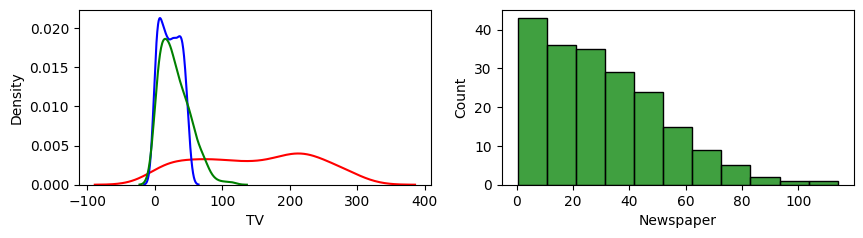

In [ ]:
plt.figure(figsize=(10,5))

plt.subplot(2,2,1)
sns.kdeplot(data["TV"], color ="red" , label="TV")
sns.kdeplot(data["Radio"], color="blue" , label="Radio")
sns.kdeplot(data["Newspaper"],color="green" , label="Newspaper")


plt.subplot(2,2,2)
#sns.histplot(data["TV"],color ="red" , label="TV")
#sns.histplot(data["Radio"],color="blue" , label="Radio")
sns.histplot(data["Newspaper"],color="green" , label="Newspaper")
plt.show()

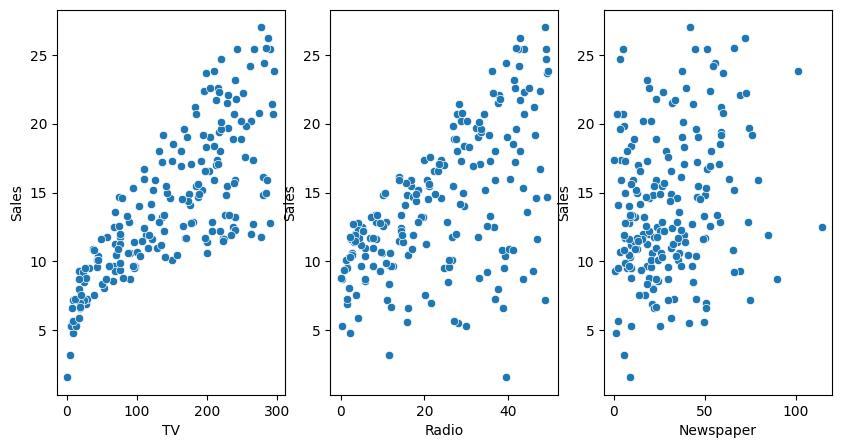

In [ ]:
plt.figure(figsize=(10,5))

plt.subplot(1,3,1)
sns.scatterplot(x=data["TV"],y=data["Sales"])

plt.subplot(1,3,2)
sns.scatterplot(x=data["Radio"],y=data["Sales"])

plt.subplot(1,3,3)
sns.scatterplot(x=data["Newspaper"],y=data["Sales"])
plt.show()

In [ ]:
data.corr()

,TV,Radio,Newspaper,Sales
TV,1.000000,0.054809,0.056648,0.782224
Radio,0.054809,1.000000,0.354104,0.576223
Newspaper,0.056648,0.354104,1.000000,0.228299
Sales,0.782224,0.576223,0.228299,1.000000


<Axes: >

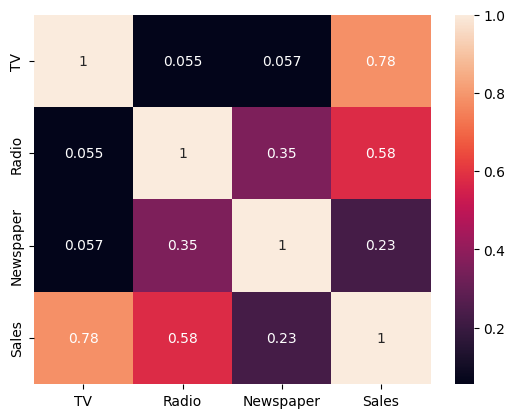

In [ ]:
sns.heatmap(data.corr(),annot=True)

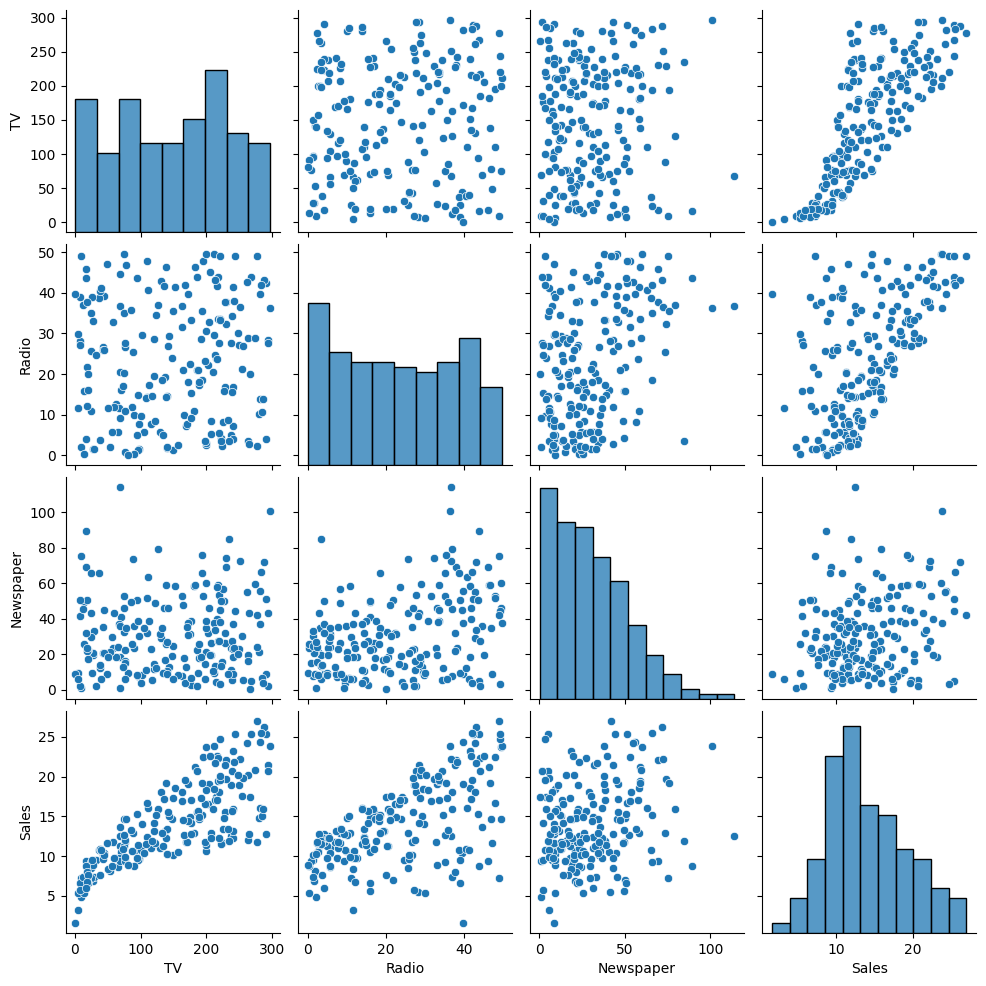

In [ ]:
sns.pairplot(data)

In [ ]:
X=data[["TV","Radio","Newspaper"]]
y=data["Sales"]

In [ ]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

# **LR model 1**

In [ ]:
from sklearn.linear_model import LinearRegression
model =LinearRegression()
lr1=model.fit(X_train, y_train)


In [ ]:
(model.coef_ ,model.intercept_)

(array([0.04472952, 0.18919505, 0.00276111]), 2.979067338122629)

In [ ]:
pd.DataFrame(model.coef_)

,0
0,0.044730
1,0.189195
2,0.002761


In [ ]:
y_hat=model.predict(X_test)

<Axes: xlabel='Sales'>

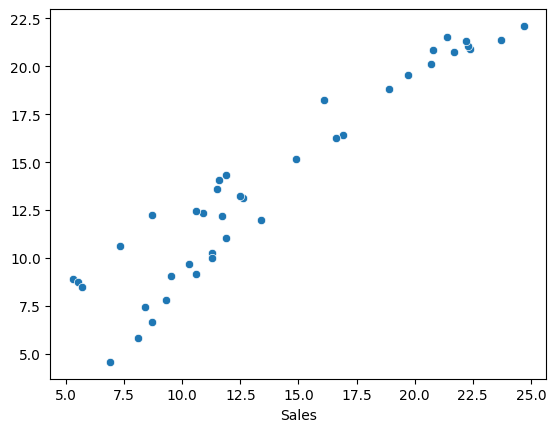

In [ ]:
sns.scatterplot(x=y_test,y=y_hat)

In [ ]:
y_train_hat=model.predict(X_train)

<Axes: xlabel='Sales'>

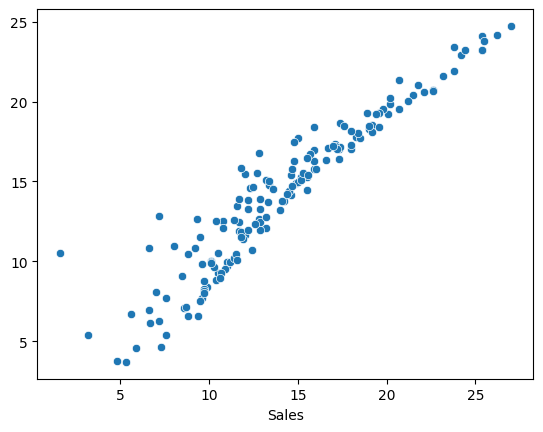

In [ ]:
sns.scatterplot(x=y_train,y=y_train_hat)

In [ ]:
lr.predict(X_train).shape

(160,)

In [ ]:
X_train.shape

(160, 3)

In [ ]:
model.score(X_test , y_test)

0.899438024100912

In [ ]:
model.score(X_train , y_train)

0.8957008271017818

Text(0, 0.5, 'Sales')

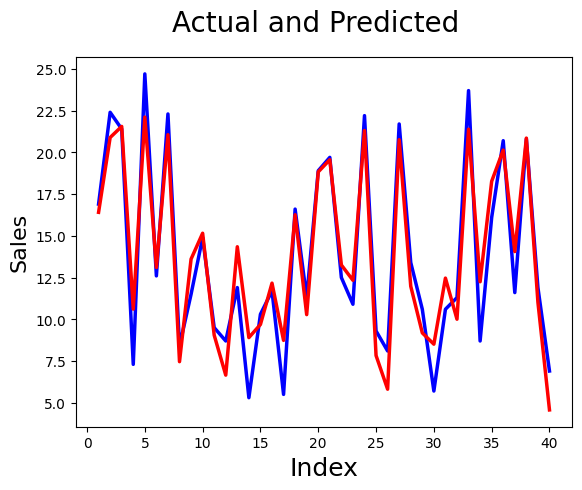

In [ ]:
c = [i for i in range(1,41,1)]
fig = plt.figure()
plt.plot(c,y_test, color="blue", linewidth=2.5, linestyle="-")
plt.plot(c,y_hat, color="red",  linewidth=2.5, linestyle="-")
fig.suptitle('Actual and Predicted', fontsize=20)              # Plot heading
plt.xlabel('Index', fontsize=18)                               # X-label
plt.ylabel('Sales', fontsize=16)

In [ ]:
import statsmodels.api as sm
X_train_sm=sm.add_constant(X_train)
lr_OLS=sm.OLS(y_train,X_train_sm)
lr_summary=lr_OLS.fit().summary()
print(lr_summary)

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.896
Model:                            OLS   Adj. R-squared:                  0.894
Method:                 Least Squares   F-statistic:                     446.6
Date:                Sat, 14 Dec 2024   Prob (F-statistic):           2.53e-76
Time:                        11:32:21   Log-Likelihood:                -306.64
No. Observations:                 160   AIC:                             621.3
Df Residuals:                     156   BIC:                             633.6
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          2.9791      0.354      8.427      0.0

TypeError: LinearRegression.fit() missing 2 required positional arguments: 'X' and 'y'

In [ ]:
import pandas as pd
df=pd.read_csv("mckinsey.csv")
type(df)
df.shape
df.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [ ]:
type(df["population"])
##every column of of pandas is a series data type

pandas.core.series.Series

In [ ]:
df[["population" , "continent"]]

,population,continent
0,8425333,Asia
1,9240934,Asia
2,10267083,Asia
3,11537966,Asia
4,13079460,Asia
...,...,...
1699,9216418,Africa
1700,10704340,Africa
1701,11404948,Africa
1702,11926563,Africa


In [ ]:
import numpy as np
d1=pd.Series([1,2,"Sravan" , "Puri"])
pd.DataFrame(d1)

,0
0,1
1,2
2,Sravan
3,Puri


we have 2 object type data points Country and continent

In [ ]:
pd.DataFrame([["Afghanistan" ,	"1952"	,"8425333"	,"Asia"	,"28.801"	,"779.445314"],
["Afghanistan","1957" ,	"9240934","	Asia" ,	"30.332","820.853030"] ,
["Afghanistan","1962" ,"10267083" ,"Asia"	,"31.997"	,"853.100710"]] , columns=["country","year","population","continent","life_exp","gdp_cap"])

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,\tAsia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710


In [ ]:
d=pd.DataFrame({"country": ["Afghanistan","Israel", "Australia","Nz"],
             "year" : ["1952" , "1957", "1900", "1800"],
             "population":[842533 ,9240934,12345 ,22334455],
              "continent":["Asia","Europe","Aus","Aus"]})

d.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   country     4 non-null      object
 1   year        4 non-null      object
 2   population  4 non-null      int64 
 3   continent   4 non-null      object
dtypes: int64(1), object(3)
memory usage: 260.0+ bytes


In [ ]:
#Basic operations on columns#
#Add a column
#aggregates on a column
#rename a column
#delete a column
#update the column

df.columns

Index(['country', 'year', 'population', 'continent', 'life_exp', 'gdp_cap'], dtype='object')

In [ ]:
round(df["population"].mean(),2)
df["year"].median()

df["year"].unique()
df["continent"].unique()

df.nunique()
#np.unique(df["continent"] , return_counts=True)

,0
country,142
year,12
population,1704
continent,5
life_exp,1626
gdp_cap,1704


In [ ]:
df["continent"].value_counts()
df["country"].value_counts()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1704 entries, 0 to 1703
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     1704 non-null   object 
 1   year        1704 non-null   int64  
 2   population  1704 non-null   int64  
 3   continent   1704 non-null   object 
 4   life_exp    1704 non-null   float64
 5   gdp_cap     1704 non-null   float64
dtypes: float64(2), int64(2), object(2)
memory usage: 80.0+ KB


In [ ]:
df.columns

Index(['country', 'year', 'population', 'continent', 'life_exp', 'gdp_cap'], dtype='object')

In [ ]:
df.columns=["a","b","c","d","e","f"]
df.columns=['country', 'year', 'population', 'continent', 'life_exp', 'gdp_cap']

In [ ]:
df.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


Renaming any specific column

In [ ]:
df.rename({
    "population":"pop",
    "continent" : "cont"
}, axis =1)

,country,year,pop,cont,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106
...,...,...,...,...,...,...
1699,Zimbabwe,1987,9216418,Africa,62.351,706.157306
1700,Zimbabwe,1992,10704340,Africa,60.377,693.420786
1701,Zimbabwe,1997,11404948,Africa,46.809,792.449960
1702,Zimbabwe,2002,11926563,Africa,39.989,672.038623


In [ ]:
df["year"].mean()

np.float64(1979.5)

In [ ]:
df.drop("year",axis=1)

,country,population,continent,life_exp,gdp_cap
0,Afghanistan,8425333,Asia,28.801,779.445314
1,Afghanistan,9240934,Asia,30.332,820.853030
2,Afghanistan,10267083,Asia,31.997,853.100710
3,Afghanistan,11537966,Asia,34.020,836.197138
4,Afghanistan,13079460,Asia,36.088,739.981106
...,...,...,...,...,...
1699,Zimbabwe,9216418,Africa,62.351,706.157306
1700,Zimbabwe,10704340,Africa,60.377,693.420786
1701,Zimbabwe,11404948,Africa,46.809,792.449960
1702,Zimbabwe,11926563,Africa,39.989,672.038623


In [ ]:
df.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [ ]:
###creating new columns

df["gdp"]=df["gdp_cap"]*df["population"]

mean_gdp=df["gdp"].mean()

df["gdp"]=abs((df["gdp"]-mean_gdp)/df["gdp"])

In [ ]:
df.head()

,country,year,population,continent,life_exp,gdp_cap,gdp
0,Afghanistan,1952,8425333,Asia,28.801,779.445314,27.446338
1,Afghanistan,1957,9240934,Asia,30.332,820.853030,23.627358
2,Afghanistan,1962,10267083,Asia,31.997,853.100710,20.328078
3,Afghanistan,1967,11537966,Asia,34.020,836.197138,18.362488
4,Afghanistan,1972,13079460,Asia,36.088,739.981106,18.301393


<Axes: xlabel='gdp', ylabel='Count'>

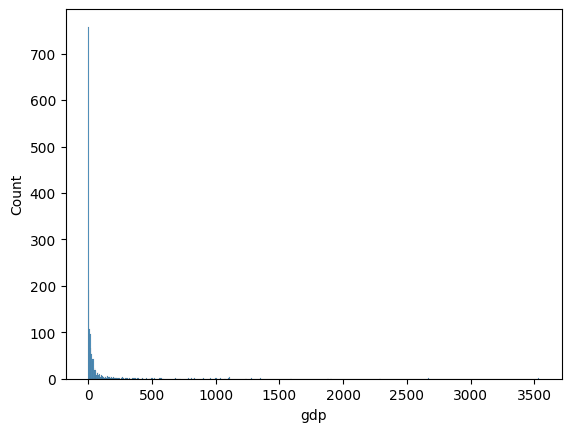

In [ ]:
import seaborn as sns
sns.histplot(df["gdp"])

In [ ]:
a=np.arange(1,100,10).reshape(5,-1)
print(a)
a_df=pd.DataFrame(a)

a_df.columns=["C1" , "C2"]

a_df



[[ 1 11]
 [21 31]
 [41 51]
 [61 71]
 [81 91]]


,C1,C2
0,1,11
1,21,31
2,41,51
3,61,71
4,81,91


In [ ]:
import numpy as np
import pandas as pd
arr=np.arange(1,100,10).reshape(2,5)
arr
df2=pd.DataFrame(arr)
df2
#df2.values

,0,1,2,3,4
0,1,11,21,31,41
1,51,61,71,81,91


In [ ]:
df.head()

df.index=np.arange(1.0, len(df)+1)
df

,country,year,population,continent,life_exp,gdp_cap,gdp
1.0,Afghanistan,1952,8425333,Asia,28.801,779.445314,27.446338
2.0,Afghanistan,1957,9240934,Asia,30.332,820.853030,23.627358
3.0,Afghanistan,1962,10267083,Asia,31.997,853.100710,20.328078
4.0,Afghanistan,1967,11537966,Asia,34.020,836.197138,18.362488
5.0,Afghanistan,1972,13079460,Asia,36.088,739.981106,18.301393
...,...,...,...,...,...,...,...
1700.0,Zimbabwe,1987,9216418,Africa,62.351,706.157306,27.703541
1701.0,Zimbabwe,1992,10704340,Africa,60.377,693.420786,24.167632
1702.0,Zimbabwe,1997,11404948,Africa,46.809,792.449960,19.669689
1703.0,Zimbabwe,2002,11926563,Africa,39.989,672.038623,22.307171


In [ ]:
a_df.index=np.arange(1,6)

##indexing and slicing : rows , dataframes

In [ ]:
##iloc implicit index
##loc explicit index
df.loc[1:3]

,country,year,population,continent,life_exp,gdp_cap,gdp
1.0,Afghanistan,1952,8425333,Asia,28.801,779.445314,27.446338
2.0,Afghanistan,1957,9240934,Asia,30.332,820.853030,23.627358
3.0,Afghanistan,1962,10267083,Asia,31.997,853.100710,20.328078


In [ ]:
df.iloc[1:3]

,country,year,population,continent,life_exp,gdp_cap,gdp
2.0,Afghanistan,1957,9240934,Asia,30.332,820.85303,23.627358
3.0,Afghanistan,1962,10267083,Asia,31.997,853.10071,20.328078


In [ ]:
df[["country" , "year"]]

,country,year
1.0,Afghanistan,1952
2.0,Afghanistan,1957
3.0,Afghanistan,1962
4.0,Afghanistan,1967
5.0,Afghanistan,1972
...,...,...
1700.0,Zimbabwe,1987
1701.0,Zimbabwe,1992
1702.0,Zimbabwe,1997
1703.0,Zimbabwe,2002


In [ ]:
df.iloc[[1,100,120]]

,country,year,population,continent,life_exp,gdp_cap,gdp
2.0,Afghanistan,1957,9240934,Asia,30.332,820.853030,23.627358
101.0,Bangladesh,1972,70759295,Asia,45.252,630.233627,3.189035
121.0,Benin,1952,1738315,Africa,38.223,1062.752200,100.120360


In [ ]:
df.loc[[1,100,120]]

,country,year,population,continent,life_exp,gdp_cap,gdp
1.0,Afghanistan,1952,8425333,Asia,28.801,779.445314,27.446338
100.0,Bangladesh,1967,62821884,Asia,43.453,721.186086,3.123261
120.0,Belgium,2007,10392226,Europe,79.441,33692.605080,0.466474


In [ ]:
df.set_index("year").reset_index()

,year,country,population,continent,life_exp,gdp_cap,gdp
0,1952,Afghanistan,8425333,Asia,28.801,779.445314,27.446338
1,1957,Afghanistan,9240934,Asia,30.332,820.853030,23.627358
2,1962,Afghanistan,10267083,Asia,31.997,853.100710,20.328078
3,1967,Afghanistan,11537966,Asia,34.020,836.197138,18.362488
4,1972,Afghanistan,13079460,Asia,36.088,739.981106,18.301393
...,...,...,...,...,...,...,...
1699,1987,Zimbabwe,9216418,Africa,62.351,706.157306,27.703541
1700,1992,Zimbabwe,10704340,Africa,60.377,693.420786,24.167632
1701,1997,Zimbabwe,11404948,Africa,46.809,792.449960,19.669689
1702,2002,Zimbabwe,11926563,Africa,39.989,672.038623,22.307171


In [ ]:

df

,country,population,continent,life_exp,gdp_cap
year,,,,,
1952,Afghanistan,8425333,Asia,28.801,779.445314
1957,Afghanistan,9240934,Asia,30.332,820.853030
1962,Afghanistan,10267083,Asia,31.997,853.100710
1967,Afghanistan,11537966,Asia,34.020,836.197138
1972,Afghanistan,13079460,Asia,36.088,739.981106
...,...,...,...,...,...
1987,Zimbabwe,9216418,Africa,62.351,706.157306
1992,Zimbabwe,10704340,Africa,60.377,693.420786
1997,Zimbabwe,11404948,Africa,46.809,792.449960


In [ ]:
df.reset_index(drop=True , inplace =True)
df

,country,population,continent,life_exp,gdp_cap
0,Afghanistan,8425333,Asia,28.801,779.445314
1,Afghanistan,9240934,Asia,30.332,820.853030
2,Afghanistan,10267083,Asia,31.997,853.100710
3,Afghanistan,11537966,Asia,34.020,836.197138
4,Afghanistan,13079460,Asia,36.088,739.981106
...,...,...,...,...,...
1699,Zimbabwe,9216418,Africa,62.351,706.157306
1700,Zimbabwe,10704340,Africa,60.377,693.420786
1701,Zimbabwe,11404948,Africa,46.809,792.449960
1702,Zimbabwe,11926563,Africa,39.989,672.038623


In [ ]:
data=pd.read_csv("mckinsey.csv")
data.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [ ]:
data.shape

(1704, 6)

In [ ]:
data.drop_duplicates(inplace=True)

data.shape

(1704, 6)

In [ ]:
data.head()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106


In [ ]:
data.loc[0:5, "year":"life_exp"]

,year,population,continent,life_exp
0,1952,8425333,Asia,28.801
1,1957,9240934,Asia,30.332
2,1962,10267083,Asia,31.997
3,1967,11537966,Asia,34.020
4,1972,13079460,Asia,36.088
5,1977,14880372,Asia,38.438


In [ ]:
data.loc[0:5, ["year", "population" , "continent"]]

,year,population,continent
0,1952,8425333,Asia
1,1957,9240934,Asia
2,1962,10267083,Asia
3,1967,11537966,Asia
4,1972,13079460,Asia
5,1977,14880372,Asia


In [ ]:
data.iloc[1:10 , 3:]

,continent,life_exp,gdp_cap
1,Asia,30.332,820.853030
2,Asia,31.997,853.100710
3,Asia,34.020,836.197138
4,Asia,36.088,739.981106
5,Asia,38.438,786.113360
6,Asia,39.854,978.011439
7,Asia,40.822,852.395945
8,Asia,41.674,649.341395
9,Asia,41.763,635.341351


In [ ]:
data.sort_values("population")

,country,year,population,continent,life_exp,gdp_cap
1296,Sao Tome and Principe,1952,60011,Africa,46.471,879.583586
1297,Sao Tome and Principe,1957,61325,Africa,48.945,860.736903
420,Djibouti,1952,63149,Africa,34.812,2669.529475
1298,Sao Tome and Principe,1962,65345,Africa,51.893,1071.551119
1299,Sao Tome and Principe,1967,70787,Africa,54.425,1384.840593
...,...,...,...,...,...,...
707,India,2007,1110396331,Asia,64.698,2452.210407
296,China,1992,1164970000,Asia,68.690,1655.784158
297,China,1997,1230075000,Asia,70.426,2289.234136
298,China,2002,1280400000,Asia,72.028,3119.280896


In [ ]:
data.sort_values("population" , ascending =False)

,country,year,population,continent,life_exp,gdp_cap
299,China,2007,1318683096,Asia,72.961,4959.114854
298,China,2002,1280400000,Asia,72.028,3119.280896
297,China,1997,1230075000,Asia,70.426,2289.234136
296,China,1992,1164970000,Asia,68.690,1655.784158
707,India,2007,1110396331,Asia,64.698,2452.210407
...,...,...,...,...,...,...
1299,Sao Tome and Principe,1967,70787,Africa,54.425,1384.840593
1298,Sao Tome and Principe,1962,65345,Africa,51.893,1071.551119
420,Djibouti,1952,63149,Africa,34.812,2669.529475
1297,Sao Tome and Principe,1957,61325,Africa,48.945,860.736903


In [ ]:
data.loc[1:1000:100 , ["continent" , "life_exp"]]

,continent,life_exp
1,Asia,30.332
101,Asia,46.923
201,Africa,50.324
301,Americas,55.118
401,Europe,70.710
501,Africa,53.378
601,Americas,44.142
701,Asia,54.208
801,Asia,80.690
901,Africa,45.289


In [ ]:
data.set_index("country").reset_index()

,country,year,population,continent,life_exp,gdp_cap
0,Afghanistan,1952,8425333,Asia,28.801,779.445314
1,Afghanistan,1957,9240934,Asia,30.332,820.853030
2,Afghanistan,1962,10267083,Asia,31.997,853.100710
3,Afghanistan,1967,11537966,Asia,34.020,836.197138
4,Afghanistan,1972,13079460,Asia,36.088,739.981106
...,...,...,...,...,...,...
1699,Zimbabwe,1987,9216418,Africa,62.351,706.157306
1700,Zimbabwe,1992,10704340,Africa,60.377,693.420786
1701,Zimbabwe,1997,11404948,Africa,46.809,792.449960
1702,Zimbabwe,2002,11926563,Africa,39.989,672.038623


https://www.google.com/url?q=https%3A%2F%2Fairlock-on-edge.woolf.university%2F%3Furl%3Dhttps%253A%252F%252Fscaler-production-new.s3.ap-southeast-1.amazonaws.com%252Fattachments%252Fattachments%252F000%252F029%252F471%252Foriginal%252FPandas3_IMDBInsights.ipynb___Colaboratory.pdf%253FX-Amz-Algorithm%253DAWS4-HMAC-SHA256%2526X-Amz-Credential%253DAKIAIDNNIRGHAQUQRWYA%25252F20240714%25252Fap-southeast-1%25252Fs3%25252Faws4_request%2526X-Amz-Date%253D20240714T114316Z%2526X-Amz-Expires%253D561600%2526X-Amz-SignedHeaders%253Dhost%2526X-Amz-Signature%253Dad7d7b1c7072c4ef2b4d17e26d86d284fd54351e5535adb54427c3c1b4b8531b%26resourceId%3Dc1e119e6-0184-4c54-b903-8e57151230d3%26studentId%3D2d856468-c511-41d6-8e2b-e11a659e4af2%26token%3DeyJhbGciOiJIUzI1NiJ9.eyJpZCI6IjJkODU2NDY4LWM1MTEtNDFkNi04ZTJiLWUxMWE2NTllNGFmMiIsImlzcyI6InVybjpXb29sZlVuaXZlcnNpdHk6c2VydmVyL3NlcnZpY2UvYWNjZXNzIiwiaXNWZXJpZmllZCI6dHJ1ZSwia2luZCI6Im9hdXRoIiwib3JnIjp7Imdyb3VwcyI6W10sImlkIjoiOWIxN2Y1Y2UtMTA3OC00ZmRmLWFlYzAtMDJiZjRlY2ZiMGE2In0sInNjb3BlIjoiKiJ9.J8V26ZjTOjuIGa5V3FHTEch9KIlrIiS_hl6DiUNkD4M

In [ ]:
users = pd.DataFrame({"userid":[1, 2, 3], "name":["sharadh", "shahid", "khusalli"]})
users

,userid,name
0,1,sharadh
1,2,shahid
2,3,khusalli


In [ ]:
msgs = pd.DataFrame({"userid":[1, 1, 2, 4], "msg":['hmm', "acha", "theek hai", "nice"]})
msgs

,userid,msg
0,1,hmm
1,1,acha
2,2,theek hai
3,4,nice


In [ ]:
users.merge(msgs , on ="userid" , how="inner")

,userid,name,msg
0,1,sharadh,hmm
1,1,sharadh,acha
2,2,shahid,theek hai


In [ ]:
users.merge(msgs , on ="userid" , how="outer")

,userid,name,msg
0,1,sharadh,hmm
1,1,sharadh,acha
2,2,shahid,theek hai
3,3,khusalli,NaN
4,4,NaN,nice


In [ ]:
users.rename(columns={"userid":"id"},inplace=True)

In [ ]:
users.merge(msgs , left_on ="id" , right_on ="userid" , how="outer")

,id,name,userid,msg
0,1.0,sharadh,1.0,hmm
1,1.0,sharadh,1.0,acha
2,2.0,shahid,2.0,theek hai
3,3.0,khusalli,NaN,NaN
4,NaN,NaN,4.0,nice


In [ ]:
!gdown https://www.google.com/url?q=https%3A%2F%2Fdrive.google.com%2Ffile%2Fd%2F1s2TkjSpzNc4SyxqRrQleZyDIHlc7bxnd%2Fview%3Fusp%3Dsharing

Downloading...
From: https://www.google.com/url?q=https%3A%2F%2Fdrive.google.com%2Ffile%2Fd%2F1s2TkjSpzNc4SyxqRrQleZyDIHlc7bxnd%2Fview%3Fusp%3Dsharing
To: /content/url?q=https%3A%2F%2Fdrive.google.com%2Ffile%2Fd%2F1s2TkjSpzNc4SyxqRrQleZyDIHlc7bxnd%2Fview%3Fusp%3Dsharing
48.8kB [00:00, 56.3MB/s]


In [ ]:
!gdown 1s2TkjSpzNc4SyxqRrQleZyDIHlc7bxnd


Downloading...
From: https://drive.google.com/uc?id=1s2TkjSpzNc4SyxqRrQleZyDIHlc7bxnd
To: /content/movies.csv
100% 112k/112k [00:00<00:00, 4.03MB/s]


In [ ]:
!gdown 1Ws-_s1fHZ9nHfGLVUQurbHDvStePlEJm

Downloading...
From: https://drive.google.com/uc?id=1Ws-_s1fHZ9nHfGLVUQurbHDvStePlEJm
To: /content/directors.csv
100% 65.4k/65.4k [00:00<00:00, 3.70MB/s]


In [ ]:
movies= pd.read_csv("movies.csv")
directors=pd.read_csv("directors.csv")

In [ ]:
movies.head()

,Unnamed: 0,id,budget,popularity,revenue,title,vote_average,vote_count,director_id,year,month,day
0,0,43597,237000000,150,2787965087,Avatar,7.2,11800,4762,2009,Dec,Thursday
1,1,43598,300000000,139,961000000,Pirates of the Caribbean: At World's End,6.9,4500,4763,2007,May,Saturday
2,2,43599,245000000,107,880674609,Spectre,6.3,4466,4764,2015,Oct,Monday
3,3,43600,250000000,112,1084939099,The Dark Knight Rises,7.6,9106,4765,2012,Jul,Monday
4,5,43602,258000000,115,890871626,Spider-Man 3,5.9,3576,4767,2007,May,Tuesday


In [ ]:
directors.head()

,Unnamed: 0,director_name,id,gender
0,0,James Cameron,4762,Male
1,1,Gore Verbinski,4763,Male
2,2,Sam Mendes,4764,Male
3,3,Christopher Nolan,4765,Male
4,4,Andrew Stanton,4766,Male


In [ ]:
movies.columns

Index(['Unnamed: 0', 'id', 'budget', 'popularity', 'revenue', 'title',
       'vote_average', 'vote_count', 'director_id', 'year', 'month', 'day'],
      dtype='object')

In [ ]:
movies.drop("Unnamed: 0" , axis=1 , inplace=True)
directors.drop("Unnamed: 0" , axis=1 , inplace=True)

In [ ]:
movies.info() , directors.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   id            1465 non-null   int64  
 1   budget        1465 non-null   int64  
 2   popularity    1465 non-null   int64  
 3   revenue       1465 non-null   int64  
 4   title         1465 non-null   object 
 5   vote_average  1465 non-null   float64
 6   vote_count    1465 non-null   int64  
 7   director_id   1465 non-null   int64  
 8   year          1465 non-null   int64  
 9   month         1465 non-null   object 
 10  day           1465 non-null   object 
dtypes: float64(1), int64(7), object(3)
memory usage: 126.0+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2349 entries, 0 to 2348
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   director_name  2349 non-null   object
 1   id             2349 non-null  

(None, None)

In [ ]:
movies["budget"]=movies["budget"]/1000000

In [ ]:
movies["revenue"]=movies["revenue"]/1000000

In [ ]:
movies.head()

,id,budget,popularity,revenue,title,vote_average,vote_count,director_id,year,month,day
0,43597,237.0,150,2787.965087,Avatar,7.2,11800,4762,2009,Dec,Thursday
1,43598,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,4763,2007,May,Saturday
2,43599,245.0,107,880.674609,Spectre,6.3,4466,4764,2015,Oct,Monday
3,43600,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,4765,2012,Jul,Monday
4,43602,258.0,115,890.871626,Spider-Man 3,5.9,3576,4767,2007,May,Tuesday


In [ ]:
movies.shape , directors.shape

((1465, 10), (2349, 3))

In [ ]:
movies.drop("id" , axis=1 , inplace=True)

In [ ]:
com=movies.merge(directors , left_on="director_id" , right_on="id" , how ="inner")

In [ ]:
movies["director_id"].nunique()

199

In [ ]:
directors["id"].nunique()

2349

In [ ]:
com["id"].nunique()

199

In [ ]:
com["director_id"].nunique()

199

In [ ]:
com.shape

(1465, 13)

In [ ]:
len(com["director_id"].unique())


199

In [ ]:
movies[movies["director_id"].isin(directors["id"])]

,budget,popularity,revenue,title,vote_average,vote_count,director_id,year,month,day
0,237.000,150,2787.965087,Avatar,7.2,11800,4762,2009,Dec,Thursday
1,300.000,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,4763,2007,May,Saturday
2,245.000,107,880.674609,Spectre,6.3,4466,4764,2015,Oct,Monday
3,250.000,112,1084.939099,The Dark Knight Rises,7.6,9106,4765,2012,Jul,Monday
4,258.000,115,890.871626,Spider-Man 3,5.9,3576,4767,2007,May,Tuesday
...,...,...,...,...,...,...,...,...,...,...
1460,0.000,3,0.321952,The Last Waltz,7.9,64,4809,1978,May,Monday
1461,0.027,19,3.151130,Clerks,7.4,755,5369,1994,Sep,Tuesday
1462,0.000,7,0.000000,Rampage,6.0,131,5148,2009,Aug,Friday
1463,0.000,3,0.000000,Slacker,6.4,77,5535,1990,Jul,Friday


In [ ]:
a,b=np.unique(movies["director_id"] , return_counts=True)

In [ ]:
np.sum(b)

np.int64(1465)

how to check if all values are there inside

In [ ]:
np.all(movies["director_id"].isin(directors["id"]))

np.True_

In [ ]:
data=movies.merge(directors , left_on="director_id" , right_on = "id" , how="left")

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,director_id,year,month,day,director_name,id,gender
0,237.0,150,2787.965087,Avatar,7.2,11800,4762,2009,Dec,Thursday,James Cameron,4762,Male
1,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,4763,2007,May,Saturday,Gore Verbinski,4763,Male
2,245.0,107,880.674609,Spectre,6.3,4466,4764,2015,Oct,Monday,Sam Mendes,4764,Male
3,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,4765,2012,Jul,Monday,Christopher Nolan,4765,Male
4,258.0,115,890.871626,Spider-Man 3,5.9,3576,4767,2007,May,Tuesday,Sam Raimi,4767,Male


In [ ]:
data.drop(["id" , "director_id"] ,axis=1, inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   budget         1465 non-null   float64
 1   popularity     1465 non-null   int64  
 2   revenue        1465 non-null   float64
 3   title          1465 non-null   object 
 4   vote_average   1465 non-null   float64
 5   vote_count     1465 non-null   int64  
 6   year           1465 non-null   int64  
 7   month          1465 non-null   object 
 8   day            1465 non-null   object 
 9   director_name  1465 non-null   object 
 10  gender         1341 non-null   object 
dtypes: float64(3), int64(3), object(5)
memory usage: 126.0+ KB


In [ ]:
data.describe()

,budget,popularity,revenue,vote_average,vote_count,year
count,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000,1465.000000
mean,48.022947,30.855973,143.253923,6.368191,1146.396587,2002.615017
std,49.355407,34.845214,206.491787,0.818033,1578.077438,8.680141
min,0.000000,0.000000,0.000000,3.000000,1.000000,1976.000000
25%,14.000000,11.000000,17.380126,5.900000,216.000000,1998.000000
50%,33.000000,23.000000,75.781642,6.400000,571.000000,2004.000000
75%,66.000000,41.000000,179.246868,6.900000,1387.000000,2009.000000
max,380.000000,724.000000,2787.965087,8.300000,13752.000000,2016.000000


In [ ]:
data["new"]=data["revenue"]-data["budget"]

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new
0,237.0,150,2787.965087,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087
1,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000
2,245.0,107,880.674609,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609
3,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099
4,258.0,115,890.871626,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626


In [ ]:
def fun(x):
  return x["revenue"]-x["budget"]


#data["new"]=data[["revenue" , "budget"]].apply(fun , axis=1)
data["new"]=data.apply(fun , axis=1)

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new
0,237.0,150,2787.965087,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087
1,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000
2,245.0,107,880.674609,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609
3,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099
4,258.0,115,890.871626,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626


In [ ]:
dir=data.groupby("director_name")["budget"].aggregate(["mean","max"]).reset_index()
dir

,director_name,mean,max
0,Adam McKay,56.916667,100.0
1,Adam Shankman,48.375000,80.0
2,Alejandro González Iñárritu,33.333333,135.0
3,Alex Proyas,70.400000,140.0
4,Alexander Payne,15.600000,30.0
...,...,...,...
194,Wes Craven,23.380000,40.0
195,Wolfgang Petersen,90.142857,175.0
196,Woody Allen,11.777778,30.0
197,Zack Snyder,122.857143,250.0


In [ ]:
dir.sort_values("mean", ascending=False)

,director_name,mean,max
62,Gore Verbinski,158.142857,300.0
25,Bryan Singer,144.875000,270.0
142,Peter Jackson,143.666667,250.0
153,Rob Marshall,128.000000,380.0
30,Christopher Nolan,125.625000,250.0
...,...,...,...
36,Darren Lynn Bousman,4.800000,10.0
190,Tyler Perry,4.555556,20.0
121,Michael Polish,4.200000,13.0
69,James Ivory,4.071429,14.0


In [ ]:
dir=data.groupby("director_name")["vote_average"].aggregate(["mean","max"]).reset_index()

dir

,director_name,mean,max
0,Adam McKay,6.466667,7.3
1,Adam Shankman,6.037500,7.5
2,Alejandro González Iñárritu,7.233333,7.6
3,Alex Proyas,6.480000,7.3
4,Alexander Payne,6.880000,7.4
...,...,...,...
194,Wes Craven,5.950000,7.2
195,Wolfgang Petersen,6.571429,7.9
196,Woody Allen,6.672222,7.8
197,Zack Snyder,6.485714,7.0


In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new
0,237.0,150,2787.965087,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087
1,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000
2,245.0,107,880.674609,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609
3,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099
4,258.0,115,890.871626,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626


In [ ]:
data.groupby("month")["budget"].aggregate("mean").reset_index()

,month,budget
0,Apr,42.617222
1,Aug,38.820541
2,Dec,51.094819
3,Feb,37.429346
4,Jan,25.636667
5,Jul,64.980197
6,Jun,68.149666
7,Mar,48.346061
8,May,71.499569
9,Nov,62.581726


In [ ]:
def f(x):
  return x["vote_count"]/x["vote_average"]
data["add"]=data.apply(f , axis=1)


data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,237.0,150,2787.965087,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,300.0,139,961.000000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,245.0,107,880.674609,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,250.0,112,1084.939099,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
4,258.0,115,890.871626,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695


In [ ]:
def ff(x):
  return x/10

data["revenue"]=data["revenue"].apply(ff)

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,237.0,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,300.0,139,96.100000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,245.0,107,88.067461,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,250.0,112,108.493910,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
4,258.0,115,89.087163,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695


# **Group based Filtering**

In [ ]:
data.groupby("director_name").filter(lambda x : x["budget"].max()>100)

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,237.00,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,300.00,139,96.100000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,245.00,107,88.067461,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,250.00,112,108.493910,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
4,258.00,115,89.087163,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1450,0.40,33,10.000000,Mad Max,6.6,1213,1979,Apr,Thursday,George Miller,Male,99.600000,183.787879
1451,0.20,13,0.450592,Swingers,6.8,253,1996,Oct,Friday,Doug Liman,Male,4.305922,37.205882
1452,0.00,5,0.261155,Three,6.3,31,2010,Dec,Thursday,Tom Tykwer,Male,2.611555,4.920635
1458,0.06,27,0.322115,Pi,7.1,586,1998,Jul,Friday,Darren Aronofsky,Male,3.161152,82.535211


filter year > 2000 and also per director

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1465 entries, 0 to 1464
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   budget         1465 non-null   float64
 1   popularity     1465 non-null   int64  
 2   revenue        1465 non-null   float64
 3   title          1465 non-null   object 
 4   vote_average   1465 non-null   float64
 5   vote_count     1465 non-null   int64  
 6   year           1465 non-null   int64  
 7   month          1465 non-null   object 
 8   day            1465 non-null   object 
 9   director_name  1465 non-null   object 
 10  gender         1341 non-null   object 
 11  new            1465 non-null   float64
 12  add            1465 non-null   float64
dtypes: float64(5), int64(3), object(5)
memory usage: 148.9+ KB


In [ ]:
def year_func(x):
  return x["year"].mean()<2000
data.groupby("director_name").filter(year_func)

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,237.00,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
4,258.00,115,89.087163,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695
13,225.00,52,62.402678,Men in Black 3,6.2,4160,2012,May,Wednesday,Barry Sonnenfeld,Male,399.026776,670.967742
19,200.00,100,184.503419,Titanic,7.5,7562,1997,Nov,Tuesday,James Cameron,Male,1645.034188,1008.266667
22,200.00,35,78.376634,Spider-Man 2,6.7,4321,2004,Jun,Friday,Sam Raimi,Male,583.766341,644.925373
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1443,0.35,35,2.940000,The Evil Dead,7.3,894,1981,Oct,Thursday,Sam Raimi,Male,29.050000,122.465753
1450,0.40,33,10.000000,Mad Max,6.6,1213,1979,Apr,Thursday,George Miller,Male,99.600000,183.787879
1453,0.00,6,0.000000,She's Gotta Have It,6.1,25,1986,Aug,Friday,Spike Lee,Male,0.000000,4.098361
1456,0.01,20,0.700000,Eraserhead,7.5,485,1977,Mar,Saturday,David Lynch,Male,6.990000,64.666667


# **Apply function**

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,237.0,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,300.0,139,96.100000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,245.0,107,88.067461,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,250.0,112,108.493910,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
4,258.0,115,89.087163,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695


In [ ]:
data["budget"]=data["budget"].apply(lambda x : x*10)

In [ ]:
data.head()

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,2370.0,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,3000.0,139,96.100000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,2450.0,107,88.067461,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,2500.0,112,108.493910,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
4,2580.0,115,89.087163,Spider-Man 3,5.9,3576,2007,May,Tuesday,Sam Raimi,Male,632.871626,606.101695


In [ ]:
data["budget"]=data["budget"].apply(lambda x : x*10)

In [ ]:
data.groupby("director_name")["budget"].aggregate(["mean", "max" , "min"])

,mean,max,min
director_name,,,
Adam McKay,5691.666667,10000.0,2600.0
Adam Shankman,4837.500000,8000.0,1100.0
Alejandro González Iñárritu,3333.333333,13500.0,0.0
Alex Proyas,7040.000000,14000.0,1500.0
Alexander Payne,1560.000000,3000.0,0.0
...,...,...,...
Wes Craven,2338.000000,4000.0,180.0
Wolfgang Petersen,9014.285714,17500.0,1400.0
Woody Allen,1177.777778,3000.0,0.0


In [ ]:
data.groupby("director_name").filter(lambda x : x["revenue"].max()>100)

,budget,popularity,revenue,title,vote_average,vote_count,year,month,day,director_name,gender,new,add
0,23700.0,150,278.796509,Avatar,7.2,11800,2009,Dec,Thursday,James Cameron,Male,2550.965087,1638.888889
1,30000.0,139,96.100000,Pirates of the Caribbean: At World's End,6.9,4500,2007,May,Saturday,Gore Verbinski,Male,661.000000,652.173913
2,24500.0,107,88.067461,Spectre,6.3,4466,2015,Oct,Monday,Sam Mendes,Male,635.674609,708.888889
3,25000.0,112,108.493910,The Dark Knight Rises,7.6,9106,2012,Jul,Monday,Christopher Nolan,Male,834.939099,1198.157895
8,20000.0,145,106.565981,Pirates of the Caribbean: Dead Man's Chest,7.0,5246,2006,Jun,Tuesday,Gore Verbinski,Male,865.659812,749.428571
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1337,500.0,48,0.000000,Insidious: Chapter 2,6.5,1211,2013,Sep,Thursday,James Wan,Male,-5.000000,186.307692
1341,900.0,60,3.972310,Memento,8.1,4028,2000,Oct,Wednesday,Christopher Nolan,Male,30.723096,497.283951
1348,500.0,8,0.304914,Heavenly Creatures,7.0,294,1994,Sep,Friday,Peter Jackson,Male,-1.950865,42.000000
1417,150.0,58,9.700915,Insidious,6.8,1737,2010,Sep,Monday,James Wan,Male,95.509150,255.441176


In [ ]:
d=data.groupby("director_name").filter(lambda x : x["revenue"].mean()>8)

In [ ]:
d["director_name"].value_counts()

,count
director_name,
Steven Spielberg,26
Martin Scorsese,19
Clint Eastwood,19
Ridley Scott,16
Steven Soderbergh,15
...,...
Anne Fletcher,5
Nicholas Stoller,5
Jason Reitman,5


In [ ]:
def func(x):
  x["risky"]=x["budget"]-x["revenue"].mean()>0
  return x


data.groupby("director_name").apply(func)

/tmp/ipython-input-3259508336.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data.groupby("director_name").apply(func)


budget  popularity    revenue  \
director_name                                          
Adam McKay    176   10000.000          24  17.043293   
              323    7250.000          12  16.296618   
              366    6500.000          22  12.810764   
              505    5000.000          38  17.364901   
              839    2800.000          57  13.334651   
...                       ...         ...        ...   
Zhang Yimou   590       0.011           9   0.000000   
              604    3100.000          23  17.739443   
              1217      0.000          21   9.286395   
              1223      0.000           1   0.000000   
              1389      0.000           6   0.000000   

                                                          title  vote_average  \
director_name                                                                   
Adam McKay    176                                The Other Guys           6.1   
              323   Talladega Nights: The Ballad of Ricky Bobby           6.2   
              366                                 Step Brothers           6.5   
              505             Anchorman 2: The Legend Continues           6.0   
              839                                 The Big Short           7.3   
...                                                         ...           ...   
Zhang Yimou   590                    Curse of the Golden Flower           6.6   
              604                                          Hero           7.2   
              1217                      House of Flying Daggers           7.1   
              1223             A Woman, a Gun and a Noodle Shop           4.8   
              1389                                  Coming Home           6.9   

                    vote_count  year month        day director_name gender  \
director_name                                                                
Adam McKay    176         1383  2010   Aug     Friday    Adam McKay   Male   
              323          491  2006   Aug     Friday    Adam McKay   Male   
              366         1062  2008   Jul     Friday    Adam McKay   Male   
              505          923  2013   Dec  Wednesday    Adam McKay   Male   
              839         2607  2015   Dec     Friday    Adam McKay   Male   
...                        ...   ...   ...        ...           ...    ...   
Zhang Yimou   590          203  2006   Dec   Thursday   Zhang Yimou   Male   
              604          635  2002   Dec   Thursday   Zhang Yimou   Male   
              1217         439  2004   May  Wednesday   Zhang Yimou   Male   
              1223          13  2009   Dec     Friday   Zhang Yimou   Male   
              1389          49  2014   May     Friday   Zhang Yimou   Male   

                           new         add  risky  
director_name                                      
Adam McKay    176    70.432927  226.721311   True  
              323    90.466177   79.193548   True  
              366    63.107642  163.384615   True  
              505   123.649015  153.833333   True  
              839   105.346506  357.123288   True  
...                        ...         ...    ...  
Zhang Yimou   590    -0.000110   30.757576  False  
              604   146.394432   88.194444   True  
              1217   92.863945   61.830986  False  
              1223    0.000000    2.708333  False  
              1389    0.000000    7.101449  False  

[1465 rows x 14 columns]

In [ ]:

data["mean"]=data.groupby("month")["revenue"].apply(lambda x : x["revenue"].mean())

KeyError: 'revenue'

In [ ]:
def func(x):
  x["risky"]=x["budget"]-x["revenue"].mean()>0
  return x


data.groupby("director_name").apply(func)

/tmp/ipython-input-3259508336.py:6: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  data.groupby("director_name").apply(func)


budget  popularity    revenue  \
director_name                                          
Adam McKay    176   10000.000          24  17.043293   
              323    7250.000          12  16.296618   
              366    6500.000          22  12.810764   
              505    5000.000          38  17.364901   
              839    2800.000          57  13.334651   
...                       ...         ...        ...   
Zhang Yimou   590       0.011           9   0.000000   
              604    3100.000          23  17.739443   
              1217      0.000          21   9.286395   
              1223      0.000           1   0.000000   
              1389      0.000           6   0.000000   

                                                          title  vote_average  \
director_name                                                                   
Adam McKay    176                                The Other Guys           6.1   
              323   Talladega Nights: The Ballad of Ricky Bobby           6.2   
              366                                 Step Brothers           6.5   
              505             Anchorman 2: The Legend Continues           6.0   
              839                                 The Big Short           7.3   
...                                                         ...           ...   
Zhang Yimou   590                    Curse of the Golden Flower           6.6   
              604                                          Hero           7.2   
              1217                      House of Flying Daggers           7.1   
              1223             A Woman, a Gun and a Noodle Shop           4.8   
              1389                                  Coming Home           6.9   

                    vote_count  year month        day director_name gender  \
director_name                                                                
Adam McKay    176         1383  2010   Aug     Friday    Adam McKay   Male   
              323          491  2006   Aug     Friday    Adam McKay   Male   
              366         1062  2008   Jul     Friday    Adam McKay   Male   
              505          923  2013   Dec  Wednesday    Adam McKay   Male   
              839         2607  2015   Dec     Friday    Adam McKay   Male   
...                        ...   ...   ...        ...           ...    ...   
Zhang Yimou   590          203  2006   Dec   Thursday   Zhang Yimou   Male   
              604          635  2002   Dec   Thursday   Zhang Yimou   Male   
              1217         439  2004   May  Wednesday   Zhang Yimou   Male   
              1223          13  2009   Dec     Friday   Zhang Yimou   Male   
              1389          49  2014   May     Friday   Zhang Yimou   Male   

                           new         add  risky  
director_name                                      
Adam McKay    176    70.432927  226.721311   True  
              323    90.466177   79.193548   True  
              366    63.107642  163.384615   True  
              505   123.649015  153.833333   True  
              839   105.346506  357.123288   True  
...                        ...         ...    ...  
Zhang Yimou   590    -0.000110   30.757576  False  
              604   146.394432   88.194444   True  
              1217   92.863945   61.830986  False  
              1223    0.000000    2.708333  False  
              1389    0.000000    7.101449  False  

[1465 rows x 14 columns]

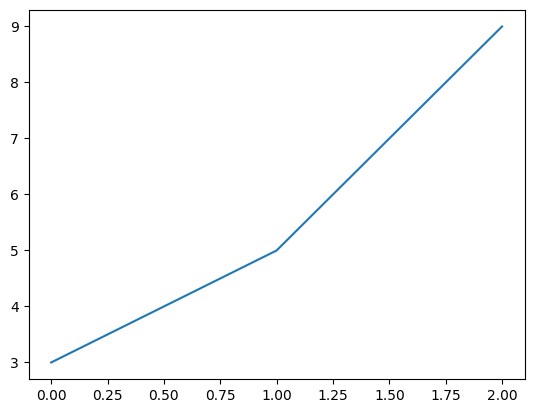

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

x=[0,1,2]
y=[3,5,9]
plt.plot(x,y)

In [ ]:
!wget https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/021/299/original/final_vg1_-_final_vg_%281%29.csv?1670840166 -O final_vg.csv

--2025-09-24 01:50:06--  https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/021/299/original/final_vg1_-_final_vg_%281%29.csv?1670840166
Resolving d2beiqkhq929f0.cloudfront.net (d2beiqkhq929f0.cloudfront.net)... 13.225.41.5, 13.225.41.18, 13.225.41.124, ...
Connecting to d2beiqkhq929f0.cloudfront.net (d2beiqkhq929f0.cloudfront.net)|13.225.41.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 2041483 (1.9M) [text/plain]
Saving to: ‘final_vg.csv’

final_vg.csv        100%[===================>]   1.95M  --.-KB/s    in 0.07s   

2025-09-24 01:50:07 (26.8 MB/s) - ‘final_vg.csv’ saved [2041483/2041483]



In [ ]:
import pandas as pd
data=pd.read_csv("final_vg.csv")

data

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,2061,1942,NES,1985.0,Shooter,Capcom,4.569217,3.033887,3.439352,1.991671,12.802935
1,9137,¡Shin Chan Flipa en colores!,DS,2007.0,Platform,505 Games,2.076955,1.493442,3.033887,0.394830,7.034163
2,14279,.hack: Sekai no Mukou ni + Versus,PS3,2012.0,Action,Namco Bandai Games,1.145709,1.762339,1.493442,0.408693,4.982552
3,8359,.hack//G.U. Vol.1//Rebirth,PS2,2006.0,Role-Playing,Namco Bandai Games,2.031986,1.389856,3.228043,0.394830,7.226880
4,7109,.hack//G.U. Vol.2//Reminisce,PS2,2006.0,Role-Playing,Namco Bandai Games,2.792725,2.592054,1.440483,1.493442,8.363113
...,...,...,...,...,...,...,...,...,...,...,...
16647,7925,Zumba Fitness Rush,X360,2012.0,Sports,505 Games,4.409308,3.167419,4.168474,1.087977,13.053204
16648,6279,Zumba Fitness: World Party,Wii,2013.0,Misc,Majesco Entertainment,3.033887,2.792725,1.596852,1.493442,8.878837
16649,6977,Zumba Fitness: World Party,XOne,2013.0,Misc,Majesco Entertainment,3.228043,2.004268,1.833151,1.087977,7.954274
16650,15422,Zwei!!,PSP,2008.0,Role-Playing,Falcom Corporation,1.087977,0.592445,1.087977,0.394830,3.509168


In [ ]:
cat_counts=data["Genre"].value_counts().reset_index()
cat_counts

,Genre,count
0,Action,3316
1,Sports,2400
2,Misc,1739
3,Role-Playing,1488
4,Shooter,1310
5,Adventure,1286
6,Racing,1249
7,Platform,886
8,Simulation,867
9,Fighting,848


<BarContainer object of 12 artists>

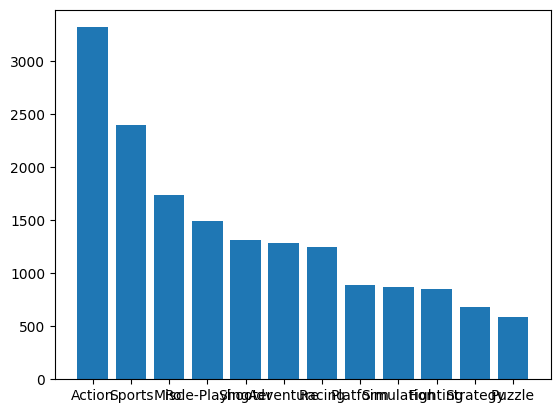

In [ ]:
plt.bar(cat_counts["Genre"] , cat_counts["count"])

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
data.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,2061,1942,NES,1985.0,Shooter,Capcom,4.569217,3.033887,3.439352,1.991671,12.802935
1,9137,¡Shin Chan Flipa en colores!,DS,2007.0,Platform,505 Games,2.076955,1.493442,3.033887,0.394830,7.034163
2,14279,.hack: Sekai no Mukou ni + Versus,PS3,2012.0,Action,Namco Bandai Games,1.145709,1.762339,1.493442,0.408693,4.982552
3,8359,.hack//G.U. Vol.1//Rebirth,PS2,2006.0,Role-Playing,Namco Bandai Games,2.031986,1.389856,3.228043,0.394830,7.226880
4,7109,.hack//G.U. Vol.2//Reminisce,PS2,2006.0,Role-Playing,Namco Bandai Games,2.792725,2.592054,1.440483,1.493442,8.363113


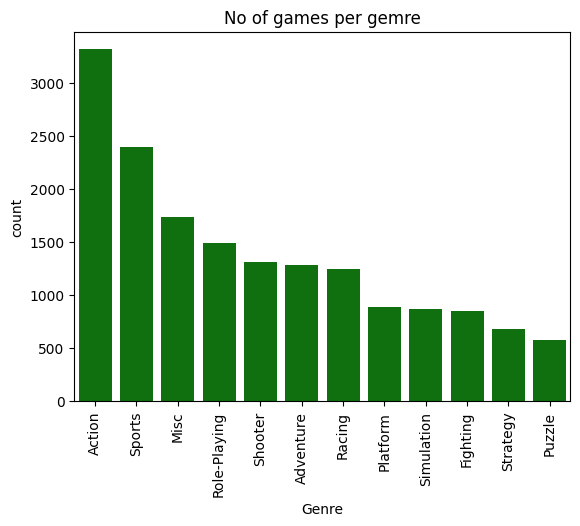

In [ ]:
sns.countplot(data=data , x="Genre" , color="green" , order=data["Genre"].value_counts().index)

plt.xticks(rotation=90)
plt.title("No of games per gemre")
plt.show()

<Axes: xlabel='Year', ylabel='Count'>

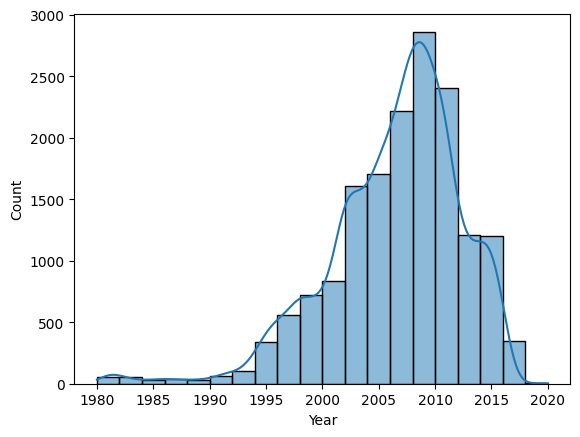

In [ ]:
sns.histplot(data["Year"], bins=20 , kde=True)

difference between hist and Kde plot is y axis has probability in kde plot

In [ ]:
data.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,2061,1942,NES,1985.0,Shooter,Capcom,4.569217,3.033887,3.439352,1.991671,12.802935
1,9137,¡Shin Chan Flipa en colores!,DS,2007.0,Platform,505 Games,2.076955,1.493442,3.033887,0.394830,7.034163
2,14279,.hack: Sekai no Mukou ni + Versus,PS3,2012.0,Action,Namco Bandai Games,1.145709,1.762339,1.493442,0.408693,4.982552
3,8359,.hack//G.U. Vol.1//Rebirth,PS2,2006.0,Role-Playing,Namco Bandai Games,2.031986,1.389856,3.228043,0.394830,7.226880
4,7109,.hack//G.U. Vol.2//Reminisce,PS2,2006.0,Role-Playing,Namco Bandai Games,2.792725,2.592054,1.440483,1.493442,8.363113


<Axes: xlabel='NA_Sales', ylabel='Count'>

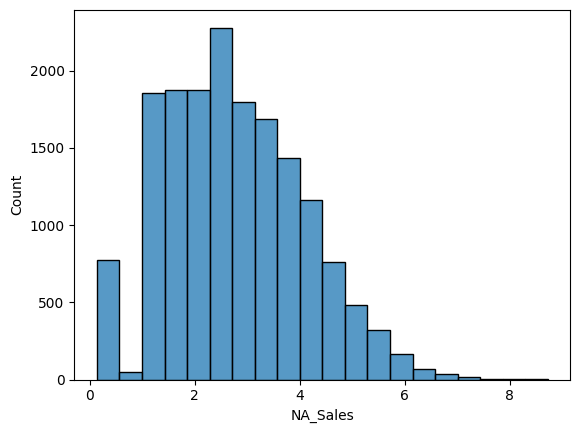

In [ ]:
sns.histplot(data["NA_Sales"] , bins=20)

In [ ]:
sales_data = data[['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']]
region_sales = sales_data.sum(axis=0)
region_sales

,0
NA_Sales,45831.525845
EU_Sales,33251.970702
JP_Sales,41624.625635
Other_Sales,19180.256828


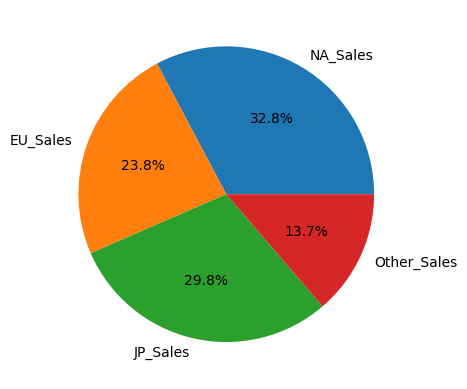

In [ ]:
plt.pie(region_sales , labels=region_sales.index , autopct="%1.1f%%")
plt.show()

<Axes: xlabel='Year', ylabel='Count'>

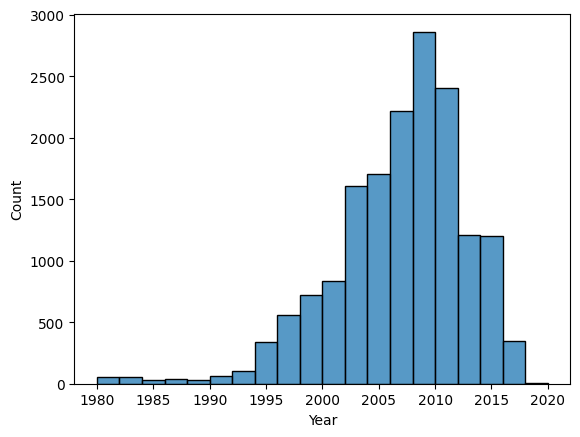

In [ ]:
sns.histplot(data=data , x="Year" , bins=20)

Univarianmt analysis bar plot , hist plot , kde , box plot



Bivariant analysis

line plot , scatter ploit

In [ ]:
data.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,2061,1942,NES,1985.0,Shooter,Capcom,4.569217,3.033887,3.439352,1.991671,12.802935
1,9137,¡Shin Chan Flipa en colores!,DS,2007.0,Platform,505 Games,2.076955,1.493442,3.033887,0.394830,7.034163
2,14279,.hack: Sekai no Mukou ni + Versus,PS3,2012.0,Action,Namco Bandai Games,1.145709,1.762339,1.493442,0.408693,4.982552
3,8359,.hack//G.U. Vol.1//Rebirth,PS2,2006.0,Role-Playing,Namco Bandai Games,2.031986,1.389856,3.228043,0.394830,7.226880
4,7109,.hack//G.U. Vol.2//Reminisce,PS2,2006.0,Role-Playing,Namco Bandai Games,2.792725,2.592054,1.440483,1.493442,8.363113


In [ ]:
data["Genre"].value_counts()

,count
Genre,
Action,3316
Sports,2400
Misc,1739
Role-Playing,1488
Shooter,1310
Adventure,1286
Racing,1249
Platform,886
Simulation,867


In [ ]:
data["Name"].value_counts()

,count
Name,
Ice Hockey,41
Baseball,17
Need for Speed: Most Wanted,12
Ratatouille,9
FIFA 14,9
...,...
Indy Racing 2000,1
Indycar Series 2005,1
inFAMOUS,1


In [ ]:
ih=data[data["Name"]=="Ice Hockey"]
Baseball=data[data["Name"]=="Baseball"]
NSP=data[data["Name"]=="Need for Speed: Most Wanted"]
# sns.lineplot(data="ih" , x="Year" , y="NA_Sales")
ih.info()

<class 'pandas.core.frame.DataFrame'>
Index: 41 entries, 6073 to 6113
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          41 non-null     int64  
 1   Name          41 non-null     object 
 2   Platform      41 non-null     object 
 3   Year          41 non-null     float64
 4   Genre         41 non-null     object 
 5   Publisher     41 non-null     object 
 6   NA_Sales      41 non-null     float64
 7   EU_Sales      41 non-null     float64
 8   JP_Sales      41 non-null     float64
 9   Other_Sales   41 non-null     float64
 10  Global_Sales  41 non-null     float64
dtypes: float64(6), int64(1), object(4)
memory usage: 3.8+ KB


<Axes: xlabel='Year', ylabel='NA_Sales'>

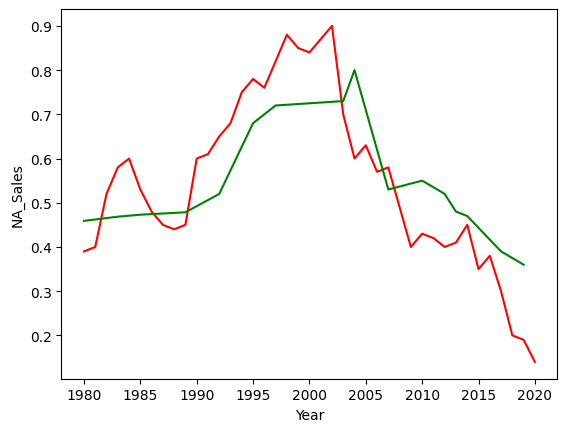

In [ ]:
sns.lineplot(data=ih , x="Year" , y="NA_Sales" , color ="red")
sns.lineplot(data=Baseball , x="Year" , y="NA_Sales" , color ="green")



<Axes: xlabel='Genre', ylabel='count'>

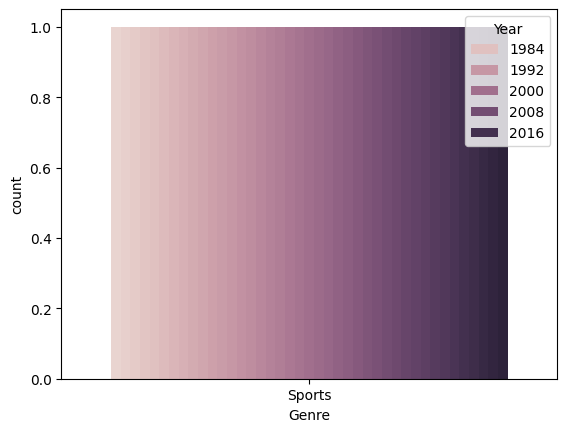

In [ ]:
sns.countplot(data=ih , x="Genre" , hue="Year")

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16652 entries, 0 to 16651
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16652 non-null  int64  
 1   Name          16652 non-null  object 
 2   Platform      16652 non-null  object 
 3   Year          16381 non-null  float64
 4   Genre         16652 non-null  object 
 5   Publisher     16594 non-null  object 
 6   NA_Sales      16652 non-null  float64
 7   EU_Sales      16652 non-null  float64
 8   JP_Sales      16652 non-null  float64
 9   Other_Sales   16652 non-null  float64
 10  Global_Sales  16652 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [ ]:
numerical_data = data.select_dtypes(include=np.number)
display(numerical_data.head())

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,2061,1985.0,4.569217,3.033887,3.439352,1.991671,12.802935
1,9137,2007.0,2.076955,1.493442,3.033887,0.394830,7.034163
2,14279,2012.0,1.145709,1.762339,1.493442,0.408693,4.982552
3,8359,2006.0,2.031986,1.389856,3.228043,0.394830,7.226880
4,7109,2006.0,2.792725,2.592054,1.440483,1.493442,8.363113


In [ ]:
numerical_data.corr()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
Rank,1.000000,0.179515,-0.846227,-0.784596,-0.332589,-0.755057,-0.883019
Year,0.179515,1.000000,-0.134140,-0.018786,-0.265222,0.049243,-0.123778
NA_Sales,-0.846227,-0.134140,1.000000,0.728037,0.268733,0.737128,0.892189
EU_Sales,-0.784596,-0.018786,0.728037,1.000000,0.155849,0.812978,0.884294
JP_Sales,-0.332589,-0.265222,0.268733,0.155849,1.000000,0.014897,0.460068
Other_Sales,-0.755057,0.049243,0.737128,0.812978,0.014897,1.000000,0.829061
Global_Sales,-0.883019,-0.123778,0.892189,0.884294,0.460068,0.829061,1.000000


<Axes: >

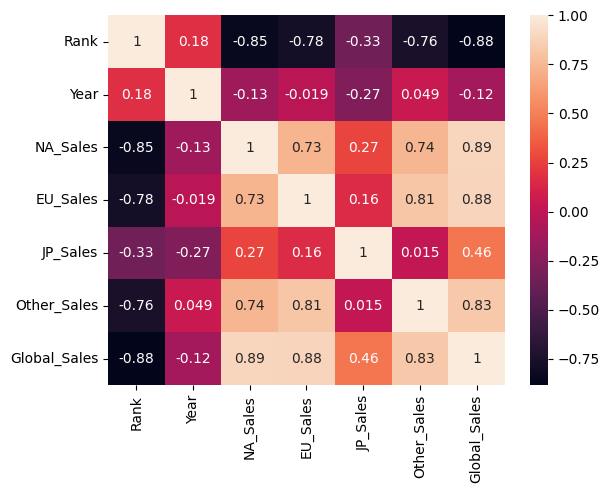

In [ ]:
sns.heatmap(numerical_data.corr() , annot=True)

In [ ]:
import pandas as pd
cars=pd.read_excel("cars24-car-price.xlsx")

In [ ]:
cars.head()

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,1.20,Maruti Alto Std,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5


In [ ]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19980 entries, 0 to 19979
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   selling_price      19980 non-null  float64
 1   full_name          19980 non-null  object 
 2   year               19980 non-null  int64  
 3   seller_type        19980 non-null  object 
 4   km_driven          19980 non-null  int64  
 5   fuel_type          19980 non-null  object 
 6   transmission_type  19980 non-null  object 
 7   mileage            19980 non-null  float64
 8   engine             19980 non-null  float64
 9   max_power          19980 non-null  float64
 10  seats              19980 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 1.7+ MB


###No Null values###

In [ ]:
cars.isnull().sum()

,0
selling_price,0
full_name,0
year,0
seller_type,0
km_driven,0
fuel_type,0
transmission_type,0
mileage,0
engine,0
max_power,0


In [ ]:
cars.columns

Index(['selling_price', 'full_name', 'year', 'seller_type', 'km_driven',
       'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power',
       'seats'],
      dtype='object')

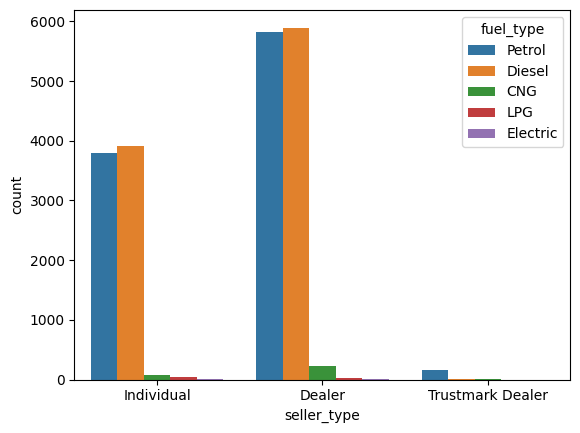

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
cars["seller_type"].value_counts()

sns.countplot(data=cars , x="seller_type" , hue="fuel_type")
plt.show()



Therefore petrol and diesel are the high majority of cars getting sold

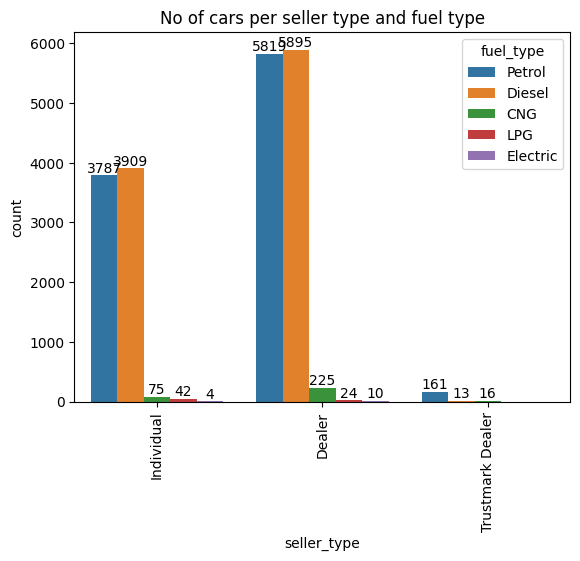

In [ ]:
ax = sns.countplot(data=cars , x="seller_type" , hue="fuel_type")

plt.xticks(rotation=90)
plt.title("No of cars per seller type and fuel type")

# Add value labels
for container in ax.containers:
    ax.bar_label(container)

plt.show()

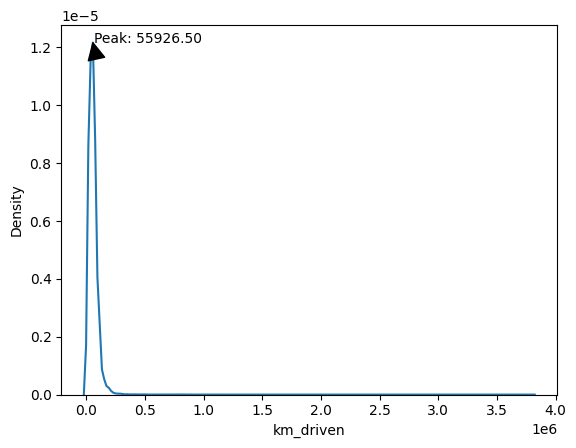

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

ax = sns.kdeplot(x="km_driven",data=cars)

# Find the peak of the KDE plot
lines = ax.get_lines()
if lines:
    x_data, y_data = lines[0].get_data()
    peak_y = y_data.max()
    peak_x = x_data[np.argmax(y_data)]

    # Annotate the peak
    ax.annotate(f'Peak: {peak_x:.2f}', xy=(peak_x, peak_y), xytext=(peak_x + peak_x*0.1, peak_y),
                arrowprops=dict(facecolor='black', shrink=0.05))

plt.show()

data seems to be left skewed with peak of the number of km around 5000km

In [ ]:
cars.head()

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,1.20,Maruti Alto Std,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5


In [ ]:
year_counts = cars["year"].value_counts().reset_index()
year_counts.columns = ["year", "count"]
year_counts["percentage"] = (year_counts["count"] / year_counts["count"].sum()) * 100
display(year_counts)

,year,count,percentage
0,2017,2653,13.278278
1,2016,2587,12.947948
2,2015,2430,12.162162
3,2018,2163,10.825826
4,2014,1947,9.744745
5,2013,1776,8.888889
6,2012,1554,7.777778
7,2019,1238,6.196196
8,2011,1097,5.490490
9,2010,846,4.234234


In [ ]:
cars.shape

(19980, 11)

In [ ]:
cars_filt=cars.groupby("year").filter(lambda x : x["year"].count()>170)

In [ ]:
cars_filt.head()

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,1.20,Maruti Alto Std,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5


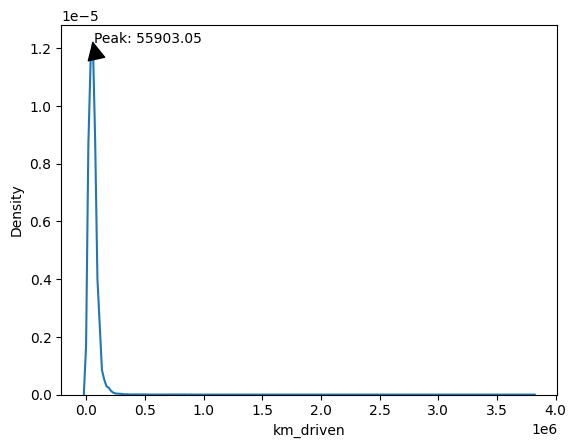

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

ax = sns.kdeplot(x="km_driven",data=cars_filt)

# Find the peak of the KDE plot
lines = ax.get_lines()
if lines:
    x_data, y_data = lines[0].get_data()
    peak_y = y_data.max()
    peak_x = x_data[np.argmax(y_data)]

    # Annotate the peak
    ax.annotate(f'Peak: {peak_x:.2f}', xy=(peak_x, peak_y), xytext=(peak_x + peak_x*0.1, peak_y),
                arrowprops=dict(facecolor='black', shrink=0.05))

plt.show()

<Axes: xlabel='mileage', ylabel='Density'>

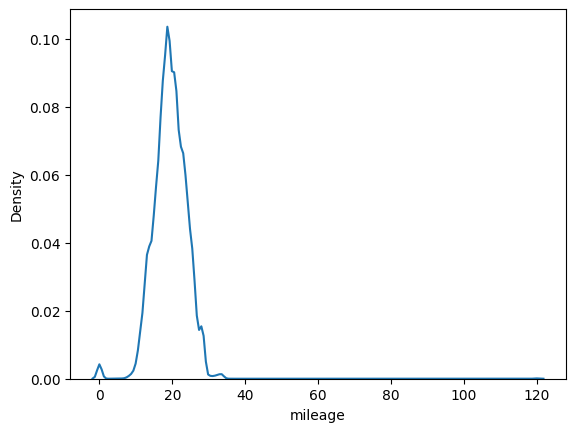

In [ ]:
sns.kdeplot(x="mileage" , data=cars_filt)

<Axes: xlabel='mileage'>

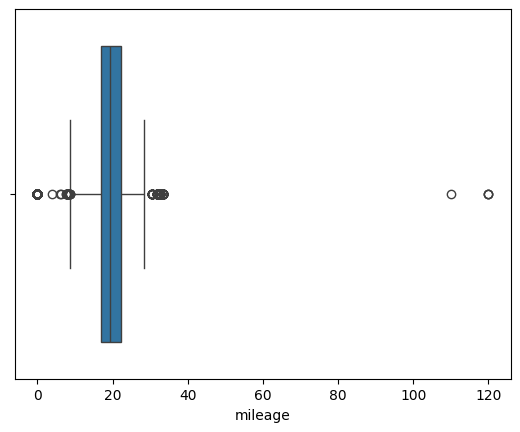

In [ ]:
sns.boxplot(x="mileage" , data=cars_filt)

In [ ]:
Q1 = cars_filt['mileage'].quantile(0.25)
Q3 = cars_filt['mileage'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

cars_filtered_mileage = cars_filt[(cars_filt['mileage'] >= lower_bound) & (cars_filt['mileage'] <= upper_bound)]
display(cars_filtered_mileage.head())

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,1.20,Maruti Alto Std,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5


<Axes: xlabel='mileage', ylabel='Density'>

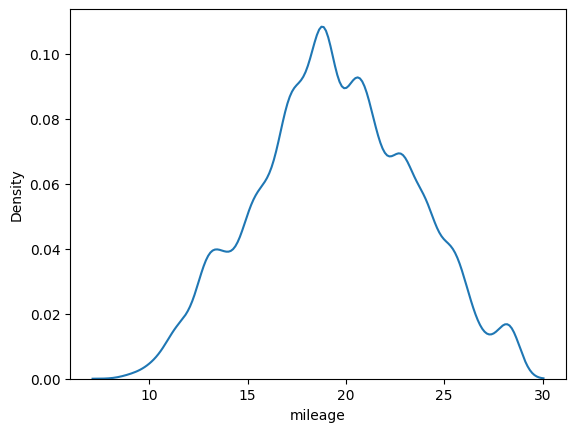

In [ ]:
sns.kdeplot(data=cars_filtered_mileage ,x="mileage")

In [ ]:
cars_filtered_mileage.shape , cars.shape

((19520, 11), (19980, 11))

In [ ]:
# sns.boxplot(data=cars_filtered_mileage , x="km_driven")

# sns.histplot(data=cars_filtered_mileage , x="km_driven")
Q1 = cars_filt['km_driven'].quantile(0.25)
Q3 = cars_filt['km_driven'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

cars_filtered_mileage_km_driven = cars_filt[(cars_filt['km_driven'] >= lower_bound) & (cars_filt['km_driven'] <= upper_bound)]
display(cars_filtered_mileage_km_driven.head())
cars_filtered_mileage_km_driven.shape , cars.shape

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
0,1.20,Maruti Alto Std,2012,Individual,120000,Petrol,Manual,19.70,796.0,46.30,5
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5


((19142, 11), (19980, 11))

<Axes: xlabel='km_driven', ylabel='Count'>

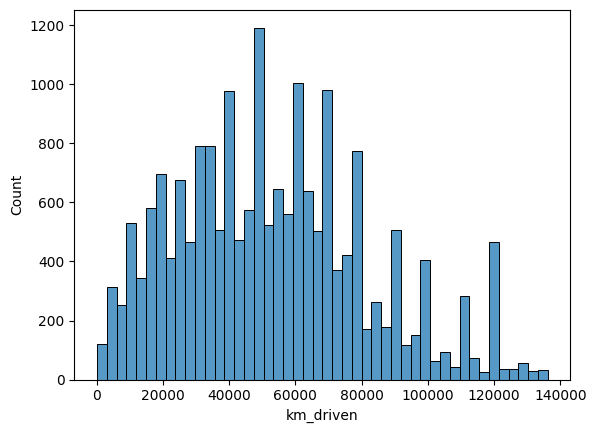

In [ ]:
sns.histplot(data=cars_filtered_mileage_km_driven , x="km_driven")

In [ ]:
np.unique(cars_filtered_mileage_km_driven["full_name"] , return_counts=True)

(array(['Ambassador Avigo 1800 ISZ MPFI AC', 'Ambassador Classic 2000 Dsz',
        'Audi A3 35 TDI Attraction', ..., 'Volvo XC60 D5 Inscription',
        'Volvo XC60 D5 Summum', 'Volvo XC90 D5 Inscription BSIV'],
       dtype=object),
 array([1, 1, 2, ..., 1, 1, 4]))

In [ ]:
cars_value_count=cars_filtered_mileage_km_driven["full_name"].value_counts()

# high_count_cars=cars_value_counts.index[cars_value_counts>10]
high_count_cars=cars_value_count.index[cars_value_count>5]

In [ ]:
# sns.histplot(data=cars_filtered_mileage_km_driven["full_name"].value_counts().head(20) , x="full_name")

cars_mod=cars_filtered_mileage_km_driven[cars_filtered_mileage_km_driven["full_name"].isin(high_count_cars)]

In [ ]:
cars_mod.shape , cars.shape

((14230, 11), (19980, 11))

In [ ]:
cars_mod.head()

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5
5,3.50,Maruti Wagon R VXI BS IV,2013,Individual,35000,Petrol,Manual,18.90,998.0,67.10,5


In [ ]:
cars_mod["seats"].value_counts()

,count
seats,
5,12395
7,1496
8,167
4,94
6,63
9,15


In [ ]:
cars_mod.head()

,selling_price,full_name,year,seller_type,km_driven,fuel_type,transmission_type,mileage,engine,max_power,seats
1,5.50,Hyundai Grand i10 Asta,2016,Individual,20000,Petrol,Manual,18.90,1197.0,82.00,5
2,2.15,Hyundai i20 Asta,2010,Individual,60000,Petrol,Manual,17.00,1197.0,80.00,5
3,2.26,Maruti Alto K10 2010-2014 VXI,2012,Individual,37000,Petrol,Manual,20.92,998.0,67.10,5
4,5.70,Ford Ecosport 2015-2021 1.5 TDCi Titanium BSIV,2015,Dealer,30000,Diesel,Manual,22.77,1498.0,98.59,5
5,3.50,Maruti Wagon R VXI BS IV,2013,Individual,35000,Petrol,Manual,18.90,998.0,67.10,5


In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import train_test_split
from category_encoders import TargetEncoder

# One-hot encode 'seller_type' and 'transmission_type'
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
encoded_features = one_hot_encoder.fit_transform(cars_mod[['seller_type', 'transmission_type', "fuel_type"]])
encoded_df = pd.DataFrame(encoded_features, columns=one_hot_encoder.get_feature_names_out(['seller_type', 'transmission_type',"fuel_type"]), index=cars_mod.index)

# Target encode 'full_name'
# To avoid data leakage, we split the data before target encoding.
X = cars_mod.drop('selling_price', axis=1)
y = cars_mod['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

target_encoder = TargetEncoder(cols=['full_name'])
X_train_encoded = target_encoder.fit_transform(X_train, y_train)
X_test_encoded = target_encoder.transform(X_test)

# Combine numerical columns, one-hot encoded features, and target encoded feature
cars_num_train = X_train_encoded.select_dtypes(include=np.number).join(encoded_df)
cars_num_test = X_test_encoded.select_dtypes(include=np.number).join(encoded_df)

# Add the target variable back
cars_num_train['selling_price'] = y_train
cars_num_test['selling_price'] = y_test

# Combine train and test sets for the final numerical dataframe
cars_num = pd.concat([cars_num_train, cars_num_test])

display(cars_num.head())

,full_name,year,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,selling_price
18016,5.560258,2013,90000,23.40,1248.0,74.0,5,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,5.50
9417,3.775548,2018,21400,23.01,999.0,67.0,5,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.65
2985,5.817859,2018,15300,23.01,999.0,67.0,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,4.11
7773,5.807309,2016,15000,17.21,1493.0,100.0,7,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,6.00
2581,6.105485,2013,65600,17.21,1493.0,100.0,7,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,2.75


In [ ]:
!pip install category_encoders

In [ ]:
cars_num.shape , cars.shape

((14230, 18), (19980, 11))

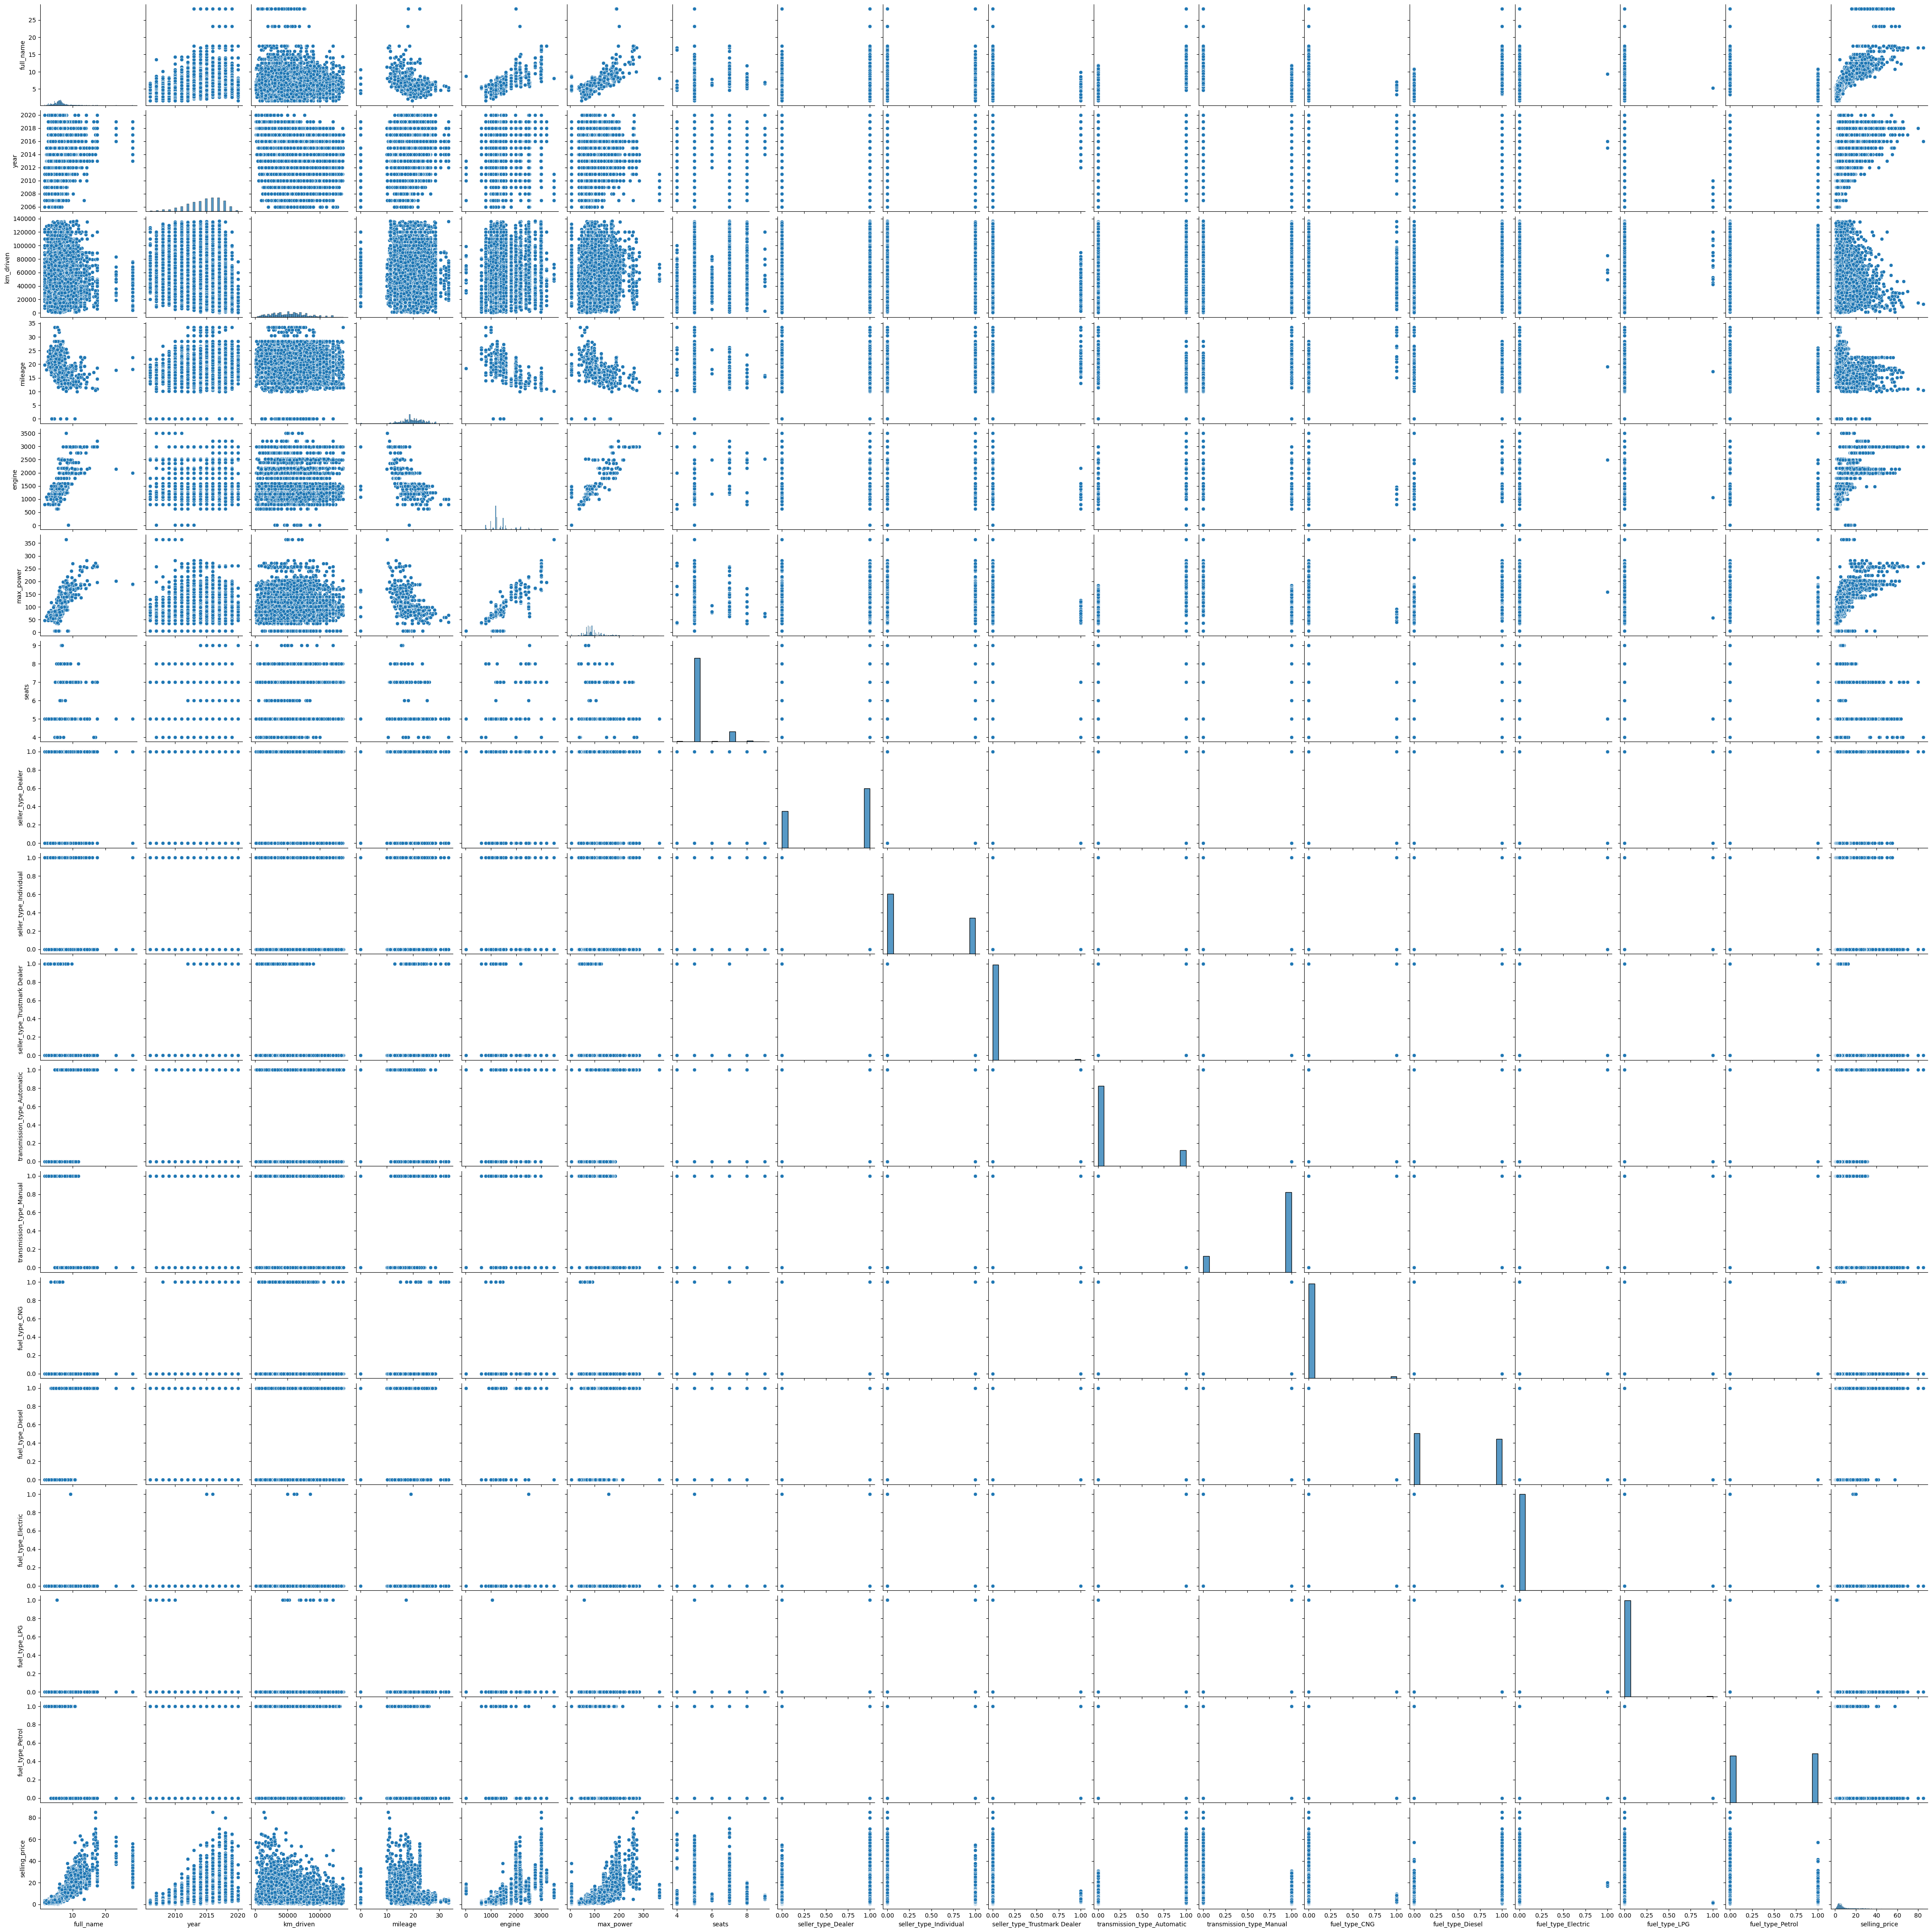

In [ ]:
sns.pairplot(cars_num)

In [ ]:
cars_num.head()

,full_name,year,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,selling_price
18016,5.560258,2013,90000,23.40,1248.0,74.0,5,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,5.50
9417,3.775548,2018,21400,23.01,999.0,67.0,5,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.65
2985,5.817859,2018,15300,23.01,999.0,67.0,5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,4.11
7773,5.807309,2016,15000,17.21,1493.0,100.0,7,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,6.00
2581,6.105485,2013,65600,17.21,1493.0,100.0,7,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,2.75


<Axes: >

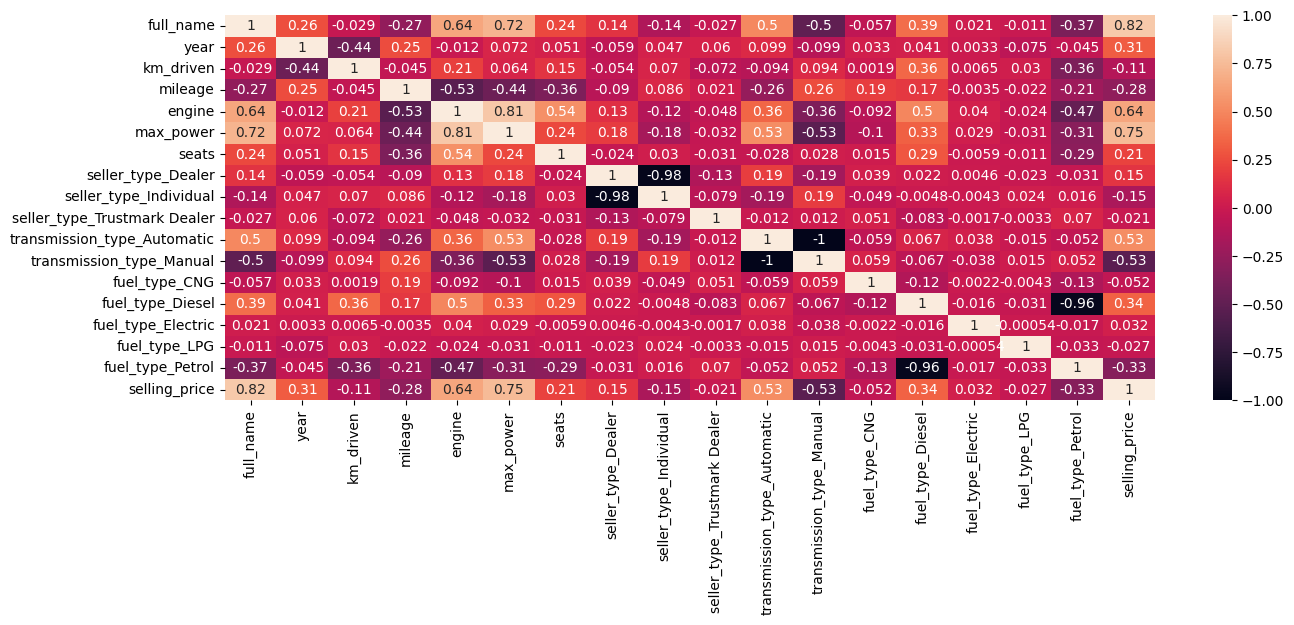

In [ ]:
fig=plt.figure(figsize=(15,5))
sns.heatmap(cars_num.corr() , annot =True)

In [ ]:
cars.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19980 entries, 0 to 19979
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   selling_price      19980 non-null  float64
 1   full_name          19980 non-null  object 
 2   year               19980 non-null  int64  
 3   seller_type        19980 non-null  object 
 4   km_driven          19980 non-null  int64  
 5   fuel_type          19980 non-null  object 
 6   transmission_type  19980 non-null  object 
 7   mileage            19980 non-null  float64
 8   engine             19980 non-null  float64
 9   max_power          19980 non-null  float64
 10  seats              19980 non-null  int64  
dtypes: float64(4), int64(3), object(4)
memory usage: 1.7+ MB


In [ ]:
cars_num.info()

<class 'pandas.core.frame.DataFrame'>
Index: 14230 entries, 18016 to 5241
Data columns (total 18 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   full_name                     14230 non-null  float64
 1   year                          14230 non-null  int64  
 2   km_driven                     14230 non-null  int64  
 3   mileage                       14230 non-null  float64
 4   engine                        14230 non-null  float64
 5   max_power                     14230 non-null  float64
 6   seats                         14230 non-null  int64  
 7   seller_type_Dealer            14230 non-null  float64
 8   seller_type_Individual        14230 non-null  float64
 9   seller_type_Trustmark Dealer  14230 non-null  float64
 10  transmission_type_Automatic   14230 non-null  float64
 11  transmission_type_Manual      14230 non-null  float64
 12  fuel_type_CNG                 14230 non-null  float64
 13  fue

In [ ]:
cars["seller_type"].value_counts()

,count
seller_type,
Dealer,11973
Individual,7817
Trustmark Dealer,190


In [ ]:
cars["fuel_type"].value_counts()

,count
fuel_type,
Diesel,9817
Petrol,9767
CNG,316
LPG,66
Electric,14


In [ ]:
X=cars_num.drop("selling_price" , axis=1)
y=cars_num["selling_price"]

In [ ]:
cars_num.describe()

,full_name,year,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol,selling_price
count,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000,14230.000000
mean,6.198240,2014.695011,53663.687913,20.007482,1401.922188,93.178752,5.247505,0.616374,0.373226,0.010401,0.166620,0.833380,0.016936,0.470274,0.000281,0.001054,0.511455,6.596353
std,2.514670,2.839368,28069.796849,4.090214,452.954878,37.443655,0.702009,0.486286,0.483678,0.101455,0.372649,0.372649,0.129036,0.499133,0.016764,0.032451,0.499886,6.212320
min,1.606644,2006.000000,100.000000,0.000000,17.000000,5.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.250000
25%,4.949932,2013.000000,32000.000000,17.500000,1197.000000,73.000000,5.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.400000
50%,6.020255,2015.000000,51000.000000,19.810000,1248.000000,83.140000,5.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,5.000000
75%,6.805833,2017.000000,70000.000000,22.770000,1498.000000,103.500000,5.000000,1.000000,1.000000,0.000000,0.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,7.400000
max,28.206429,2020.000000,136226.000000,33.540000,3498.000000,364.900000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,85.000000


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
scaler = StandardScaler()
X = cars_num.drop('selling_price', axis=1)
y = cars_num['selling_price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
X_train = scaler.fit_transform(X_train)
X_test=scaler.transform(X_test)


In [ ]:
X_train=pd.DataFrame(X_train , columns=X.columns)
X_test=pd.DataFrame(X_test , columns=X.columns)


In [ ]:
X_train.describe()

,full_name,year,km_driven,mileage,engine,max_power,seats,seller_type_Dealer,seller_type_Individual,seller_type_Trustmark Dealer,transmission_type_Automatic,transmission_type_Manual,fuel_type_CNG,fuel_type_Diesel,fuel_type_Electric,fuel_type_LPG,fuel_type_Petrol
count,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04,1.138400e+04
mean,-9.549634e-17,-1.864675e-15,1.309174e-16,-4.374575e-16,3.120796e-17,-2.496636e-17,-3.994618e-17,-1.248318e-17,5.242937e-17,3.744955e-18,3.807371e-17,-1.135970e-16,2.808716e-17,5.430184e-17,2.496636e-18,-2.496636e-17,2.184557e-17
std,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00,1.000044e+00
min,-1.827364e+00,-3.042791e+00,-1.900862e+00,-4.899570e+00,-3.056711e+00,-2.335667e+00,-1.781756e+00,-1.273512e+00,-7.689458e-01,-9.968011e-02,-4.495686e-01,-2.224355e+00,-1.274641e-01,-9.376396e-01,-1.325579e-02,-2.965128e-02,-1.030689e+00
25%,-4.998709e-01,-5.912811e-01,-7.688796e-01,-6.097757e-01,-4.521320e-01,-5.370011e-01,-3.497093e-01,-1.273512e+00,-7.689458e-01,-9.968011e-02,-4.495686e-01,4.495686e-01,-1.274641e-01,-9.376396e-01,-1.325579e-02,-2.965128e-02,-1.030689e+00
50%,-7.354528e-02,1.091501e-01,-9.465811e-02,-4.352283e-02,-3.395612e-01,-2.687883e-01,-3.497093e-01,7.852300e-01,-7.689458e-01,-9.968011e-02,-4.495686e-01,4.495686e-01,-1.274641e-01,-9.376396e-01,-1.325579e-02,-2.965128e-02,9.702252e-01
75%,2.349046e-01,8.095814e-01,5.795634e-01,6.747114e-01,2.122564e-01,2.697534e-01,-3.497093e-01,7.852300e-01,1.300482e+00,-9.968011e-02,-4.495686e-01,4.495686e-01,-1.274641e-01,1.066508e+00,-1.325579e-02,-2.965128e-02,9.702252e-01
max,8.734409e+00,1.860228e+00,2.929616e+00,3.322127e+00,4.626797e+00,7.184036e+00,5.378478e+00,7.852300e-01,1.300482e+00,1.003209e+01,2.224355e+00,4.495686e-01,7.845346e+00,1.066508e+00,7.543872e+01,3.372536e+01,9.702252e-01


In [ ]:
# Import libraries
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


from sklearn.metrics import r2_score



# Define model
ridge = Ridge()

ridge.fit(X_train, y_train)

y_hat_train=ridge.predict(X_train)
y_hat_test=ridge.predict(X_test)

mse = mean_squared_error(y_train, y_hat_train)
print("Train MSE:", mse)
print("Test MSE" , mean_squared_error(y_test , y_hat_test))
train_r2=r2_score(y_train , y_hat_train)
test_r2=r2_score(y_test , y_hat_test)

print("Train R2:", train_r2)
print("Test R2:", test_r2)

print(ridge.coef_ , ridge.intercept_)

Train MSE: 9.385561766818494
Test MSE 9.200276237222207
Train R2: 0.759165029506968
Test R2: 0.7517326891287509
[ 2.86191033  0.82227701 -0.53861585 -0.15024363  0.59418084  1.66153113
 -0.15449949  0.03094822 -0.0266125  -0.02201381  0.28331461 -0.28331461
  0.09905902  0.17991468  0.02364214  0.01566745 -0.20604065] 6.618039633696418


In [ ]:

param_grid = {
    "alpha": [0.0001, 0.001, 0.01, 0.1, 1, 10, 100],
    "fit_intercept": [True, False],
    "solver": ["auto", "svd", "cholesky", "lsqr", "sag", "saga"],
    "max_iter": [1000, 500]
}

grid = GridSearchCV(ridge, param_grid, cv=5, scoring="r2", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best R² Score:", grid.best_score_)


Best Parameters: {'alpha': 100, 'fit_intercept': True, 'max_iter': 1000, 'solver': 'svd'}
Best R² Score: 0.756715124081362


In [ ]:
print(grid.best_coef_ , grid.best_intercept_)

AttributeError: 'GridSearchCV' object has no attribute 'best_coef_'

In [ ]:
# Create polynomial features (degree=2 for quadratic)
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

# Fit linear regression on transformed features
model = LinearRegression()
model.fit(X_train_poly, y_train)

# Predictions
y_pred_poly = model.predict(X_test_poly)

# Print coefficients and intercept
print("Intercept:", model.intercept_)
print("Coefficients:", model.coef_)

# Evaluate
print("R² Score:", r2_score(y_test, y_pred_poly))
print("MSE:", mean_squared_error(y_test, y_pred_poly))



Intercept: 5.296911022214835
Coefficients: [ 1.35808651e+00  1.60977696e+00 -3.41831308e-01  1.00075029e-01
  8.34251775e-01  1.34160060e+00 -5.46932429e-01  5.79496228e-02
 -5.82381228e-02 -6.00888979e-05  1.06920996e-02 -1.06920996e-02
 -3.03276550e-03  1.48147519e-01  1.92480049e-05 -7.66090254e-05
 -1.47143326e-01 -6.57004145e-01  8.08862195e-01 -4.19642238e-01
 -8.77662265e-02 -1.90486096e+00  2.45492121e+00  6.41111800e-01
  1.74115070e-02 -1.19600875e-03 -7.98323808e-02  3.10054747e-01
 -3.10054747e-01 -1.59342003e-01  5.68082511e-01 -1.79781172e-02
 -4.02418786e-02 -5.24314087e-01 -1.37472772e-01 -1.72211638e-02
  8.63372592e-02  2.85487964e-01  6.55158750e-01 -2.38326521e-01
  2.47430511e-02 -3.26218945e-02  3.79455130e-02 -1.84915597e-03
  1.84915597e-03  2.56292445e-02 -1.65426269e-02 -2.13367689e-02
 -1.18727882e-02  1.13534557e-02  1.27577752e-01  1.09759544e-01
  1.57622182e-01 -1.25749526e-01  1.06114199e-01  5.33154427e-02
 -5.86036007e-02  2.45356436e-02 -9.45960728e-0

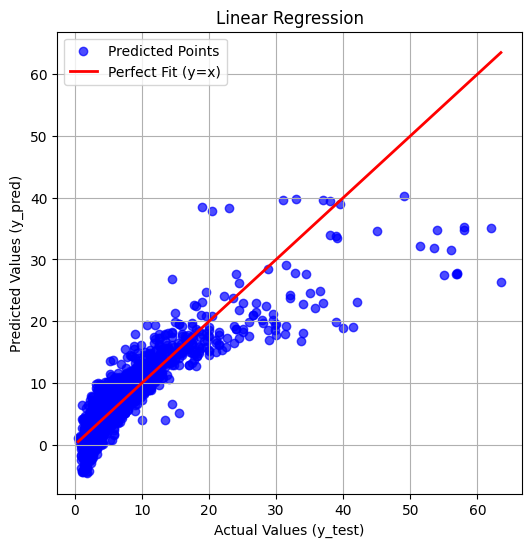

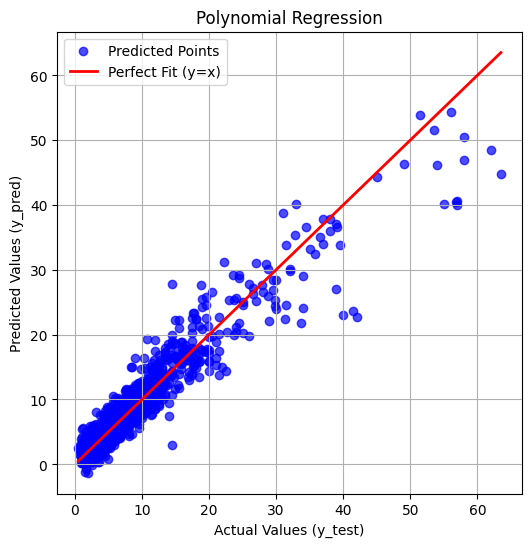

In [ ]:
def plot_actual_vs_pred(y_test, y_pred, title="Actual vs Predicted"):
    plt.figure(figsize=(6,6))
    plt.scatter(y_test, y_pred, color="blue", alpha=0.7, label="Predicted Points")
    plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
             color="red", linewidth=2, label="Perfect Fit (y=x)")

    plt.xlabel("Actual Values (y_test)")
    plt.ylabel("Predicted Values (y_pred)")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()


plot_actual_vs_pred(y_test, y_hat_test, title="Linear Regression")

plot_actual_vs_pred(y_test , y_pred_poly , title="Polynomial Regression")

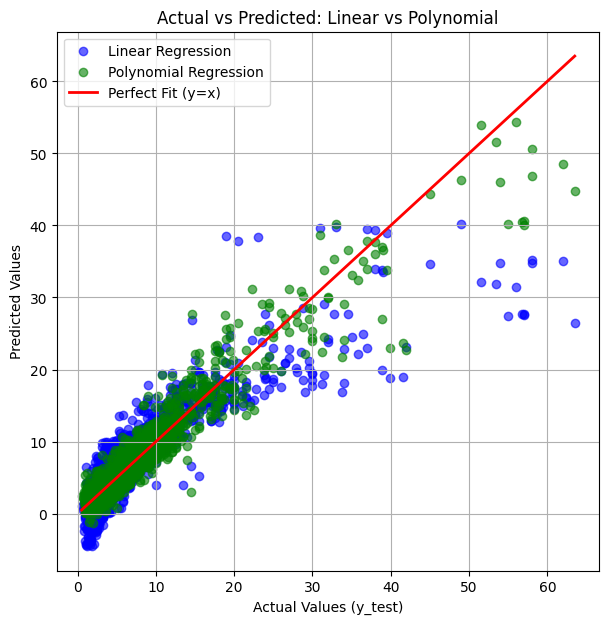

In [ ]:
def compare_models_plot(y_test, y_pred_lin, y_pred_poly):
    plt.figure(figsize=(7,7))

    # Scatter plots
    plt.scatter(y_test, y_pred_lin, color="blue", alpha=0.6, label="Linear Regression")
    plt.scatter(y_test, y_pred_poly, color="green", alpha=0.6, label="Polynomial Regression")

    # Perfect prediction line (y = x)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             color="red", linewidth=2, label="Perfect Fit (y=x)")

    plt.xlabel("Actual Values (y_test)")
    plt.ylabel("Predicted Values")
    plt.title("Actual vs Predicted: Linear vs Polynomial")
    plt.legend()
    plt.grid(True)
    plt.show()

compare_models_plot(y_test, y_hat_test, y_pred_poly)

In [ ]:
X_train.shape


Neural network sequential

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam

def build_regression_model(n_features, n_hidden1=64, n_hidden2=32,n_hidden3=16, learning_rate=0.001):
    """
    Build a Sequential Neural Network for regression.

    Parameters:
    -----------
    n_features : int
        Number of input features
    n_hidden1 : int
        Number of neurons in the first hidden layer
    n_hidden2 : int
        Number of neurons in the second hidden layer
    learning_rate : float
        Learning rate for the optimizer
    """

    model = Sequential([
        Dense(n_hidden1, activation='relu', input_shape=(n_features,)),  # Hidden Layer 1
        Dense(n_hidden2, activation='relu'),                             # Hidden Layer 2
        Dense(n_hidden3,activation ="relu"),
        Dense(1, activation='linear')                                    # Output Layer (regression)
    ])

    # Compile with MSE loss for regression
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse',
                  metrics=['mae'])

    return model


# Example usage:
# Assume we have 10 input features
n_features = 17
model = build_regression_model(n_features, n_hidden1=64, n_hidden2=32 , n_hidden3=16)

model.fit(X_train, y_train, epochs=150, batch_size=1138, validation_split=0.2)
y_pred_nn = model.predict(X_test)
y_train_pred_nn = model.predict(X_train)
print("R² Score test:", r2_score(y_test, y_pred_nn))
print("R² Score train:", r2_score(y_train, y_train_pred_nn))


Epoch 1/150


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - loss: 70.6918 - mae: 5.9374 - val_loss: 58.6257 - val_mae: 5.3937
Epoch 2/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 59.7325 - mae: 5.2145 - val_loss: 47.0602 - val_mae: 4.6094
Epoch 3/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 45.3077 - mae: 4.3726 - val_loss: 34.7982 - val_mae: 3.7077
Epoch 4/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 33.7377 - mae: 3.4783 - val_loss: 23.5033 - val_mae: 2.8254
Epoch 5/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 22.4065 - mae: 2.6702 - val_loss: 15.8128 - val_mae: 2.2499
Epoch 6/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 15.0038 - mae: 2.2045 - val_loss: 12.8665 - val_mae: 2.0670
Epoch 7/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 11.7250 - mae: 2.0487 - val_loss: 11.2547 - val_mae: 1.9153
Epoch 8/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 10.5724 - mae: 1.9079 - val_loss: 9.7980 - val_mae: 1.7405
Epoch 9/150
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 8.9666 - ma

In [ ]:
compare_models_plot(y_test, y_pred_nn, y_pred_poly)

In [ ]:
from threading import main_thread
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint


def build_regression_model(n_features, n_hidden1=64, n_hidden2=32,n_hidden3=16, learning_rate=0.001):
    """
    Build a Sequential Neural Network for regression.

    Parameters:
    -----------
    n_features : int
        Number of input features
    n_hidden1 : int
        Number of neurons in the first hidden layer
    n_hidden2 : int
        Number of neurons in the second hidden layer
    learning_rate : float
        Learning rate for the optimizer
    """

    model = Sequential([
        Dense(n_hidden1, activation='relu', input_shape=(n_features,)),  # Hidden Layer 1
        Dense(n_hidden2, activation='relu'),                             # Hidden Layer 2
        Dense(n_hidden3,activation ="relu"),
        Dense(1, activation='linear')                                    # Output Layer (regression)
    ])

    # Compile with MSE loss for regression
    model.compile(optimizer=Adam(learning_rate=learning_rate),
                  loss='mse',
                  metrics=['mae'])

    return model


# Example usage:
# Assume we have 10 input features
n_features = 17
model = build_regression_model(n_features, n_hidden1=64, n_hidden2=32 , n_hidden3=16)
early_stop = EarlyStopping(
    monitor='val_loss',    # what to monitor (val_loss is common)
    patience=10,            # number of epochs with no improvement before stopping
    restore_best_weights=True,
    min_delta=0,
    verbose=1# revert to the best weights
)

checkpoint = ModelCheckpoint(
    filepath='best_model.h5',
    monitor='val_loss',
    save_best_only=True,   # only keep the best model
    verbose=1
)

model.fit(X_train, y_train, epochs=300, batch_size=1138, validation_split=0.2 , callbacks=[early_stop , checkpoint])
y_test_pred_nn = model.predict(X_test)
y_train_pred_nn = model.predict(X_train)
print("R² Score test:", r2_score(y_test, y_test_pred_nn))
print("R² Score test:", r2_score(y_train, y_train_pred_nn))


Epoch 1/300


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1/9 ━━━━━━━━━━━━━━━━━━━━ 13s 2s/step - loss: 76.5316 - mae: 6.7807
Epoch 1: val_loss improved from inf to 75.42420, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - loss: 85.3555 - mae: 6.8720 - val_loss: 75.4242 - val_mae: 6.3852
Epoch 2/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - loss: 75.7467 - mae: 6.2494
Epoch 2: val_loss improved from 75.42420 to 66.71393, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 76.8315 - mae: 6.1941 - val_loss: 66.7139 - val_mae: 5.7632
Epoch 3/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 65.8112 - mae: 5.7439
Epoch 3: val_loss improved from 66.71393 to 57.44706, saving model to best_model.h5


...

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 4.3567 - mae: 1.0825 - val_loss: 4.6038 - val_mae: 1.1173
Epoch 114/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - loss: 5.2808 - mae: 1.1159
Epoch 114: val_loss improved from 4.60381 to 4.57882, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4.6989 - mae: 1.1014 - val_loss: 4.5788 - val_mae: 1.1223
Epoch 115/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 4.9925 - mae: 1.1488
Epoch 115: val_loss improved from 4.57882 to 4.55982, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 4.2662 - mae: 1.0992 - val_loss: 4.5598 - val_mae: 1.1232
Epoch 116/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 4.5115 - mae: 1.1119
Epoch 116: val_loss improved from 4.55982 to 4.53923, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4.7199 - mae: 1.1025 - val_loss: 4.5392 - val_mae: 1.1161
Epoch 117/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 4.1453 - mae: 1.1078
Epoch 117: val_loss did not improve from 4.53923
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.2725 - mae: 1.0795 - val_loss: 4.5967 - val_mae: 1.1094
Epoch 118/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - loss: 6.0222 - mae: 1.1495
Epoch 118: val_loss did not improve from 4.53923
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.7426 - mae: 1.0912 - val_loss: 4.5437 - val_mae: 1.1085
Epoch 119/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - loss: 4.3872 - mae: 1.0332
Epoch 119: val_loss improved from 4.53923 to 4.51353, saving model to best_model.h5


9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 4.4991 - mae: 1.0723 - val_loss: 4.5135 - val_mae: 1.1086
Epoch 120/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - loss: 3.6763 - mae: 1.0545
Epoch 120: val_loss did not improve from 4.51353
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 4.5861 - mae: 1.0811 - val_loss: 4.5298 - val_mae: 1.1053
Epoch 121/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - loss: 3.5538 - mae: 1.0426
Epoch 121: val_loss did not improve from 4.51353
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 4.3827 - mae: 1.0751 - val_loss: 5.2632 - val_mae: 1.1274
Epoch 122/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - loss: 5.7499 - mae: 1.1874
Epoch 122: val_loss did not improve from 4.51353
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 5.0127 - mae: 1.1153 - val_loss: 5.1961 - val_mae: 1.1274
Epoch 123/300
1/9 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 4.9203 - mae: 1.1328
Epoch 123: val_loss did not improve from 4.51353
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 4.8438 - mae: 1.13

In [ ]:
def compare_models_plot(y_test, y_test_pred_nn, y_pred_poly):
    plt.figure(figsize=(7,7))

    # Scatter plots
    plt.scatter(y_test, y_test_pred_nn, color="blue", alpha=0.6, label="Sequential NN")
    plt.scatter(y_test, y_pred_poly, color="green", alpha=0.6, label="Polynomial Regression")

    # Perfect prediction line (y = x)
    plt.plot([y_test.min(), y_test.max()],
             [y_test.min(), y_test.max()],
             color="red", linewidth=2, label="Perfect Fit (y=x)")

    plt.xlabel("Actual Values (y_test)")
    plt.ylabel("Predicted Values")
    plt.title("Actual vs Predicted: Seq NN vs Polynomial")
    plt.legend()
    plt.grid(True)
    plt.show()

compare_models_plot(y_test, y_test_pred_nn, y_pred_poly)

In [ ]:
# Create polynomial features (degree=2 for quadratic)
from sklearn.preprocessing import PolynomialFeatures
for degree in range(2, 6):
  print("for degree" , degree)
  poly = PolynomialFeatures(degree=2, include_bias=False)
  X_train_poly = poly.fit_transform(X_train)
  X_test_poly = poly.transform(X_test)

  # Fit linear regression on transformed features
  model = LinearRegression()
  model.fit(X_train_poly, y_train)

  # Predictions
  y_pred_poly = model.predict(X_test_poly)

  # Print coefficients and intercept
  # print("Intercept:", model.intercept_)
  # print("Coefficients:", model.coef_)
  r2=r2_score(y_test, y_pred_poly)
  n = X_test_poly.shape[0]   # number of samples
  p = X_test_poly.shape[1]   #no of features
  # Evaluate
  print("R² Score:", r2)
  print("MSE:", mean_squared_error(y_test, y_pred_poly))
  adj_r2_test= 1 - (1 - r2) * (n - 1) / (n - p - 1)
  print("adj r2" ,adj_r2_test)


for degree 2
R² Score: 0.9069773323407131
MSE: 3.4472288590284443
adj r2 0.9010656114053566
for degree 3
R² Score: 0.9069773323407131
MSE: 3.4472288590284443
adj r2 0.9010656114053566
for degree 4
R² Score: 0.9069773323407131
MSE: 3.4472288590284443
adj r2 0.9010656114053566
for degree 5
R² Score: 0.9069773323407131
MSE: 3.4472288590284443
adj r2 0.9010656114053566


In [ ]:
##if using pipeline no need to transform data X train the Pipeline automatically does it but without pipeline we need to do the transformation

import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import r2_score
model = Pipeline([
    ("poly", PolynomialFeatures(degree =2)),  # polynomial features
    ("ridge", Ridge())  # ridge regression
])
param_grid = {
    "poly__degree": [2, 3],       # try different polynomial degrees
    "ridge__alpha": [0.01,0.1]  # strength of regularization
}

grid = GridSearchCV(model, param_grid, cv=5, scoring="r2")
grid.fit(X_train, y_train)

# ---------------- Evaluation ----------------
y_pred = grid.predict(X_test)


print("✅ Best Parameters:", grid.best_params_)
print("📊 Best Cross-validated R2:", grid.best_score_)
print("🎯 Test R2 Score:", r2_score(y_test, y_pred))

✅ Best Parameters: {'poly__degree': 3, 'ridge__alpha': 0.1}
📊 Best Cross-validated R2: 0.9318817153645176
🎯 Test R2 Score: 0.9433674386993187


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input

# ---------------- Define Input ----------------
# Suppose input data has 10 features
inputs = Input(shape=(17,), name="input_layer")

# ---------------- Hidden Layers ----------------
hidden1 = layers.Dense(64, activation="relu", name="hidden_layer1")(inputs)
hidden2 = layers.Dense(32, activation="relu", name="hidden_layer2")(hidden1)
hidden3= layers.Dense(16, activation="relu", name="hidden_layer3")(hidden2)
hidden4= layers.Dense(8, activation="relu", name="hidden_layer4")(hidden3)
# ---------------- Output Layer ----------------
# Regression → Linear activation (default)
outputs = layers.Dense(1, activation="linear", name="output_layer")(hidden4)

# ---------------- Build Model ----------------
model = Model(inputs=inputs, outputs=outputs, name="functional_nn")

# ---------------- Compile ----------------
model.compile(optimizer="adam", loss="mse", metrics=["mae"])
model.summary()

model.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=1000, verbose=1)

Model: "functional_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 17)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer1 (Dense)           │ (None, 64)             │         1,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer3 (Dense)           │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer4 (Dense)           │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,905 (15.25 KB)

 Trainable params: 3,905 (15.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 3s 31ms/step - loss: 89.3612 - mae: 6.9232 - val_loss: 79.1982 - val_mae: 6.6001
Epoch 2/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 80.9182 - mae: 6.5019 - val_loss: 75.8204 - val_mae: 6.3630
Epoch 3/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 79.5324 - mae: 6.2887 - val_loss: 71.2259 - val_mae: 6.0565
Epoch 4/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 70.2030 - mae: 5.8715 - val_loss: 63.5326 - val_mae: 5.5507
Epoch 5/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 64.7387 - mae: 5.3736 - val_loss: 50.9706 - val_mae: 4.7037
Epoch 6/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 48.9416 - mae: 4.3994 - val_loss: 33.3172 - val_mae: 3.4454
Epoch 7/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 30.9217 - mae: 3.1065 - val_loss: 16.9978 - val_mae: 2.2415
Epoch 8/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 17.3498 - mae: 2.2054 - val_loss: 12.8015 - val_mae: 2.1823
Epoch 9/150
10/10 ━━━━━━━━━━━━━━━━━━━━ 0

In [ ]:
y_test_pred_nn_FAPI = model.predict(X_test)
y_train_pred_nn_FAPI = model.predict(X_train)
print("R² Score test:", r2_score(y_test, y_test_pred_nn_FAPI))
print("R² Score test:", r2_score(y_train, y_train_pred_nn_FAPI))

89/89 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step
356/356 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
R² Score test: 0.9291759841171463
R² Score test: 0.9292273873844749


This is end of Linear /Polynomial and NN regression practice

Logistic Regression


In [1]:
import pandas as pd

In [2]:
data=pd.read_csv("logistic_regression.csv")

In [3]:
data.head()

,loan_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,...,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,address
0,10000.0,36 months,11.44,329.48,B,B4,Marketing,10+ years,RENT,117000.0,...,16.0,0.0,36369.0,41.8,25.0,w,INDIVIDUAL,0.0,0.0,"0174 Michelle Gateway\r\nMendozaberg, OK 22690"
1,8000.0,36 months,11.99,265.68,B,B5,Credit analyst,4 years,MORTGAGE,65000.0,...,17.0,0.0,20131.0,53.3,27.0,f,INDIVIDUAL,3.0,0.0,"1076 Carney Fort Apt. 347\r\nLoganmouth, SD 05113"
2,15600.0,36 months,10.49,506.97,B,B3,Statistician,< 1 year,RENT,43057.0,...,13.0,0.0,11987.0,92.2,26.0,f,INDIVIDUAL,0.0,0.0,"87025 Mark Dale Apt. 269\r\nNew Sabrina, WV 05113"
3,7200.0,36 months,6.49,220.65,A,A2,Client Advocate,6 years,RENT,54000.0,...,6.0,0.0,5472.0,21.5,13.0,f,INDIVIDUAL,0.0,0.0,"823 Reid Ford\r\nDelacruzside, MA 00813"
4,24375.0,60 months,17.27,609.33,C,C5,Destiny Management Inc.,9 years,MORTGAGE,55000.0,...,13.0,0.0,24584.0,69.8,43.0,f,INDIVIDUAL,1.0,0.0,"679 Luna Roads\r\nGreggshire, VA 11650"


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 396030 entries, 0 to 396029
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             396030 non-null  float64
 1   term                  396030 non-null  object 
 2   int_rate              396030 non-null  float64
 3   installment           396030 non-null  float64
 4   grade                 396030 non-null  object 
 5   sub_grade             396030 non-null  object 
 6   emp_title             373103 non-null  object 
 7   emp_length            377729 non-null  object 
 8   home_ownership        396030 non-null  object 
 9   annual_inc            396030 non-null  float64
 10  verification_status   396030 non-null  object 
 11  issue_d               396030 non-null  object 
 12  loan_status           396030 non-null  object 
 13  purpose               396030 non-null  object 
 14  title                 394274 non-null  object 
 15  

In [5]:
data.shape

(396030, 27)

In [6]:
data["loan_status"].value_counts()

,count
loan_status,
Fully Paid,318357
Charged Off,77673


In [7]:
data.isna().sum()

,0
loan_amnt,0
term,0
int_rate,0
installment,0
grade,0
sub_grade,0
emp_title,22927
emp_length,18301
home_ownership,0
annual_inc,0


In [8]:
df=data.dropna(axis=0)

In [9]:
df.isna().sum() , df.shape

(loan_amnt               0
 term                    0
 int_rate                0
 installment             0
 grade                   0
 sub_grade               0
 emp_title               0
 emp_length              0
 home_ownership          0
 annual_inc              0
 verification_status     0
 issue_d                 0
 loan_status             0
 purpose                 0
 title                   0
 dti                     0
 earliest_cr_line        0
 open_acc                0
 pub_rec                 0
 revol_bal               0
 revol_util              0
 total_acc               0
 initial_list_status     0
 application_type        0
 mort_acc                0
 pub_rec_bankruptcies    0
 address                 0
 dtype: int64,
 (335867, 27))

In [10]:
df.shape[0]-data.shape[0]

-60163

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335867 entries, 0 to 396028
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             335867 non-null  float64
 1   term                  335867 non-null  object 
 2   int_rate              335867 non-null  float64
 3   installment           335867 non-null  float64
 4   grade                 335867 non-null  object 
 5   sub_grade             335867 non-null  object 
 6   emp_title             335867 non-null  object 
 7   emp_length            335867 non-null  object 
 8   home_ownership        335867 non-null  object 
 9   annual_inc            335867 non-null  float64
 10  verification_status   335867 non-null  object 
 11  issue_d               335867 non-null  object 
 12  loan_status           335867 non-null  object 
 13  purpose               335867 non-null  object 
 14  title                 335867 non-null  object 
 15  dti  

In [12]:
df["term"].value_counts()

,count
term,
36 months,254775
60 months,81092


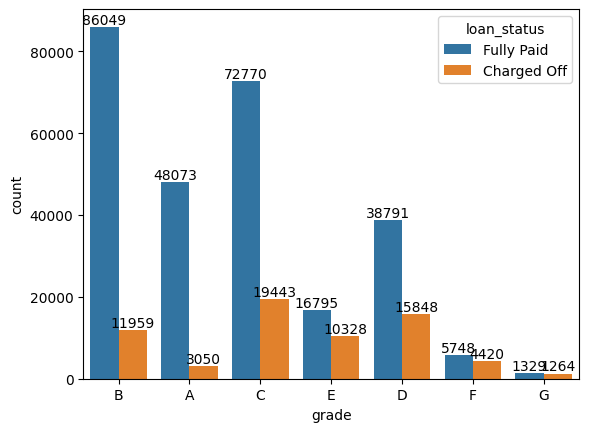

In [13]:
df["grade"].value_counts()
import seaborn as sns
import matplotlib.pyplot as plt

ax = sns.countplot(data=df , x="grade" , hue="loan_status")

# Add value labels
for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [14]:
def object_column(feature , data):
  data[feature].value_counts()
  ax = sns.countplot(data=data , x=feature , hue="loan_status")

# Add value labels
  for container in ax.containers:
      ax.bar_label(container)

  plt.show()



In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335867 entries, 0 to 396028
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             335867 non-null  float64
 1   term                  335867 non-null  object 
 2   int_rate              335867 non-null  float64
 3   installment           335867 non-null  float64
 4   grade                 335867 non-null  object 
 5   sub_grade             335867 non-null  object 
 6   emp_title             335867 non-null  object 
 7   emp_length            335867 non-null  object 
 8   home_ownership        335867 non-null  object 
 9   annual_inc            335867 non-null  float64
 10  verification_status   335867 non-null  object 
 11  issue_d               335867 non-null  object 
 12  loan_status           335867 non-null  object 
 13  purpose               335867 non-null  object 
 14  title                 335867 non-null  object 
 15  dti  

In [16]:
df.columns

Index(['loan_amnt', 'term', 'int_rate', 'installment', 'grade', 'sub_grade',
       'emp_title', 'emp_length', 'home_ownership', 'annual_inc',
       'verification_status', 'issue_d', 'loan_status', 'purpose', 'title',
       'dti', 'earliest_cr_line', 'open_acc', 'pub_rec', 'revol_bal',
       'revol_util', 'total_acc', 'initial_list_status', 'application_type',
       'mort_acc', 'pub_rec_bankruptcies', 'address'],
      dtype='object')

In [17]:
filtered_df = df[df["home_ownership"].isin(["RENT" , "MORTGAGE" , "OWN"])]

In [18]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   loan_amnt             335808 non-null  float64
 1   term                  335808 non-null  object 
 2   int_rate              335808 non-null  float64
 3   installment           335808 non-null  float64
 4   grade                 335808 non-null  object 
 5   sub_grade             335808 non-null  object 
 6   emp_title             335808 non-null  object 
 7   emp_length            335808 non-null  object 
 8   home_ownership        335808 non-null  object 
 9   annual_inc            335808 non-null  float64
 10  verification_status   335808 non-null  object 
 11  issue_d               335808 non-null  object 
 12  loan_status           335808 non-null  object 
 13  purpose               335808 non-null  object 
 14  title                 335808 non-null  object 
 15  dti  

In [19]:
filtered_df["home_ownership"].value_counts()

,count
home_ownership,
MORTGAGE,170831
RENT,133932
OWN,31045


In [20]:
filtered_df["purpose"].value_counts()

,count
purpose,
debt_consolidation,204292
credit_card,72613
home_improvement,19632
other,16192
major_purchase,6367
small_business,3397
medical,3239
car,3074
moving,2178


In [21]:
filtered_df["purpose"] = filtered_df["purpose"].replace({"educational": "other", "renewable_energy": "other", "wedding":"other" , "vacation" : "other", "moving":"other" , "car" : "other" , "medical":"other" ,"small_business":"other", "major_purchase":"other"})

/tmp/ipython-input-1984753755.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["purpose"] = filtered_df["purpose"].replace({"educational": "other", "renewable_energy": "other", "wedding":"other" , "vacation" : "other", "moving":"other" , "car" : "other" , "medical":"other" ,"small_business":"other", "major_purchase":"other"})


In [22]:
filtered_df["purpose"] = filtered_df["purpose"].replace({"house": "other"})

/tmp/ipython-input-1969576268.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["purpose"] = filtered_df["purpose"].replace({"house": "other"})


In [23]:
filtered_df["emp_length"] = filtered_df["emp_length"].str.extract(r"(\d+)").astype(int)

# 🔹 Step 2: Define bins
bins = [0, 3, 6, 9, float("inf")]
labels = ["<=3 years", "<=6 years", "<=9 years", ">=10 years"]

# 🔹 Step 3: Apply binning
filtered_df["emp_length_bin"] = pd.cut(filtered_df["emp_length"], bins=bins, labels=labels, right=True)


/tmp/ipython-input-2989542997.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["emp_length"] = filtered_df["emp_length"].str.extract(r"(\d+)").astype(int)
/tmp/ipython-input-2989542997.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["emp_length_bin"] = pd.cut(filtered_df["emp_length"], bins=bins, labels=labels, right=True)


In [24]:
print(filtered_df["emp_length_bin"].value_counts())

emp_length_bin
>=10 years    115177
<=3 years     108803
<=6 years      61670
<=9 years      50158
Name: count, dtype: int64


In [25]:
filtered_df.drop("emp_length" , axis=1 , inplace=True)

/tmp/ipython-input-1970135817.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("emp_length" , axis=1 , inplace=True)


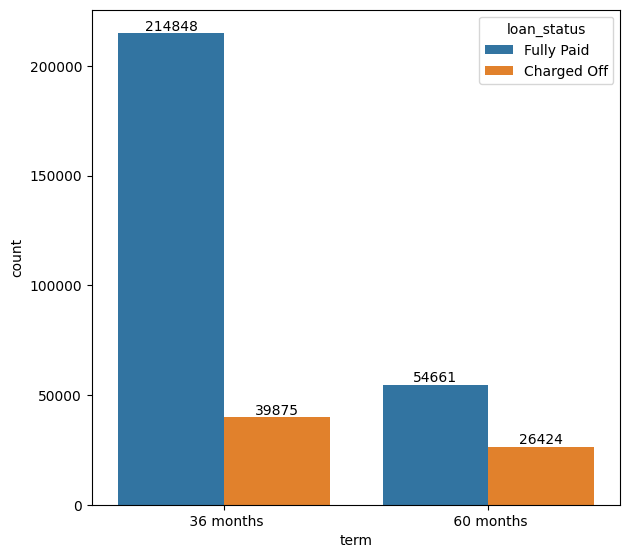

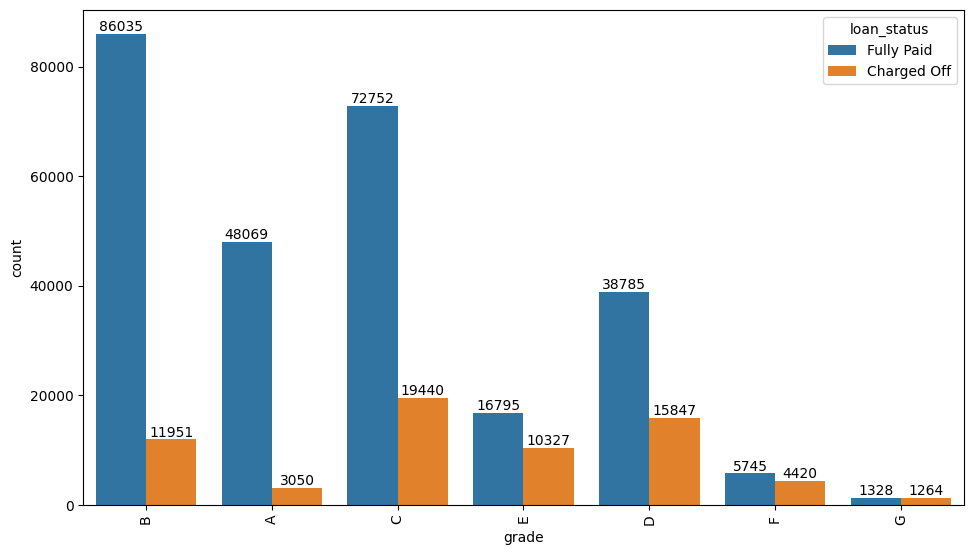

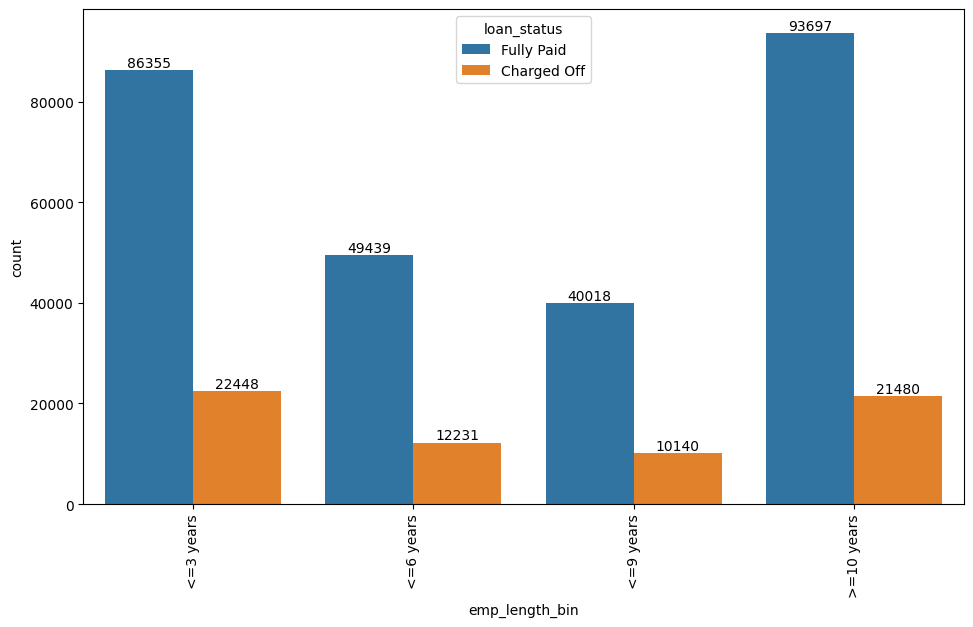

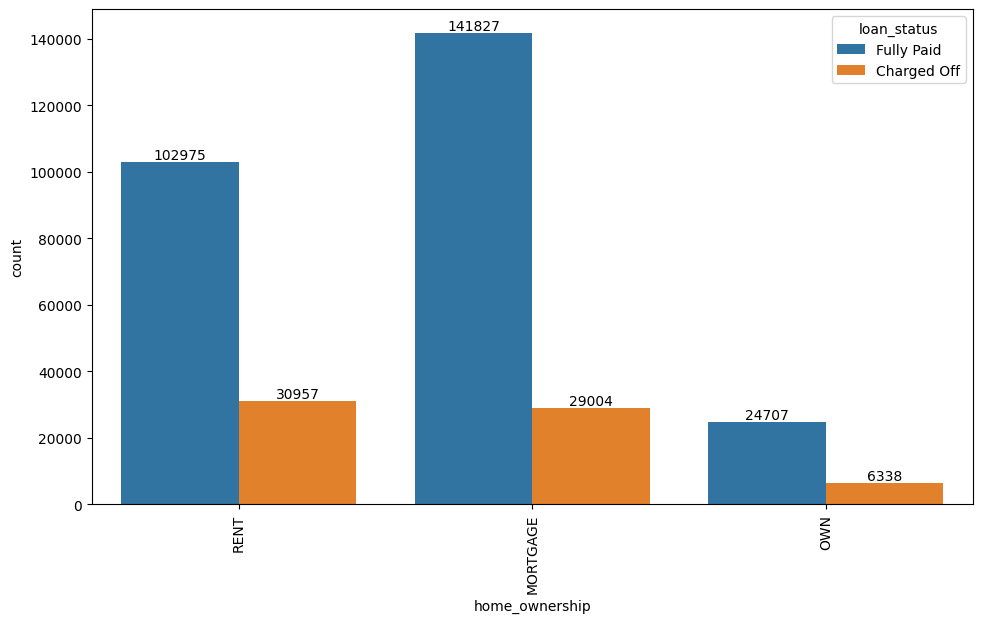

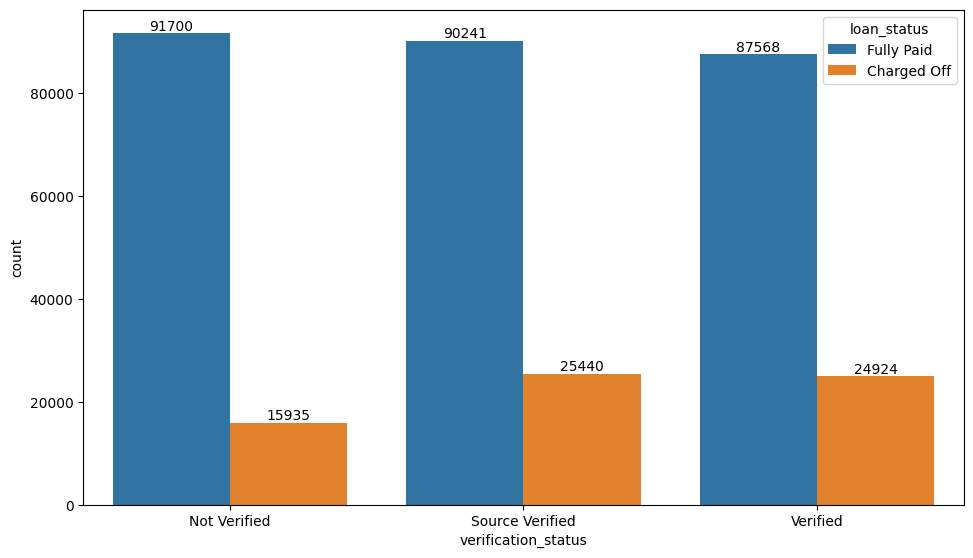

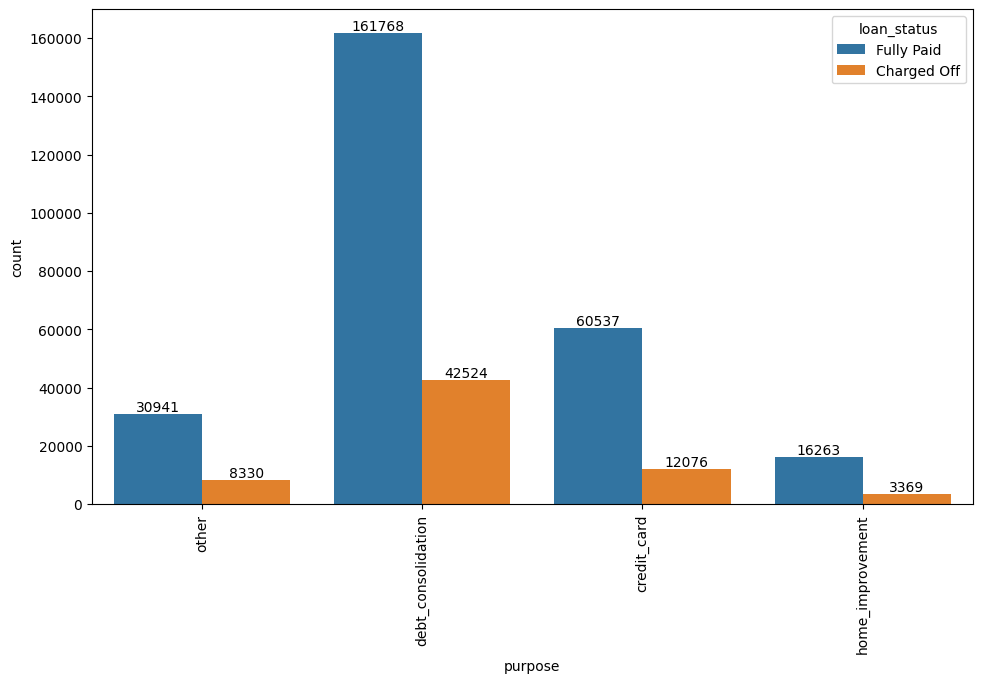

In [26]:
import matplotlib.pyplot as plt
import seaborn as sns
fig=plt.figure(figsize =(15,45))
plt.subplot(6,2,1)
object_column("term" , filtered_df)

fig=plt.figure(figsize =(25,45))
plt.subplot(6,2,2)
plt.xticks(rotation=90)
object_column("grade" , filtered_df)

fig=plt.figure(figsize =(25,45))
plt.subplot(6,2,3)
plt.xticks(rotation=90)
object_column("emp_length_bin", filtered_df)

fig=plt.figure(figsize =(25,45))
plt.subplot(6,2,4)
plt.xticks(rotation=90)
object_column("home_ownership", filtered_df)

fig=plt.figure(figsize =(25,45))
plt.subplot(6,2,5)

object_column("verification_status", filtered_df)

fig=plt.figure(figsize =(25,45))
plt.subplot(6,2,6)
plt.xticks(rotation=90)
object_column("purpose", filtered_df)

plt.show()




In [27]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 27 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   loan_amnt             335808 non-null  float64 
 1   term                  335808 non-null  object  
 2   int_rate              335808 non-null  float64 
 3   installment           335808 non-null  float64 
 4   grade                 335808 non-null  object  
 5   sub_grade             335808 non-null  object  
 6   emp_title             335808 non-null  object  
 7   home_ownership        335808 non-null  object  
 8   annual_inc            335808 non-null  float64 
 9   verification_status   335808 non-null  object  
 10  issue_d               335808 non-null  object  
 11  loan_status           335808 non-null  object  
 12  purpose               335808 non-null  object  
 13  title                 335808 non-null  object  
 14  dti                   335808 non-null  fl

In [28]:
import numpy as np
val , counts=np.unique(filtered_df["issue_d"] , return_counts=True)

len(val)

58

In [29]:
filtered_df["issue_d"].value_counts()

,count
issue_d,
Oct-2014,14133
Jul-2014,12110
Jan-2015,11130
Dec-2013,9801
Nov-2013,9799
Jul-2015,9754
Oct-2013,9326
Apr-2015,9027
Jan-2014,8955


<Axes: xlabel='issue_d', ylabel='loan_status'>

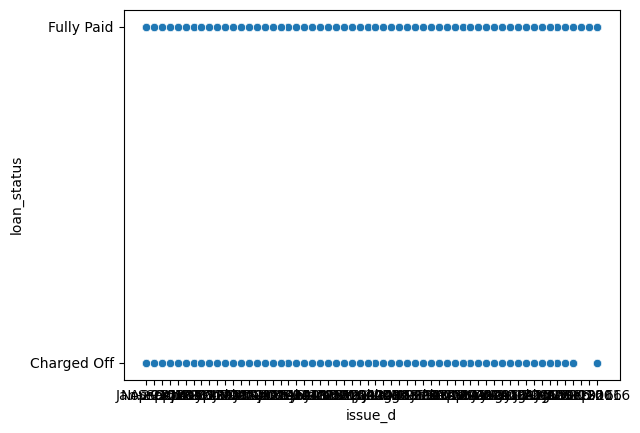

In [30]:
sns.scatterplot(x="issue_d" , y="loan_status", data=filtered_df)

In [31]:
filtered_df.drop("issue_d" , axis=1 , inplace=True)

/tmp/ipython-input-1646893359.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("issue_d" , axis=1 , inplace=True)


In [32]:
import numpy as np
np.unique(filtered_df["title"] , return_counts=True)

filtered_df["title"].value_counts()

,count
title,
Debt consolidation,144261
Credit card refinancing,48428
Home improvement,14153
Other,11951
Debt Consolidation,8985
...,...
Oaktree,1
DEBT CONDOLIDATION END,1
Consolidate Remaining CC Debt,1


In [33]:
top_titles = df["title"].value_counts().nlargest(10).index
filtered_df["title"] = filtered_df["title"].apply(lambda x: x if x in top_titles else "Other")

/tmp/ipython-input-2747406320.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df["title"] = filtered_df["title"].apply(lambda x: x if x in top_titles else "Other")


In [34]:
filtered_df["title"].value_counts()

,count
title,
Debt consolidation,144261
Other,104397
Credit card refinancing,48428
Home improvement,14153
Debt Consolidation,8985
Major purchase,4466
Consolidation,3201
debt consolidation,2799
Business,2615


In [35]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 26 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   loan_amnt             335808 non-null  float64 
 1   term                  335808 non-null  object  
 2   int_rate              335808 non-null  float64 
 3   installment           335808 non-null  float64 
 4   grade                 335808 non-null  object  
 5   sub_grade             335808 non-null  object  
 6   emp_title             335808 non-null  object  
 7   home_ownership        335808 non-null  object  
 8   annual_inc            335808 non-null  float64 
 9   verification_status   335808 non-null  object  
 10  loan_status           335808 non-null  object  
 11  purpose               335808 non-null  object  
 12  title                 335808 non-null  object  
 13  dti                   335808 non-null  float64 
 14  earliest_cr_line      335808 non-null  ob

In [36]:
filtered_df["title"].value_counts()

,count
title,
Debt consolidation,144261
Other,104397
Credit card refinancing,48428
Home improvement,14153
Debt Consolidation,8985
Major purchase,4466
Consolidation,3201
debt consolidation,2799
Business,2615


In [37]:
# filtered_df.drop("title" , axis=1 , inplace=True)

In [38]:
df["earliest_cr_line"].value_counts()

,count
earliest_cr_line,
Aug-2001,2569
Oct-2000,2549
Aug-2000,2533
Oct-2001,2524
Aug-2002,2341
...,...
Feb-1961,1
Jan-1948,1
Aug-1963,1


In [39]:

val , count=np.unique(df["earliest_cr_line"] , return_counts=True)

len(val)

661

In [40]:
filtered_df.drop("earliest_cr_line" , axis=1 , inplace =True)

/tmp/ipython-input-1453358169.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("earliest_cr_line" , axis=1 , inplace =True)


In [41]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 25 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   loan_amnt             335808 non-null  float64 
 1   term                  335808 non-null  object  
 2   int_rate              335808 non-null  float64 
 3   installment           335808 non-null  float64 
 4   grade                 335808 non-null  object  
 5   sub_grade             335808 non-null  object  
 6   emp_title             335808 non-null  object  
 7   home_ownership        335808 non-null  object  
 8   annual_inc            335808 non-null  float64 
 9   verification_status   335808 non-null  object  
 10  loan_status           335808 non-null  object  
 11  purpose               335808 non-null  object  
 12  title                 335808 non-null  object  
 13  dti                   335808 non-null  float64 
 14  open_acc              335808 non-null  fl

In [42]:
val , count=np.unique(filtered_df["initial_list_status"] , return_counts=True)
val , count
filtered_df["initial_list_status"].value_counts()

,count
initial_list_status,
f,187506
w,148302


In [43]:
val , count=np.unique(filtered_df["address"] , return_counts=True)
val , count
#df["address"].value_counts()
len(val)

334084

In [44]:
df.shape

(335867, 27)

In [45]:
filtered_df.drop("address" , axis=1 , inplace=True)

/tmp/ipython-input-4007236451.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("address" , axis=1 , inplace=True)


In [46]:
vc=filtered_df["emp_title"].value_counts()
vc.head(50)

,count
emp_title,
Teacher,4367
Manager,4231
Registered Nurse,1841
RN,1840
Supervisor,1812
Sales,1618
Project Manager,1494
Owner,1381
Driver,1317


In [47]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 24 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   loan_amnt             335808 non-null  float64 
 1   term                  335808 non-null  object  
 2   int_rate              335808 non-null  float64 
 3   installment           335808 non-null  float64 
 4   grade                 335808 non-null  object  
 5   sub_grade             335808 non-null  object  
 6   emp_title             335808 non-null  object  
 7   home_ownership        335808 non-null  object  
 8   annual_inc            335808 non-null  float64 
 9   verification_status   335808 non-null  object  
 10  loan_status           335808 non-null  object  
 11  purpose               335808 non-null  object  
 12  title                 335808 non-null  object  
 13  dti                   335808 non-null  float64 
 14  open_acc              335808 non-null  fl

In [48]:
term_counts=filtered_df["term"].value_counts()
grade_counts=filtered_df["grade"].value_counts()
home_ownership_counts=filtered_df["home_ownership"].value_counts()
verification_status_counts=filtered_df["verification_status"].value_counts()
initial_list_status_counts=filtered_df["initial_list_status"].value_counts()
application_type_counts=filtered_df["application_type"].value_counts()
sub_grade_counts=filtered_df["sub_grade"].value_counts()
purpose_counts=filtered_df["purpose"].value_counts()
emp_length_counts=filtered_df["emp_length_bin"].value_counts()
title_counts=filtered_df["title"].value_counts()

In [49]:
list=[term_counts,grade_counts,home_ownership_counts,verification_status_counts,initial_list_status_counts,application_type_counts,sub_grade_counts,purpose_counts,emp_length_counts,title_counts]

for name in list:
  print(name)
  print()


term
36 months    254723
60 months     81085
Name: count, dtype: int64

grade
B    97986
C    92192
D    54632
A    51119
E    27122
F    10165
G     2592
Name: count, dtype: int64

home_ownership
MORTGAGE    170831
RENT        133932
OWN          31045
Name: count, dtype: int64

verification_status
Source Verified    115681
Verified           112492
Not Verified       107635
Name: count, dtype: int64

initial_list_status
f    187506
w    148302
Name: count, dtype: int64

application_type
INDIVIDUAL    335252
JOINT            311
DIRECT_PAY       245
Name: count, dtype: int64

sub_grade
B3    22322
B4    21815
C1    20266
C2    19362
B2    19237
C3    18577
B5    18307
C4    17945
B1    16305
C5    16042
A5    15051
D1    14095
A4    12202
D2    11865
D3    10319
D4    10070
D5     8283
A3     8260
A1     8037
A2     7569
E1     6761
E2     6438
E3     5341
E4     4642
E5     3940
F1     3021
F2     2368
F3     2006
F4     1545
F5     1225
G1      898
G2      646
G3      476
G4      30

In [50]:
filtered_df.drop("sub_grade", axis=1 , inplace=True)

/tmp/ipython-input-1945225803.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("sub_grade", axis=1 , inplace=True)


In [51]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype   
---  ------                --------------   -----   
 0   loan_amnt             335808 non-null  float64 
 1   term                  335808 non-null  object  
 2   int_rate              335808 non-null  float64 
 3   installment           335808 non-null  float64 
 4   grade                 335808 non-null  object  
 5   emp_title             335808 non-null  object  
 6   home_ownership        335808 non-null  object  
 7   annual_inc            335808 non-null  float64 
 8   verification_status   335808 non-null  object  
 9   loan_status           335808 non-null  object  
 10  purpose               335808 non-null  object  
 11  title                 335808 non-null  object  
 12  dti                   335808 non-null  float64 
 13  open_acc              335808 non-null  float64 
 14  pub_rec               335808 non-null  fl

In [52]:
filtered_df.drop("emp_title", axis=1 , inplace=True)

/tmp/ipython-input-1573969814.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  filtered_df.drop("emp_title", axis=1 , inplace=True)


In [53]:
from sklearn.preprocessing import OneHotEncoder

In [54]:
#categorical_cols = ["term", "grade", "home_ownership", "verification_status", "initial_list_status" , "application_type"]
Object_Columns=["term" , "grade" , "home_ownership" , "verification_status" , "initial_list_status" , "application_type" , "purpose" , "emp_length_bin" , "title"]

# Create OneHotEncoder
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit and transform the categorical data
encoded_features = one_hot_encoder.fit_transform(filtered_df[Object_Columns])

# Convert to DataFrame and join with original data
encoded_df = pd.DataFrame(encoded_features, columns=one_hot_encoder.get_feature_names_out(Object_Columns), index=filtered_df.index)

filtered_df = filtered_df.join(encoded_df)

# Drop original categorical columns
filtered_df.drop(Object_Columns, axis=1, inplace=True)

filtered_df.head()

,loan_amnt,int_rate,installment,annual_inc,loan_status,dti,open_acc,pub_rec,revol_bal,revol_util,...,title_Business,title_Consolidation,title_Credit card refinancing,title_Debt Consolidation,title_Debt consolidation,title_Home improvement,title_Major purchase,title_Medical expenses,title_Other,title_debt consolidation
0,10000.0,11.44,329.48,117000.0,Fully Paid,26.24,16.0,0.0,36369.0,41.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,8000.0,11.99,265.68,65000.0,Fully Paid,22.05,17.0,0.0,20131.0,53.3,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
2,15600.0,10.49,506.97,43057.0,Fully Paid,12.79,13.0,0.0,11987.0,92.2,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,7200.0,6.49,220.65,54000.0,Fully Paid,2.60,6.0,0.0,5472.0,21.5,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,24375.0,17.27,609.33,55000.0,Charged Off,33.95,13.0,0.0,24584.0,69.8,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


In [55]:
filtered_df.shape

(335808, 51)

In [56]:
#pip install category_encoders

In [57]:
# from category_encoders import TargetEncoder

# # Target encode 'emp_length', 'purpose', and 'issue_d'
# target_encoder = TargetEncoder(cols=['emp_length', 'purpose', 'issue_d', "sub_grade"])

# # Assuming 'loan_status' is the target variable and is in the DataFrame
# # Convert 'loan_status' to numerical (e.g., 1 for 'Fully Paid', 0 for 'Charged Off')
# df['loan_status_encoded'] = df['loan_status'].apply(lambda x: 1 if x == 'Fully Paid' else 0)


# # Fit and transform the categorical data using the target encoder
# df[['emp_length_encoded', 'purpose_encoded', 'issue_d_encoded' , 'sub_grade_encoded']] = target_encoder.fit_transform(df[['emp_length', 'purpose', 'issue_d' , 'sub_grade']], df['loan_status_encoded'])

# # Drop original categorical columns and the temporary encoded target column
# df.drop(['emp_length', 'purpose', 'issue_d','sub_grade', 'loan_status_encoded'], axis=1, inplace=True)

# df.head()

In [58]:
filtered_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 51 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   loan_amnt                            335808 non-null  float64
 1   int_rate                             335808 non-null  float64
 2   installment                          335808 non-null  float64
 3   annual_inc                           335808 non-null  float64
 4   loan_status                          335808 non-null  object 
 5   dti                                  335808 non-null  float64
 6   open_acc                             335808 non-null  float64
 7   pub_rec                              335808 non-null  float64
 8   revol_bal                            335808 non-null  float64
 9   revol_util                           335808 non-null  float64
 10  total_acc                            335808 non-null  float64
 11  mort_acc          

In [59]:
filtered_df["pub_rec_bankruptcies"].value_counts()

,count
pub_rec_bankruptcies,
0.0,296411
1.0,37264
2.0,1696
3.0,325
4.0,71
5.0,30
6.0,5
7.0,4
8.0,2


In [60]:
filtered_df["pub_rec_bankruptcies"] = filtered_df["pub_rec_bankruptcies"].replace({3.0: 2.0 , 4.0:2.0, 5.0 :2.0, 6.0:2.0,7.0:2.0,8.0:2.0})

In [61]:
Object_Column=["pub_rec_bankruptcies"]

# Create OneHotEncoder
one_hot_encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

# Fit and transform the categorical data
encoded_features = one_hot_encoder.fit_transform(filtered_df[Object_Column])

# Convert to DataFrame and join with original data
encoded_df = pd.DataFrame(encoded_features, columns=one_hot_encoder.get_feature_names_out(Object_Column), index=filtered_df.index)

filtered_df = filtered_df.join(encoded_df)

# Drop original categorical columns
filtered_df.drop(Object_Column, axis=1, inplace=True)

filtered_df.head()

,loan_amnt,int_rate,installment,annual_inc,loan_status,dti,open_acc,pub_rec,revol_bal,revol_util,...,title_Debt Consolidation,title_Debt consolidation,title_Home improvement,title_Major purchase,title_Medical expenses,title_Other,title_debt consolidation,pub_rec_bankruptcies_0.0,pub_rec_bankruptcies_1.0,pub_rec_bankruptcies_2.0
0,10000.0,11.44,329.48,117000.0,Fully Paid,26.24,16.0,0.0,36369.0,41.8,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,8000.0,11.99,265.68,65000.0,Fully Paid,22.05,17.0,0.0,20131.0,53.3,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,15600.0,10.49,506.97,43057.0,Fully Paid,12.79,13.0,0.0,11987.0,92.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,7200.0,6.49,220.65,54000.0,Fully Paid,2.60,6.0,0.0,5472.0,21.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,24375.0,17.27,609.33,55000.0,Charged Off,33.95,13.0,0.0,24584.0,69.8,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [62]:
df_encoded=filtered_df.copy()

In [63]:
df_encoded['loan_status'] = df_encoded['loan_status'].map({'Fully Paid': 1, 'Charged Off': 0})
display(df_encoded.head())

,loan_amnt,int_rate,installment,annual_inc,loan_status,dti,open_acc,pub_rec,revol_bal,revol_util,...,title_Debt Consolidation,title_Debt consolidation,title_Home improvement,title_Major purchase,title_Medical expenses,title_Other,title_debt consolidation,pub_rec_bankruptcies_0.0,pub_rec_bankruptcies_1.0,pub_rec_bankruptcies_2.0
0,10000.0,11.44,329.48,117000.0,1,26.24,16.0,0.0,36369.0,41.8,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
1,8000.0,11.99,265.68,65000.0,1,22.05,17.0,0.0,20131.0,53.3,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,15600.0,10.49,506.97,43057.0,1,12.79,13.0,0.0,11987.0,92.2,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,7200.0,6.49,220.65,54000.0,1,2.60,6.0,0.0,5472.0,21.5,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,24375.0,17.27,609.33,55000.0,0,33.95,13.0,0.0,24584.0,69.8,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0


In [64]:
df_transformed=df_encoded.copy()

In [65]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 53 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   loan_amnt                            335808 non-null  float64
 1   int_rate                             335808 non-null  float64
 2   installment                          335808 non-null  float64
 3   annual_inc                           335808 non-null  float64
 4   loan_status                          335808 non-null  int64  
 5   dti                                  335808 non-null  float64
 6   open_acc                             335808 non-null  float64
 7   pub_rec                              335808 non-null  float64
 8   revol_bal                            335808 non-null  float64
 9   revol_util                           335808 non-null  float64
 10  total_acc                            335808 non-null  float64
 11  mort_acc          

<Axes: >

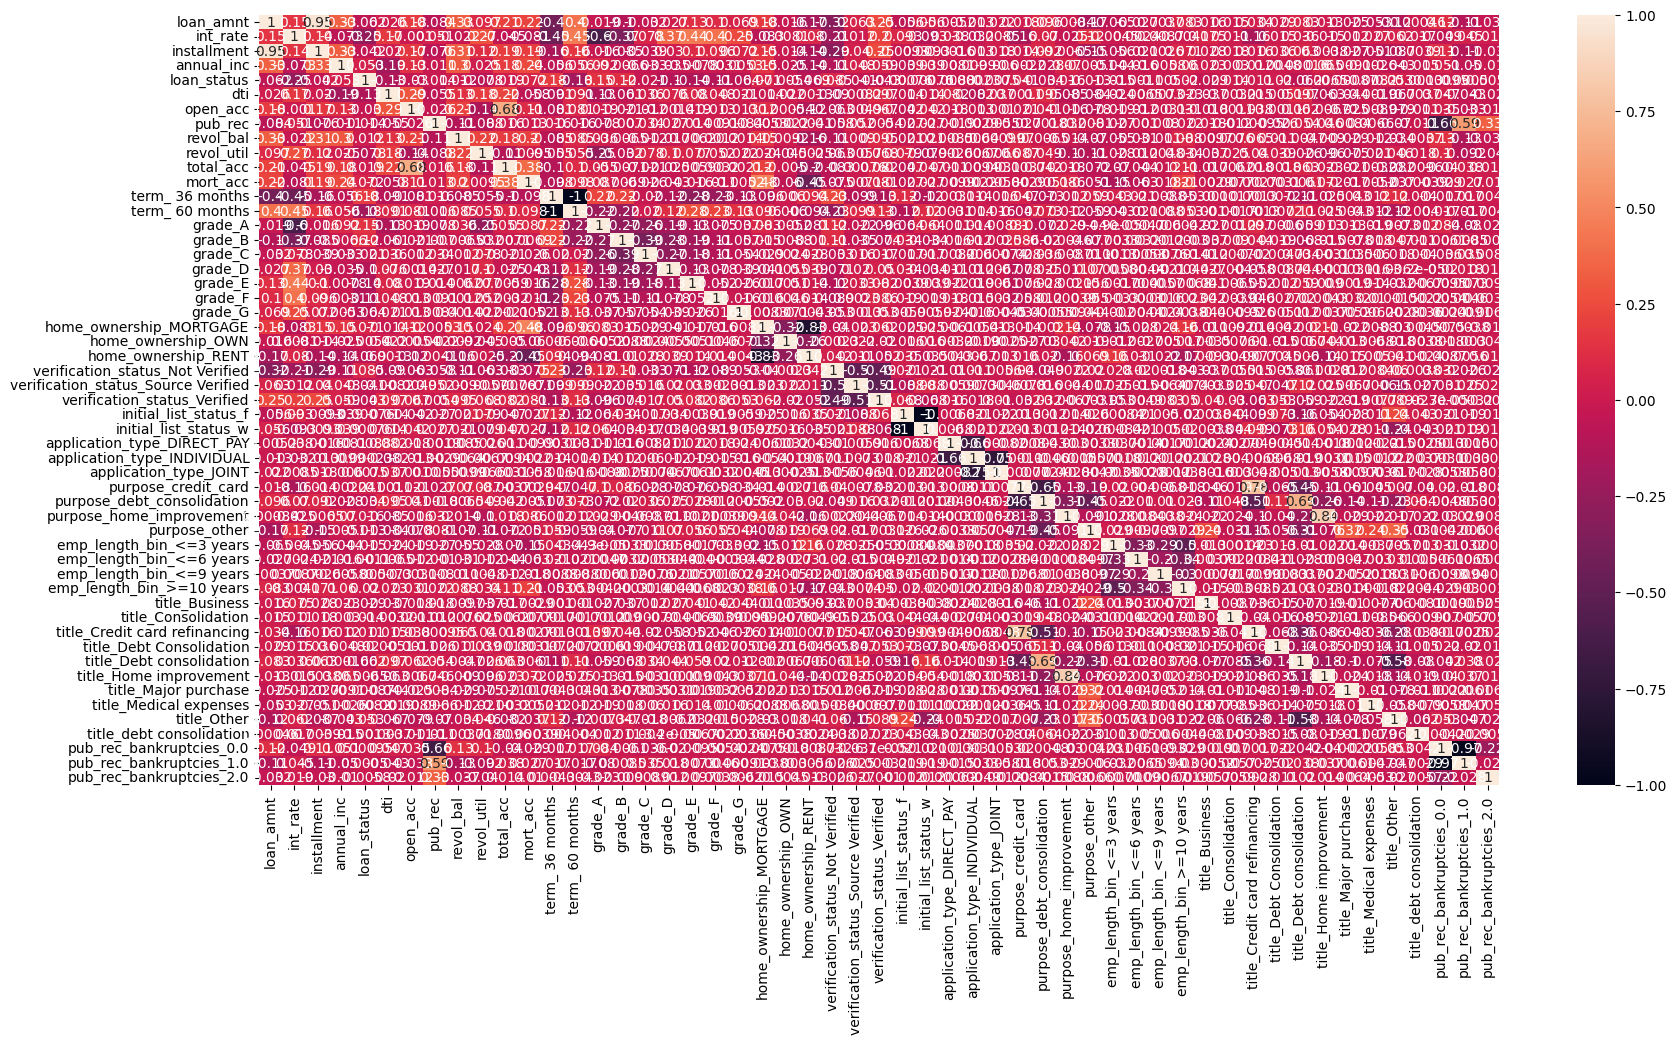

In [66]:
import seaborn as sns
plt.figure(figsize=(20,10))
sns.heatmap(df_transformed.corr() , annot=True)

In [67]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 53 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   loan_amnt                            335808 non-null  float64
 1   int_rate                             335808 non-null  float64
 2   installment                          335808 non-null  float64
 3   annual_inc                           335808 non-null  float64
 4   loan_status                          335808 non-null  int64  
 5   dti                                  335808 non-null  float64
 6   open_acc                             335808 non-null  float64
 7   pub_rec                              335808 non-null  float64
 8   revol_bal                            335808 non-null  float64
 9   revol_util                           335808 non-null  float64
 10  total_acc                            335808 non-null  float64
 11  mort_acc          

<Axes: xlabel='loan_amnt', ylabel='Count'>

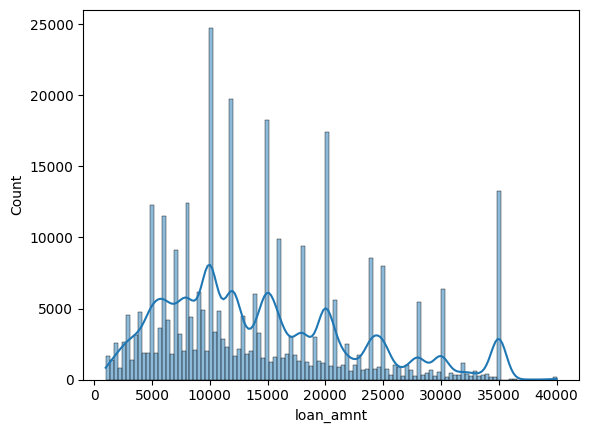

In [68]:
sns.histplot(x="loan_amnt" , data=df_transformed , kde=True)

In [69]:
def boxplot(feature):
  sns.boxplot(x=feature , data=df_transformed)


#boxplot("loan_amnt")


In [70]:
#boxplot("int_rate")

In [71]:
#boxplot("installment")


In [72]:
#boxplot("annual_inc")
#sns.histplot(x="annual_inc" , data=df_transformed,kde=True)


In [73]:
#boxplot("dti")

In [74]:
#boxplot("open_acc")

In [75]:
#boxplot("revol_bal")

In [76]:
#boxplot("revol_util")

In [77]:
#boxplot("total_acc")

In [78]:
#boxplot("mort_acc")


In [79]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 53 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   loan_amnt                            335808 non-null  float64
 1   int_rate                             335808 non-null  float64
 2   installment                          335808 non-null  float64
 3   annual_inc                           335808 non-null  float64
 4   loan_status                          335808 non-null  int64  
 5   dti                                  335808 non-null  float64
 6   open_acc                             335808 non-null  float64
 7   pub_rec                              335808 non-null  float64
 8   revol_bal                            335808 non-null  float64
 9   revol_util                           335808 non-null  float64
 10  total_acc                            335808 non-null  float64
 11  mort_acc          

In [80]:
import matplotlib.pyplot as plt

def outliers_removal(feature):

  # 🔹 Step 2: Calculate IQR
  Q1 = df_transformed[feature].quantile(0.25)
  Q3 = df_transformed[feature].quantile(0.75)
  IQR = Q3 - Q1

  # 🔹 Step 3: Define bounds for non-outliers
  lower_bound = Q1 - 1.5 * IQR
  upper_bound = Q3 + 1.5 * IQR

  # 🔹 Step 4: Remove outliers
  df_no_outliers = df_transformed[(df_transformed[feature] >= lower_bound) & (df_transformed[feature] <= upper_bound)]

  sns.boxplot(x=feature , data=df_no_outliers)



#  outliers_removal("loan_amnt")



In [81]:
#outliers_removal("total_acc")


In [82]:
#outliers_removal("annual_inc")

In [83]:
#outliers_removal("dti")

In [84]:
#outliers_removal("open_acc")

In [85]:
#outliers_removal("revol_bal")

In [86]:
#outliers_removal("revol_util")

In [87]:
#outliers_removal("int_rate")

In [88]:
#outliers_removal("mort_acc")

In [89]:
df_transformed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 335808 entries, 0 to 396028
Data columns (total 53 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   loan_amnt                            335808 non-null  float64
 1   int_rate                             335808 non-null  float64
 2   installment                          335808 non-null  float64
 3   annual_inc                           335808 non-null  float64
 4   loan_status                          335808 non-null  int64  
 5   dti                                  335808 non-null  float64
 6   open_acc                             335808 non-null  float64
 7   pub_rec                              335808 non-null  float64
 8   revol_bal                            335808 non-null  float64
 9   revol_util                           335808 non-null  float64
 10  total_acc                            335808 non-null  float64
 11  mort_acc          

In [90]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


# Separate features and target
X = df_transformed.drop("loan_status", axis=1)
y = df_transformed["loan_status"]



In [91]:
y.value_counts()

,count
loan_status,
1,269509
0,66299


In [92]:
pip install imbalanced-learn

In [93]:
from imblearn.over_sampling import SMOTE

In [94]:
# Step 1: Split original data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# Step 2: Apply SMOTE ONLY on training data
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy="minority", random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [95]:
y_train_sm.value_counts() , y_train.value_counts() , y_test.value_counts()

(loan_status
 1    202132
 0    202132
 Name: count, dtype: int64,
 loan_status
 1    202132
 0     49724
 Name: count, dtype: int64,
 loan_status
 1    67377
 0    16575
 Name: count, dtype: int64)

# **Logistic Regression with unbalanced data**

In [96]:
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=2000))
])

# Define hyperparameter grid
param_grid = {
    "logreg__C": [10],       # Regularization strength
    "logreg__penalty": ["l2"],             # L2 penalty works with 'lbfgs'
    "logreg__solver": ["lbfgs"]
}

# Grid search with cross-validation
grid = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train, y_train)

# Best model
best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)
print("Best F1 Score:", grid.best_score_)

# Predictions
y_pred = best_model.predict(X_test)
y_pred_train=best_model.predict(X_train)


# print(classification_report(y_test, y_pred))


Best Parameters: {'logreg__C': 10, 'logreg__penalty': 'l2', 'logreg__solver': 'lbfgs'}
Best F1 Score: 0.8905494635957641


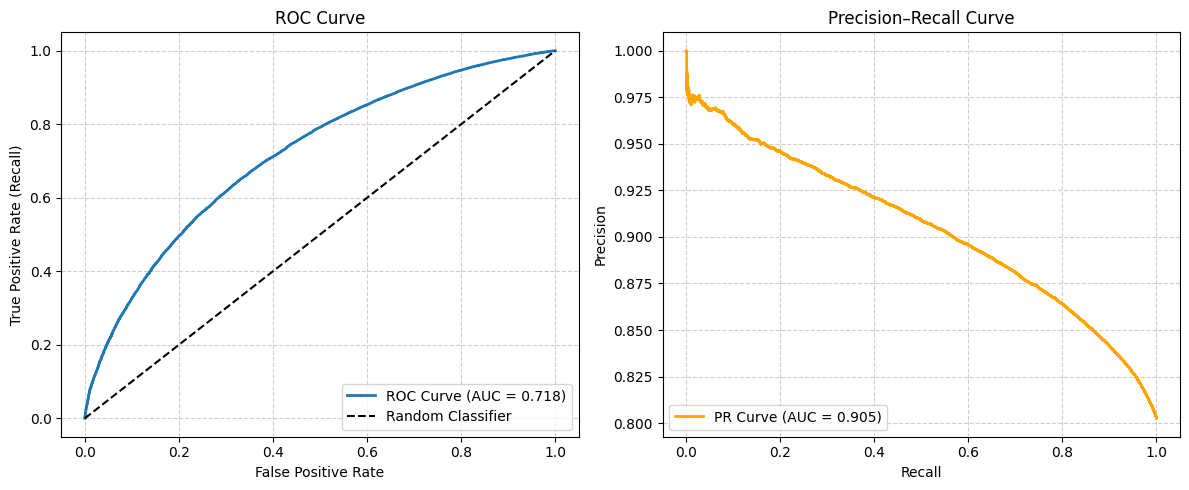

In [97]:
y_prob_unbalanced=best_model.predict_proba(X_test)[:,1]
y_prob_unbalanced_train=best_model.predict_proba(X_train)[:,1]

import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# -------------------------------------------------------------
# y_test  → true binary labels (0 or 1)
# y_prob  → predicted probabilities from your model (model.predict)
# -------------------------------------------------------------

# Example: use your own
# y_prob = model.predict(X_test).ravel()

# --- ROC Curve ---
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob_unbalanced)
roc_auc = roc_auc_score(y_test, y_prob_unbalanced)

# --- Precision-Recall Curve ---
precision, recall, pr_thresh = precision_recall_curve(y_test, y_prob_unbalanced)
pr_auc = average_precision_score(y_test, y_prob_unbalanced)

# --- Plotting ---
plt.figure(figsize=(12, 5))

# ---- Subplot 1: ROC Curve ----
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

# ---- Subplot 2: Precision-Recall Curve ----
plt.subplot(1, 2, 2)
plt.plot(recall, precision, label=f"PR Curve (AUC = {pr_auc:.3f})", linewidth=2, color="orange")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend(loc="lower left")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


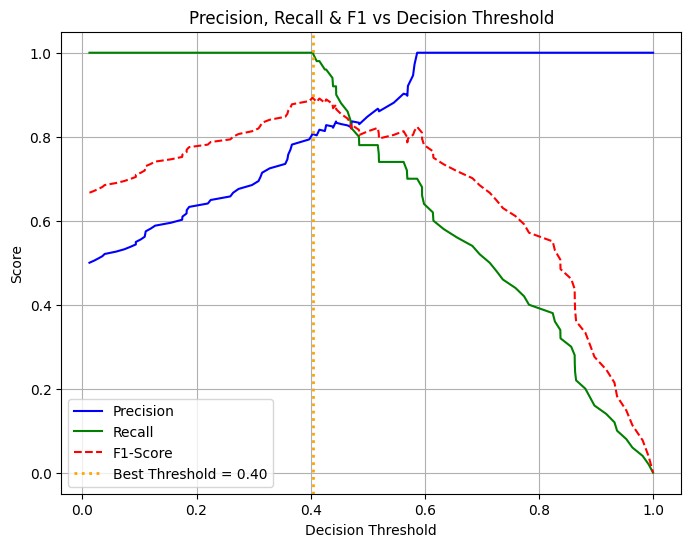

✅ Best Threshold based on F1-Score: 0.40


In [98]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# Simulate data (you can replace this with your real y_true and y_prob)
np.random.seed(42)
y_test = np.concatenate([np.zeros(50), np.ones(50)])  # true labels
y_prob_unbalanced = np.concatenate([np.random.uniform(0, 0.6, 50), np.random.uniform(0.4, 1, 50)])  # predicted probs

# --- Compute precision, recall, and thresholds ---
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_unbalanced)
thresholds = np.append(thresholds, 1.0)  # add 1.0 for equal length with precision & recall

# --- Compute F1 for each threshold ---
f1_scores = 2 * (precision * recall) / (precision + recall)
f1_scores = np.nan_to_num(f1_scores)  # replace NaNs with 0

# --- Find the best threshold (max F1) ---
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

# --- Plot Precision, Recall, and F1 ---
plt.figure(figsize=(8,6))
plt.plot(thresholds, precision, label="Precision", color='blue')
plt.plot(thresholds, recall, label="Recall", color='green')
plt.plot(thresholds, f1_scores, label="F1-Score", color='red', linestyle='--')

# Highlight best threshold
plt.axvline(best_threshold, color='orange', linestyle=':', linewidth=2,
            label=f"Best Threshold = {best_threshold:.2f}")
plt.title("Precision, Recall & F1 vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

print(f"✅ Best Threshold based on F1-Score: {best_threshold:.2f}")

In [99]:
y_pred_best = (y_prob_unbalanced >= 0.4).astype(int)

y_prob_unbalanced_train=best_model.predict_proba(X_train)[:,1]
y_pred_best_train=(y_prob_unbalanced_train >= 0.4).astype(int)
print(classification_report(y_test, y_pred_best))
print(classification_report(y_train,y_pred_best_train))

              precision    recall  f1-score   support

         0.0       1.00      0.76      0.86        50
         1.0       0.81      1.00      0.89        50

    accuracy                           0.88       100
   macro avg       0.90      0.88      0.88       100
weighted avg       0.90      0.88      0.88       100

              precision    recall  f1-score   support

           0       0.64      0.01      0.02     49724
           1       0.80      1.00      0.89    202132

    accuracy                           0.80    251856
   macro avg       0.72      0.50      0.46    251856
weighted avg       0.77      0.80      0.72    251856



# **Logistic Regression with Balanced data after SMOTE**

In [101]:
# Step 1: Split original data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# Step 2: Apply SMOTE ONLY on training data
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy="minority", random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [102]:
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("logreg", LogisticRegression(max_iter=2000))
])

# Define hyperparameter grid
param_grid = {
    "logreg__C": [0.1,0.01 , 1,10],       # Regularization strength
    "logreg__penalty": ["l2"],             # L2 penalty works with 'lbfgs'
    "logreg__solver": ["lbfgs", "liblinear"]
}

# Grid search with cross-validation
grid = GridSearchCV(pipeline, param_grid, cv=5, scoring="f1", n_jobs=-1)
grid.fit(X_train_sm, y_train_sm)

# Best model
best_model = grid.best_estimator_
print("Best Parameters:", grid.best_params_)
print("Best F1 Score:", grid.best_score_)

# Predictions
y_pred = best_model.predict(X_test)


print(classification_report(y_test, y_pred))

Best Parameters: {'logreg__C': 10, 'logreg__penalty': 'l2', 'logreg__solver': 'lbfgs'}
Best F1 Score: 0.6601427170238828
              precision    recall  f1-score   support

           0       0.32      0.67      0.43     16575
           1       0.89      0.65      0.75     67377

    accuracy                           0.66     83952
   macro avg       0.60      0.66      0.59     83952
weighted avg       0.78      0.66      0.69     83952



In [ ]:
y_prob=best_model.predict_proba(X_test)[:,1]


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# -------------------------------------------------------------
# y_test  → true binary labels (0 or 1)
# y_prob  → predicted probabilities from your model (model.predict)
# -------------------------------------------------------------

# Example: use your own
# y_prob = model.predict(X_test).ravel()

# --- ROC Curve ---
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob)
roc_auc = roc_auc_score(y_test, y_prob)

# --- Precision-Recall Curve ---
precision, recall, pr_thresh = precision_recall_curve(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

# --- Plotting ---
plt.figure(figsize=(12, 5))

# ---- Subplot 1: ROC Curve ----
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

# ---- Subplot 2: Precision-Recall Curve ----
plt.subplot(1, 2, 2)
plt.plot(recall, precision, label=f"PR Curve (AUC = {pr_auc:.3f})", linewidth=2, color="orange")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend(loc="lower left")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()


Previous train
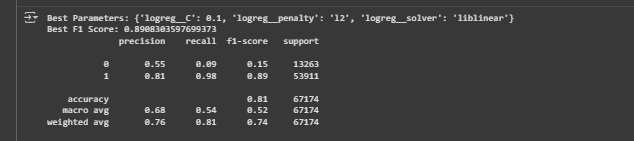

# **THRESHOLD vs F1Score vs Recall vs Precision**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# Simulate data (you can replace this with your real y_true and y_prob)
np.random.seed(42)
y_test = np.concatenate([np.zeros(50), np.ones(50)])  # true labels
y_prob = np.concatenate([np.random.uniform(0, 0.6, 50), np.random.uniform(0.4, 1, 50)])  # predicted probs

# --- Compute precision, recall, and thresholds ---
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
thresholds = np.append(thresholds, 1.0)  # add 1.0 for equal length with precision & recall

# --- Compute F1 for each threshold ---
f1_scores = 2 * (precision * recall) / (precision + recall)
f1_scores = np.nan_to_num(f1_scores)  # replace NaNs with 0

# --- Find the best threshold (max F1) ---
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

# --- Plot Precision, Recall, and F1 ---
plt.figure(figsize=(8,6))
plt.plot(thresholds, precision, label="Precision", color='blue')
plt.plot(thresholds, recall, label="Recall", color='green')
plt.plot(thresholds, f1_scores, label="F1-Score", color='red', linestyle='--')

# Highlight best threshold
plt.axvline(best_threshold, color='orange', linestyle=':', linewidth=2,
            label=f"Best Threshold = {best_threshold:.2f}")
plt.title("Precision, Recall & F1 vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

print(f"✅ Best Threshold based on F1-Score: {best_threshold:.2f}")


# **Model build with best Threshold**

# **a. Code to find best Threshold**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import precision_recall_curve, f1_score, confusion_matrix, ConfusionMatrixDisplay

# --- Simulated data (replace these with your real model outputs) ---
np.random.seed(42)
y_true = np.concatenate([np.zeros(50), np.ones(50)])  # true labels
y_prob = np.concatenate([np.random.uniform(0, 0.6, 50), np.random.uniform(0.4, 1, 50)])  # predicted probabilities

# --- Compute precision, recall, thresholds ---
precision, recall, thresholds = precision_recall_curve(y_true, y_prob)
thresholds = np.append(thresholds, 1.0)  # to match array lengths

# --- Compute F1 for each threshold ---
f1_scores = 2 * (precision * recall) / (precision + recall)
f1_scores = np.nan_to_num(f1_scores)

# --- Find the best threshold (maximum F1) ---
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]
print(f"✅ Best Threshold based on F1-Score: {best_threshold:.2f}")

# --- Predictions ---
y_pred_default = (y_prob >= 0.5).astype(int)
y_pred_best = (y_prob >= best_threshold).astype(int)

# --- Confusion Matrices ---
cm_default = confusion_matrix(y_true, y_pred_default)
cm_best = confusion_matrix(y_true, y_pred_best)

# --- Plot Precision, Recall, and F1 vs Threshold ---
plt.figure(figsize=(8,6))
plt.plot(thresholds, precision, label="Precision", color='blue')
plt.plot(thresholds, recall, label="Recall", color='green')
plt.plot(thresholds, f1_scores, label="F1-Score", color='red', linestyle='--')
plt.axvline(best_threshold, color='orange', linestyle=':', linewidth=2, label=f"Best Threshold = {best_threshold:.2f}")
plt.title("Precision, Recall & F1 vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(True)
plt.show()

# --- Display Confusion Matrices Side by Side ---
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

sns.heatmap(cm_default, annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Confusion Matrix (Default Threshold = 0.5)")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title(f"Confusion Matrix (Optimized Threshold = {best_threshold:.2f})")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()


In [ ]:
y_pred_best = (y_prob >= 0.4).astype(int)

In [ ]:

print(classification_report(y_test, y_pred_best))

In [ ]:
y_train_sm.value_counts()

In [ ]:
y_train_prob = best_model.predict_proba(X_train)[:,1]
y_pred_best_train = (y_train_prob >= 0.4).astype(int)

print(classification_report(y_train, y_pred_best_train))

In [ ]:
pp

# **SEQUENTIAL Neural Network**

In [ ]:
y_train_sm.value_counts()

In [ ]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

model = Sequential([
    Dense(64, activation="relu", input_shape=(X_train.shape[1],)),  # hidden layer 1
    Dense(32, activation="relu"),# hidden layer 2
    Dense(16, activation="relu"),#hidden layer 3
    Dense(1, activation="sigmoid")                                  # output layer
])


model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

history = model.fit(X_train_sm, y_train_sm, epochs=200, batch_size=100, validation_split=0.2, verbose=0)


# ------------------------------
y_prob = model.predict(X_test)          # probabilities
y_pred = (y_prob >= 0.5).astype(int)    # convert to 0/1

print(classification_report(y_test, y_pred))

In [ ]:
# from threading import main_thread
# import tensorflow as tf
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense
# from tensorflow.keras.optimizers import Adam
# from tensorflow.keras.callbacks import EarlyStopping
# from tensorflow.keras.callbacks import ModelCheckpoint
# from tensorflow.keras.metrics import AUC


# def build_regression_model(n_features, n_hidden1=64, n_hidden2=32,n_hidden3=16,n_hidden4=8, learning_rate=0.001):
#     """
#     Build a Sequential Neural Network for regression.

#     Parameters:
#     -----------
#     n_features : int
#         Number of input features
#     n_hidden1 : int
#         Number of neurons in the first hidden layer
#     n_hidden2 : int
#         Number of neurons in the second hidden layer
#     learning_rate : float
#         Learning rate for the optimizer
#     """

#     model = Sequential([
#         Dense(n_hidden1, activation="relu", input_shape=(X_train.shape[1],)),  # Hidden Layer 1
#         Dense(n_hidden2, activation='relu'),                             # Hidden Layer 2
#         Dense(n_hidden3,activation ="relu"),
#         Dense(n_hidden4, activation='relu'),
#         Dense(1, activation='sigmoid')                                    # Output Layer (regression)
#     ])

#     # Compile with MSE loss for regression
#     model.compile(optimizer=Adam(learning_rate=learning_rate),
#                   loss="binary_crossentropy",
#                   metrics=["accuracy", AUC(name="auc")])

#     return model


# # Example usage:
# # Assume we have 10 input features
# n_features = 17
# model = build_regression_model(n_features, n_hidden1=64, n_hidden2=32 , n_hidden3=16 , n_hidden4=8)
# early_stop = EarlyStopping(
#     monitor="val_loss",    # what to monitor (val_loss is common)
#     patience=20,            # number of epochs with no improvement before stopping
#     restore_best_weights=True,
#     min_delta=0,
#     verbose=1# revert to the best weights
# )

# checkpoint = ModelCheckpoint(
#     filepath='best_model.h5',
#     monitor='val_loss',
#     save_best_only=True,   # only keep the best model
#     verbose=1
# )

# model.fit(X_train, y_train, epochs=100, batch_size=1138, validation_split=0.2 , callbacks=[early_stop , checkpoint])
# y_test_pred_nn = model.predict(X_test)
# y_train_pred_nn = model.predict(X_train)
# print(classification_report(y_test, y_pred))



# **Functional NN**

# **sequential plus SMOTE**

In [ ]:
# from threading import main_thread
# import tensorflow as tf
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import Dense
# from tensorflow.keras.optimizers import Adam
# from tensorflow.keras.callbacks import EarlyStopping
# from tensorflow.keras.callbacks import ModelCheckpoint
# from tensorflow.keras.metrics import AUC


# def build_regression_model(n_features, n_hidden1=64, n_hidden2=32,n_hidden3=16,n_hidden4=8, learning_rate=0.001):
#     """
#     Build a Sequential Neural Network for regression.

#     Parameters:
#     -----------
#     n_features : int
#         Number of input features
#     n_hidden1 : int
#         Number of neurons in the first hidden layer
#     n_hidden2 : int
#         Number of neurons in the second hidden layer
#     learning_rate : float
#         Learning rate for the optimizer
#     """

#     model = Sequential([
#         Dense(n_hidden1, activation="relu", input_shape=(X_res.shape[1],)),  # Hidden Layer 1
#         Dense(n_hidden2, activation='relu'),                             # Hidden Layer 2
#         Dense(n_hidden3,activation ="relu"),
#         Dense(n_hidden4, activation='relu'),
#         Dense(1, activation='sigmoid')                                    # Output Layer (regression)
#     ])

#     # Compile with MSE loss for regression
#     model.compile(optimizer=Adam(learning_rate=learning_rate),
#                   loss="binary_crossentropy",
#                   metrics=["accuracy"])

#     return model


# # Example usage:
# # Assume we have 10 input features
# n_features = 17
# model = build_regression_model(n_features, n_hidden1=64, n_hidden2=32 , n_hidden3=16 , n_hidden4=8)
# early_stop = EarlyStopping(
#     monitor="val_loss",    # what to monitor (val_loss is common)
#     patience=20,            # number of epochs with no improvement before stopping
#     restore_best_weights=True,
#     min_delta=0,
#     verbose=1# revert to the best weights
# )

# checkpoint = ModelCheckpoint(
#     filepath='best_model.h5',
#     monitor='val_loss',
#     save_best_only=True,   # only keep the best model
#     verbose=1
# )

# model.fit(X_train, y_train, epochs=100, batch_size=1138, validation_split=0.2 , callbacks=[early_stop , checkpoint])
# y_test_pred_nn = model.predict(X_test)
# y_train_pred_nn = model.predict(X_train)
# print(classification_report(y_test, y_pred))

In [ ]:
y_train.value_counts()

Standard scaling the data

In [103]:
# Step 1: Split original data
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42)

# Step 2: Apply SMOTE ONLY on training data
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy="minority", random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [104]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train_sm)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

In [105]:
y_train.value_counts() , y_train_sm.value_counts()

(loan_status
 1    202132
 0     49724
 Name: count, dtype: int64,
 loan_status
 1    202132
 0    202132
 Name: count, dtype: int64)

In [106]:
X_train_sm.shape , y_train_sm.shape

((404264, 52), (404264,))

In [107]:
X_train_scaled.shape

(404264, 52)

In [108]:
y_train.shape

(251856,)

# **Functional plus SMOTE**

In [109]:
import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras import metrics
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.callbacks import ModelCheckpoint
# ---------------- Define Input ----------------
# Suppose input data has 10 features
inputs = Input(shape=(X_train_scaled.shape[1],), name="input_layer")

# ---------------- Hidden Layers ----------------
hidden1 = layers.Dense(64, activation="relu", name="hidden_layer1")(inputs)
hidden2 = layers.Dense(32, activation="relu", name="hidden_layer2")(hidden1)
hidden3= layers.Dense(16, activation="relu", name="hidden_layer3")(hidden2)
hidden4= layers.Dense(8, activation="relu", name="hidden_layer4")(hidden3)
# ---------------- Output Layer ----------------
# Regression → Linear activation (default)
outputs = layers.Dense(1, activation="sigmoid", name="output_layer")(hidden4)

# ---------------- Build Model ----------------
model = Model(inputs=inputs, outputs=outputs, name="functional_nn")

# ---------------- Compile ----------------
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy",metrics.Precision(), metrics.Recall(), metrics.AUC()])
model.summary()



early_stop = EarlyStopping(
    monitor="val_loss",    # what to monitor (val_loss is common)
    patience=10,            # number of epochs with no improvement before stopping
    restore_best_weights=True,
    min_delta=0,
    verbose=1# revert to the best weights
)

checkpoint = ModelCheckpoint(
    filepath='best_model.h5',
    monitor='accuracy',
    save_best_only=True,   # only keep the best model
    verbose=1
)

#model.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=10000,callbacks=[early_stop , checkpoint], verbose=1)
model.fit(X_train_scaled, y_train_sm, validation_split=0.2, epochs=10, batch_size=256,callbacks=[early_stop , checkpoint], verbose=1)

from tensorflow.keras.models import load_model
best_model_nn = load_model('best_model.h5')
y_prob_nn = best_model_nn.predict(X_test_scaled)
y_pred_test = (y_prob_nn >= 0.5).astype(int)



Model: "functional_nn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 52)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer1 (Dense)           │ (None, 64)             │         3,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer2 (Dense)           │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer3 (Dense)           │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer4 (Dense)           │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,145 (24.00 KB)

 Trainable params: 6,145 (24.00 KB)

 Non-trainable params: 0 (0.00 B)

...

1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8214 - auc: 0.8666 - loss: 0.3918 - precision: 0.7970 - recall: 0.9588 - val_accuracy: 0.8997 - val_auc: 0.0000e+00 - val_loss: 0.1700 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 8/10
1248/1264 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8237 - auc: 0.8684 - loss: 0.3880 - precision: 0.7982 - recall: 0.9610
Epoch 8: accuracy improved from 0.82155 to 0.82287, saving model to best_model.h5


1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8237 - auc: 0.8684 - loss: 0.3880 - precision: 0.7982 - recall: 0.9610 - val_accuracy: 0.8610 - val_auc: 0.0000e+00 - val_loss: 0.2318 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 9/10
1263/1264 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8237 - auc: 0.8680 - loss: 0.3885 - precision: 0.7971 - recall: 0.9626
Epoch 9: accuracy improved from 0.82287 to 0.82357, saving model to best_model.h5


1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8237 - auc: 0.8680 - loss: 0.3885 - precision: 0.7971 - recall: 0.9626 - val_accuracy: 0.9107 - val_auc: 0.0000e+00 - val_loss: 0.1497 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 10/10
1241/1264 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8249 - auc: 0.8697 - loss: 0.3858 - precision: 0.7991 - recall: 0.9618
Epoch 10: accuracy improved from 0.82357 to 0.82438, saving model to best_model.h5


1264/1264 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.8249 - auc: 0.8697 - loss: 0.3858 - precision: 0.7991 - recall: 0.9618 - val_accuracy: 0.8930 - val_auc: 0.0000e+00 - val_loss: 0.1720 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Restoring model weights from the end of the best epoch: 9.


2624/2624 ━━━━━━━━━━━━━━━━━━━━ 2s 886us/step


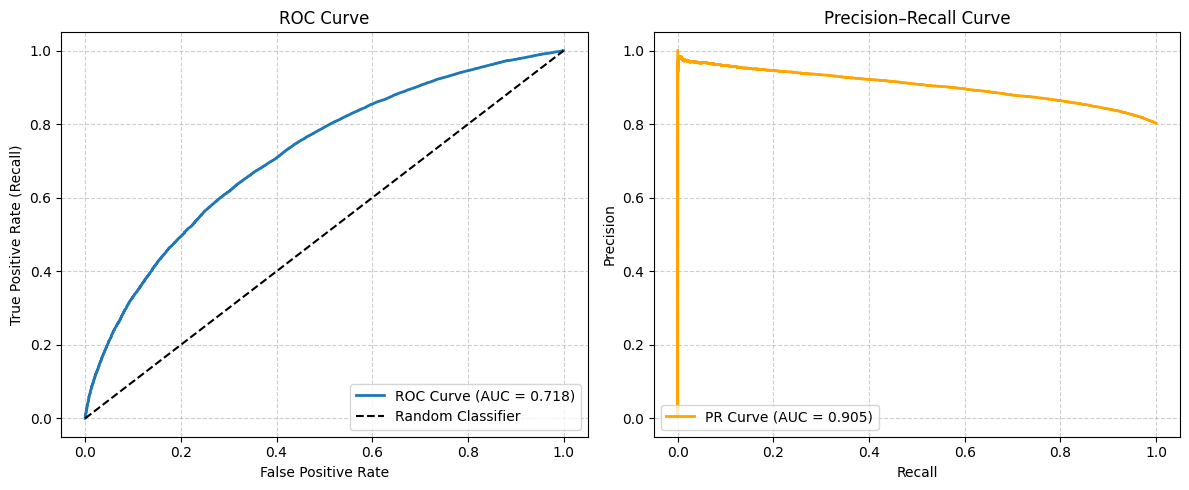

In [110]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# -------------------------------------------------------------
# y_test  → true binary labels (0 or 1)
# y_prob  → predicted probabilities from your model (model.predict)
# -------------------------------------------------------------

# Example: use your own
# y_prob = model.predict(X_test).ravel()

# --- ROC Curve ---
fpr, tpr, roc_thresh = roc_curve(y_test, y_prob_nn)
roc_auc = roc_auc_score(y_test, y_prob_nn)

# --- Precision-Recall Curve ---
precision, recall, pr_thresh = precision_recall_curve(y_test, y_prob_nn)
pr_auc = average_precision_score(y_test, y_prob_nn)

# --- Plotting ---
plt.figure(figsize=(12, 5))

# ---- Subplot 1: ROC Curve ----
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, label=f"ROC Curve (AUC = {roc_auc:.3f})", linewidth=2)
plt.plot([0, 1], [0, 1], 'k--', label="Random Classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend(loc="lower right")
plt.grid(True, linestyle="--", alpha=0.6)

# ---- Subplot 2: Precision-Recall Curve ----
plt.subplot(1, 2, 2)
plt.plot(recall, precision, label=f"PR Curve (AUC = {pr_auc:.3f})", linewidth=2, color="orange")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve")
plt.legend(loc="lower left")
plt.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

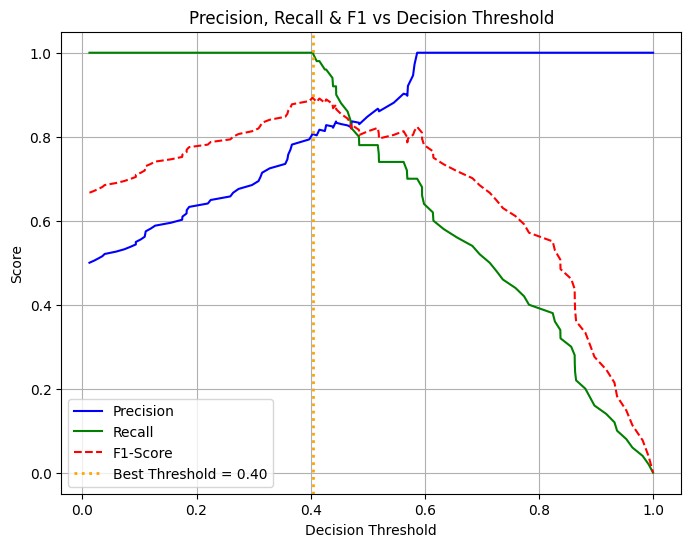

✅ Best Threshold based on F1-Score: 0.40


In [111]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, f1_score

# Simulate data (you can replace this with your real y_true and y_prob)
np.random.seed(42)
y_test = np.concatenate([np.zeros(50), np.ones(50)])  # true labels
y_prob_nn = np.concatenate([np.random.uniform(0, 0.6, 50), np.random.uniform(0.4, 1, 50)])  # predicted probs

# --- Compute precision, recall, and thresholds ---
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_nn)
thresholds = np.append(thresholds, 1.0)  # add 1.0 for equal length with precision & recall

# --- Compute F1 for each threshold ---
f1_scores = 2 * (precision * recall) / (precision + recall)
f1_scores = np.nan_to_num(f1_scores)  # replace NaNs with 0

# --- Find the best threshold (max F1) ---
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

# --- Plot Precision, Recall, and F1 ---
plt.figure(figsize=(8,6))
plt.plot(thresholds, precision, label="Precision", color='blue')
plt.plot(thresholds, recall, label="Recall", color='green')
plt.plot(thresholds, f1_scores, label="F1-Score", color='red', linestyle='--')

# Highlight best threshold
plt.axvline(best_threshold, color='orange', linestyle=':', linewidth=2,
            label=f"Best Threshold = {best_threshold:.2f}")
plt.title("Precision, Recall & F1 vs Decision Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.legend(loc="best")
plt.grid(True)
plt.show()

print(f"✅ Best Threshold based on F1-Score: {best_threshold:.2f}")


In [112]:
y_pred_best_nn = (y_prob_nn >= 0.4).astype(int)

print(classification_report(y_test, y_pred_best_nn))

              precision    recall  f1-score   support

         0.0       1.00      0.76      0.86        50
         1.0       0.81      1.00      0.89        50

    accuracy                           0.88       100
   macro avg       0.90      0.88      0.88       100
weighted avg       0.90      0.88      0.88       100



In [114]:
y_pred_best_nn = (y_prob_nn >= 0.8).astype(int)

print(classification_report(y_test, y_pred_best_nn))

              precision    recall  f1-score   support

         0.0       0.62      1.00      0.76        50
         1.0       1.00      0.38      0.55        50

    accuracy                           0.69       100
   macro avg       0.81      0.69      0.66       100
weighted avg       0.81      0.69      0.66       100



In [116]:
y_pred_best_nn = (y_prob_nn >= 0.35).astype(int)

print(classification_report(y_test, y_pred_best_nn))

              precision    recall  f1-score   support

         0.0       1.00      0.64      0.78        50
         1.0       0.74      1.00      0.85        50

    accuracy                           0.82       100
   macro avg       0.87      0.82      0.81       100
weighted avg       0.87      0.82      0.81       100



In [113]:
y_prob_nn_train = best_model_nn.predict(X_train_scaled)
y_pred_train= (y_prob_nn_train >= 0.4).astype(int)
print(classification_report(y_train_sm, y_pred_train))


12634/12634 ━━━━━━━━━━━━━━━━━━━━ 9s 710us/step
              precision    recall  f1-score   support

           0       0.99      0.67      0.80    202132
           1       0.75      0.99      0.85    202132

    accuracy                           0.83    404264
   macro avg       0.87      0.83      0.83    404264
weighted avg       0.87      0.83      0.83    404264



https://www.youtube.com/redirect?event=video_description&redir_token=QUFFLUhqazBMVFNfbXZxeEk3Q01kR0VuSTllTW02cE1XUXxBQ3Jtc0tuRE1lYmhRYlB4WW9wcFlVSF9YRFdsZElNekYxZko4elVpdElwWk96RUVQdEJkMVRDYVRBZEtzZnE5ek40bzZHd3VXYXhEU1otS3JDaXhzYnBGeG5rSldEM3dFenNUUVlSRXQyR3h0NTUtbVZBS2Yzbw&q=https%3A%2F%2Fgithub.com%2Fcodebasics%2Fdeep-learning-keras-tf-tutorial%2Fblob%2Fmaster%2F14_imbalanced%2Fhandling_imbalanced_data.ipynb&v=JnlM4yLFNuo

# **Hyper Parameter Tuning for ANN**

In [ ]:
# STEP 1: Install required library
# !pip install keras-tuner --quiet

import numpy as np
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.callbacks import EarlyStopping

# STEP 2: Load and preprocess data
# X, y = make_classification(n_samples=1000, n_features=20,
#                            n_informative=15, n_classes=2, random_state=42)

# scaler = StandardScaler()
# X = scaler.fit_transform(X)

# X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# STEP 3: Define the simplified model for tuning
def build_model(hp):
    model = keras.Sequential()

    # First hidden layer
    model.add(layers.Dense(
        units=hp.Int('units_1', min_value=32, max_value=256, step=32),
        activation=hp.Choice('activation_1', values=['relu', 'tanh']),
        input_shape=(X_train.shape[1],)
    ))
    model.add(layers.Dropout(hp.Float('dropout_1', 0.1, 0.5, step=0.1)))

    # Second hidden layer
    model.add(layers.Dense(
        units=hp.Int('units_2', min_value=32, max_value=256, step=32),
        activation=hp.Choice('activation_2', values=['relu', 'tanh'])
    ))
    model.add(layers.Dropout(hp.Float('dropout_2', 0.1, 0.5, step=0.1)))

    # Output layer
    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd']),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

# STEP 4: Initialize the tuner
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,  # Try 10 different sets of hyperparameters
    executions_per_trial=1,
    directory='tuner_dir',
    project_name='ann_simple'
)

# STEP 5: Search for best hyperparameters
tuner.search(
    X_train_sm, y_train_sm,
    validation_data=(X_test, y_test),
    epochs=30,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3)]
)

# STEP 6: Retrieve best model and hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("Best hyperparameters:")
print(best_hp.values)

best_model = tuner.get_best_models(1)[0]

# STEP 7: Evaluate best model
loss, acc = best_model.evaluate(X_test, y_test)
print(f"\nBest model accuracy on validation set: {acc:.4f}")


In [ ]:
# STEP 1: Install if not already
# !pip install keras-tuner --quiet

import numpy as np
import keras_tuner as kt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, Callback
from tensorflow.keras.models import load_model

# STEP 2: Load and preprocess data
X, y = make_classification(n_samples=1000, n_features=20,
                           n_informative=15, n_classes=2, random_state=42)

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# STEP 3: Define model-building function (no loop, 2 layers)
def build_model(hp):
    model = keras.Sequential()

    model.add(layers.Dense(
        units=hp.Int('units_1', 32, 256, step=32),
        activation=hp.Choice('activation_1', ['relu', 'tanh']),
        input_shape=(X_train.shape[1],)
    ))
    model.add(layers.Dropout(hp.Float('dropout_1', 0.1, 0.5, step=0.1)))

    model.add(layers.Dense(
        units=hp.Int('units_2', 32, 256, step=32),
        activation=hp.Choice('activation_2', ['relu', 'tanh'])
    ))
    model.add(layers.Dropout(hp.Float('dropout_2', 0.1, 0.5, step=0.1)))

    model.add(layers.Dense(1, activation='sigmoid'))

    model.compile(
        optimizer=hp.Choice('optimizer', ['adam', 'rmsprop', 'sgd']),
        loss='binary_crossentropy',
        metrics=['accuracy']  # F1 will be added via callback
    )
    return model

# STEP 4: Create custom F1 score callback
class F1ScoreCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        y_pred = (self.model.predict(X_val) > 0.5).astype("int32")
        f1 = f1_score(y_val, y_pred)
        print(f"Epoch {epoch + 1}: val_f1_score = {f1:.4f}")

# STEP 5: Create tuner
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',  # Still using val_accuracy to guide search
    max_trials=10,
    executions_per_trial=1,
    directory='tuner_dir',
    project_name='ann_simple_f1'
)

# STEP 6: Setup callbacks
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

model_checkpoint = ModelCheckpoint(
    filepath='best_model_f1.h5',
    monitor='val_loss',
    mode='min',
    save_best_only=True,
    verbose=1
)

f1_callback = F1ScoreCallback()

# STEP 7: Run hyperparameter search
tuner.search(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    callbacks=[early_stop, model_checkpoint, f1_callback]
)

# STEP 8: Load and evaluate best model
print("\nLoading best model from file...")
best_model = load_model('best_model_f1.h5')

loss, acc = best_model.evaluate(X_val, y_val)
y_pred_final = (best_model.predict(X_val) > 0.5).astype(int)
f1_final = f1_score(y_val, y_pred_final)

print(f"\nFinal validation accuracy: {acc:.4f}")
print(f"Final validation F1 score: {f1_final:.4f}")

# Optional: view best hyperparameters
best_hp = tuner.get_best_hyperparameters(1)[0]
print("\nBest hyperparameters:")
print(best_hp.values)


# **Setting Objective as F1 Score instead of accuracy or val_loss**